<a href="https://colab.research.google.com/github/jungeun1228/2026_02_Tox21_ML_DL/blob/main/2026_Tox21_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [1] Setup


In [2]:
# Windows / VS Code Conda DLL path workaround
import os
import sys
from pathlib import Path

if sys.platform == "win32":
    dll_dir = Path(sys.prefix) / "Library" / "bin"

    if dll_dir.is_dir():
        os.environ["PATH"] = (
            str(dll_dir) + os.pathsep + os.environ["PATH"]
        )

In [3]:
import random
import numpy as np
import pandas as pd

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [4]:
# Locate project root
cwd = Path.cwd()

project_root = (
    cwd if (cwd / "pyproject.toml").is_file()
    else cwd.parent
)

sdf_path = (
    project_root / "data" / "raw"
    / "tox21_10k_data_all.sdf"
)

print("Project root:", project_root)
print("SDF path:", sdf_path)
print("SDF exists:", sdf_path.is_file())
print("ML module exists:", (project_root / "src" / "tox21_ml").is_dir())

Project root: c:\Users\junge\Github_projects\2026_02_Tox21_ML_DL
SDF path: c:\Users\junge\Github_projects\2026_02_Tox21_ML_DL\data\raw\tox21_10k_data_all.sdf
SDF exists: True
ML module exists: True


# [2] Data Loading & Cleaning

In [5]:
from tox21_ml.data import load_sdf

df = load_sdf(sdf_path)

display(df.head())

[09:42:04] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:42:04] ERROR: Could not sanitize molecule ending on line 21572
[09:42:04] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:42:05] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[09:42:05] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[09:42:05] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[09:42:05] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[09:42:07] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:42:07] ERROR: Could not sanitize molecule ending on line 446665
[09:42:07] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:42:07] Explicit valence for atom # 1 Cl, 1, is greater than permitted
[09:42:07] ERROR: Could not sanitize molecule ending on l

,idx,canonical_smiles,status,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,0,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,ok,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,ok,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,ok,C47H83NO17,934.1584 (916.1205+18.0379),28909,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,ok,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,ok,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
from tox21_ml.data import group_and_filter_tox21

df_ok = df[df["status"] == "ok"].copy()

df_grouped, df_filtered, endpoint_column = (group_and_filter_tox21(df_ok))

target_cols = list(endpoint_column)

print("Original molecules:", len(df))
print("Valid molecules:", len(df_ok))
print("Grouped molecules:", len(df_grouped))
print("Filtered molecules:", len(df_filtered))
print("Number of endpoints:", len(target_cols))

Original molecules: 11764
Valid molecules: 11761
Grouped molecules: 8041
Filtered molecules: 8041
Number of endpoints: 12


# [3] Molecular Feature Engineering

In [7]:
# Molecular Feature Engineering
from tox21_ml.features import (
    build_morgan_fp_to_df,
    add_basic_descriptors_to_df,
    build_feature_matrix,
)

df_w_fp = build_morgan_fp_to_df(
    df_filtered,
    smiles_col="canonical_smiles",
)

df_w_fp_desc = add_basic_descriptors_to_df(df_w_fp)

full_valid_df, full_X_df = build_feature_matrix(
    df_w_fp_desc
)

print("Valid molecules:", len(full_valid_df))
print("Feature matrix:", full_X_df.shape)
display(full_X_df.head(3))

[09:42:20] WARNING: not removing hydrogen atom without neighbors
[09:42:25] WARNING: not removing hydrogen atom without neighbors


Valid molecules: 8041
Feature matrix: (8041, 2059)


,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,fp_9,...,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3,HeavyAtomCount,FormalCharge
0,0,1,0,0,0,0,0,0,0,0,...,2.6355,92.95,5.0,5.0,6.0,2.0,2.0,0.294118,23.0,0.0
1,0,1,0,0,0,0,0,0,0,0,...,1.8598,46.25,2.0,2.0,2.0,1.0,1.0,0.333333,12.0,0.0
2,0,0,0,0,0,0,0,0,0,0,...,3.6009,6.48,0.0,2.0,7.0,1.0,0.0,0.833333,15.0,0.0


# [4] Outer Scaffold Holdout Split

In [8]:
# Reuse the scaffold holdout split from traditional ML
from tox21_ml.splitting import load_scaffold_holdout_split

split_path = (
    project_root / "results"
    / "scaffold_split_greedy_v1.csv"
)

train_df, test_df, X_train_all, X_test_all = (
    load_scaffold_holdout_split(
        full_valid_df,
        full_X_df,
        split_path
    )
)

print("Development molecules:", len(train_df))
print("Holdout molecules:", len(test_df))

print("X_train_all:", X_train_all.shape)
print("X_test_all:", X_test_all.shape)

[09:42:29] WARNING: not removing hydrogen atom without neighbors


Development molecules: 6433
Holdout molecules: 1608
X_train_all: (6433, 2059)
X_test_all: (1608, 2059)


In [9]:
# Verify the outer scaffold split

print("Molecule overlap:",
      len(set(train_df["canonical_smiles"])
          & set(test_df["canonical_smiles"])))

print("Scaffold overlap:",
      len(set(train_df["scaffold"])
          & set(test_df["scaffold"])))

print("Train row alignment:",
      train_df.index.equals(X_train_all.index))

print("Test row alignment:",
      test_df.index.equals(X_test_all.index))

Molecule overlap: 0
Scaffold overlap: 0
Train row alignment: True
Test row alignment: True


# [5] Multi-task Scaffold-balanced Cross-Validation

In [10]:
from tox21_dl.splitting import (
    make_multitask_scaffold_folds,
    fold_diagnostics,
    iter_scaffold_cv_indices,
)

N_SPLITS = 5

fold_df = make_multitask_scaffold_folds(
    train_df=train_df,
    target_cols=target_cols,
    n_splits=N_SPLITS,
    random_state=SEED,
)

display(fold_df.head())

,canonical_smiles,scaffold,fold_id
0,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,c1ccc(CCNCCc2ccccc2)cc1,2
1,Br.CC(N)Cc1ccc(O)cc1,c1ccccc1,3
2,Br.CCCCCCCCN1C=CN(C)C1,C1=CNCN1,4
3,Br.CCCCN1C=CN(C)C1,C1=CNCN1,4
4,Br.CCCN1C=CN(C)C1,C1=CNCN1,4


In [11]:
cv_diagnostics_df = fold_diagnostics(
    train_df=train_df,
    target_cols=target_cols,
    fold_df=fold_df,
    n_splits=N_SPLITS,
)

# Number of molecules and scaffolds per fold
display(
    fold_df.groupby("fold_id").agg(
        n_molecules=("canonical_smiles", "size"),
        n_scaffolds=("scaffold", "nunique"),
    )
)

# Positive ratio per endpoint and fold
display(
    cv_diagnostics_df.pivot(
        index="target",
        columns="fold_id",
        values="val_positive_ratio",
    ).round(4)
)

# Check whether ROC-AUC is computable
print(
    "All fold/endpoint combinations valid:",
    cv_diagnostics_df["roc_auc_valid"].all()
)

,n_molecules,n_scaffolds
fold_id,,
0,1010,376
1,1874,39
2,1010,381
3,1529,26
4,1010,379


fold_id,0,1,2,3,4
target,,,,,
NR-AR,0.0542,0.0163,0.0542,0.0246,0.0542
NR-AR-LBD,0.0426,0.0193,0.0426,0.0236,0.0426
NR-AhR,0.1496,0.0259,0.1494,0.1191,0.1508
NR-Aromatase,0.0634,0.0222,0.0646,0.0292,0.0646
NR-ER,0.1362,0.0558,0.1350,0.0959,0.1362
NR-ER-LBD,0.0584,0.0231,0.0573,0.0325,0.0573
NR-PPAR-gamma,0.0290,0.0212,0.0277,0.0167,0.0278
SR-ARE,0.1988,0.0976,0.1988,0.1119,0.1991
SR-ATAD5,0.0391,0.0214,0.0402,0.0229,0.0391


All fold/endpoint combinations valid: True


In [12]:
# Check train / validation sizes
fold_sizes = (
    fold_df.groupby("fold_id")
    .size()
    .rename("n_validation")
    .to_frame()
)

fold_sizes["n_train"] = len(train_df) - fold_sizes["n_validation"]

display(fold_sizes)

# Check the largest scaffold groups
display(
    train_df.groupby("scaffold")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

# Check empty-string scaffold size
print(
    "Empty scaffold molecules:",
    (train_df["scaffold"] == "").sum()
)

,n_validation,n_train
fold_id,,
0,1010,5423
1,1874,4559
2,1010,5423
3,1529,4904
4,1010,5423


scaffold
                                1826
c1ccccc1                        1500
c1ccncc1                          91
c1ccc(Cc2ccccc2)cc1               84
c1c[nH+]c[nH]1                    72
c1ccc2ccccc2c1                    71
C1CCCCC1                          64
c1ccc(-c2ccccc2)cc1               46
c1ccc(Oc2ccccc2)cc1               45
O=C1C=C2CCC3C4CCCC4CCC3C2CC1      43
dtype: int64

Empty scaffold molecules: 1826


In [13]:
# Positive sample counts per endpoint and fold
display(
    cv_diagnostics_df.pivot(
        index="target",
        columns="fold_id",
        values="val_positive",
    )
)

print(
    "Minimum validation positive count:",
    cv_diagnostics_df["val_positive"].min()
)

print(
    "Minimum validation negative count:",
    cv_diagnostics_df["val_negative"].min()
)

fold_id,0,1,2,3,4
target,,,,,
NR-AR,50,29,50,35,50
NR-AR-LBD,36,33,36,32,36
NR-AhR,121,44,121,152,122
NR-Aromatase,45,35,46,34,46
NR-ER,102,89,101,117,102
NR-ER-LBD,51,40,50,45,50
NR-PPAR-gamma,23,36,22,22,22
SR-ARE,137,152,137,139,137
SR-ATAD5,35,38,36,32,35


Minimum validation positive count: 22
Minimum validation negative count: 551


In [14]:
# Save DL-specific scaffold CV assignments and diagnostics

dl_results_dir = project_root / "results" / "deep_learning"
dl_results_dir.mkdir(parents=True, exist_ok=True)

fold_df.to_csv(
    dl_results_dir / "scaffold_cv_folds_v1.csv",
    index=False
)

cv_diagnostics_df.to_csv(
    dl_results_dir / "scaffold_cv_diagnostics_v1.csv",
    index=False
)

# [6] DL Data Preprocessing

In [15]:
from tox21_dl.preprocessing import (
    prepare_fold_data,
)

from tox21_ml.features import DESCRIPTOR_COLS

In [16]:
# Verify fold-specific preprocessing

assert fold_df.index.equals(train_df.index)
assert X_train_all.index.equals(train_df.index)

for col in ["canonical_smiles", "scaffold"]:
    assert fold_df[col].equals(train_df[col])

# Keep a copy to verify that raw features are unchanged
X_raw_check = X_train_all.copy(deep=True)

preprocessing_checks = []

for fold_id, (tr_idx, val_idx) in enumerate(
    iter_scaffold_cv_indices(fold_df)
):
    X_tr, X_val, y_tr, y_val, scaler = prepare_fold_data(
        train_df=train_df,
        X_train_all=X_train_all,
        target_cols=target_cols,
        tr_idx=tr_idx,
        val_idx=val_idx,
    )

    # Check shapes
    assert X_tr.shape == (len(tr_idx), 2059)
    assert X_val.shape == (len(val_idx), 2059)
    assert y_tr.shape == (len(tr_idx), len(target_cols))
    assert y_val.shape == (len(val_idx), len(target_cols))

    # Check data types
    assert all(
        arr.dtype == np.float32
        for arr in [X_tr, X_val, y_tr, y_val]
    )

    # Check fingerprints and label alignment
    for idx, X, y in [
        (tr_idx, X_tr, y_tr),
        (val_idx, X_val, y_val),
    ]:
        assert np.array_equal(
            X[:, :2048],
            X_train_all.iloc[idx, :2048].to_numpy(),
        )

        assert np.array_equal(
            y,
            train_df.iloc[idx][target_cols].to_numpy(
                dtype=np.float32,
                na_value=np.nan,
            ),
            equal_nan=True,
        )

    # Check that the scaler uses training data only
    assert scaler.n_samples_seen_ == len(tr_idx)

    assert np.allclose(
        scaler.mean_,
        X_train_all.iloc[tr_idx][DESCRIPTOR_COLS]
        .mean()
        .to_numpy(),
    )

    preprocessing_checks.append({
        "fold_id": fold_id,
        "n_train": len(X_tr),
        "n_val": len(X_val),
        "n_features": X_tr.shape[1],
        "n_targets": y_tr.shape[1],
        "scaler_fit_samples": scaler.n_samples_seen_,
        "train_missing_labels": np.isnan(y_tr).sum(),
        "val_missing_labels": np.isnan(y_val).sum(),
        "checks_passed": True,
    })

# Verify that raw features remain unchanged
pd.testing.assert_frame_equal(
    X_train_all,
    X_raw_check,
)

del X_raw_check

preprocessing_checks_df = pd.DataFrame(
    preprocessing_checks
)

display(preprocessing_checks_df)

print("All preprocessing checks passed.")
print("Raw feature matrix unchanged:", X_train_all.shape)

,fold_id,n_train,n_val,n_features,n_targets,scaler_fit_samples,train_missing_labels,val_missing_labels,checks_passed
0,0,5423,1010,2059,12,5423.0,10084,2491,True
1,1,4559,1874,2059,12,4559.0,10135,2440,True
2,2,5423,1010,2059,12,5423.0,10085,2490,True
3,3,4904,1529,2059,12,4904.0,9915,2660,True
4,4,5423,1010,2059,12,5423.0,10081,2494,True


All preprocessing checks passed.
Raw feature matrix unchanged: (6433, 2059)


# [7] Dynamic Multi-task MLP

In [17]:
import torch

from tox21_dl.models import Tox21MLP

# Inspect the original two-hidden-layer architecture
model_check = Tox21MLP(
    input_dim=X_train_all.shape[1],
    n_tasks=len(target_cols),
    hidden_dims=(1024, 512),
    dropout=0.3,
)

print(model_check)

Tox21MLP(
  (net): Sequential(
    (0): Linear(in_features=2059, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=512, out_features=12, bias=True)
  )
)


In [18]:
# Verify dynamic MLP architectures

architectures = {
    "Small": (128,),
    "Medium": (256, 128),
    "Large": (1024, 512),
    "Deep": (512, 256, 128),
}

# Use 8 preprocessed molecules
x_sample = torch.from_numpy(X_tr[:8])

architecture_checks = []

for name, hidden_dims in architectures.items():

    torch.manual_seed(SEED)

    model_check = Tox21MLP(
        input_dim=X_train_all.shape[1],
        n_tasks=len(target_cols),
        hidden_dims=hidden_dims,
        dropout=0.3,
    )

    model_check.eval()

    with torch.no_grad():
        logits = model_check(x_sample)

    n_params = sum(
        p.numel()
        for p in model_check.parameters()
        if p.requires_grad
    )

    # Check output shape and numerical validity
    assert logits.shape == (
        len(x_sample), len(target_cols)
    )
    assert torch.isfinite(logits).all()

    architecture_checks.append({
        "architecture": name,
        "hidden_dims": hidden_dims,
        "n_hidden_layers": len(hidden_dims),
        "output_shape": tuple(logits.shape),
        "n_parameters": n_params,
        "checks_passed": True,
    })

architecture_checks_df = pd.DataFrame(
    architecture_checks
)

display(architecture_checks_df)

print("All architecture checks passed.")

,architecture,hidden_dims,n_hidden_layers,output_shape,n_parameters,checks_passed
0,Small,"(128,)",1,"(8, 12)",265484,True
1,Medium,"(256, 128)",2,"(8, 12)",562572,True
2,Large,"(1024, 512)",2,"(8, 12)",2643468,True
3,Deep,"(512, 256, 128)",3,"(8, 12)",1222284,True


All architecture checks passed.


# [8] Masked Loss & Class Weighting

In [19]:
from tox21_dl.losses import (
    compute_pos_weight,
    masked_bce_with_logits_loss,
)

In [20]:
# Inspect endpoint-specific class weights for each CV fold

pos_weight_rows = []

for fold_id, (tr_idx, val_idx) in enumerate(
    iter_scaffold_cv_indices(fold_df)
):
    y_fold_train = train_df.iloc[tr_idx][target_cols].to_numpy(             # Pos_weight 계산에 validation label이나 전체 development label을 사용하지 않음. Descriptor scaling과 마찬가지로 해당 fold의 training partition에서만 계산하는 것이 원칙
        dtype=np.float32,
        na_value=np.nan,
    )

    n_pos = (y_fold_train == 1).sum(axis=0)
    n_neg = (y_fold_train == 0).sum(axis=0)
    n_missing = np.isnan(y_fold_train).sum(axis=0)

    weights_raw = compute_pos_weight(
        y_fold_train, cap=None
    ).numpy()

    weights_capped = compute_pos_weight(
        y_fold_train, cap=10.0
    ).numpy()

    weights_unweighted = compute_pos_weight(
        y_fold_train, cap=1.0
    ).numpy()

    # Check class coverage and weight calculation
    assert np.all(n_pos > 0)
    assert np.all(n_neg > 0)

    assert np.allclose(
        weights_raw, n_neg / n_pos
    )

    assert np.allclose(
        weights_capped,
        np.minimum(weights_raw, 10.0),
    )

    assert np.all(weights_unweighted == 1.0)

    for j, target in enumerate(target_cols):
        pos_weight_rows.append({
            "fold_id": fold_id,
            "target": target,
            "n_positive": n_pos[j],
            "n_negative": n_neg[j],
            "n_missing": n_missing[j],
            "pos_weight_raw": weights_raw[j],
            "pos_weight_capped": weights_capped[j],
            "is_clipped": weights_raw[j] > 10.0,
        })

pos_weight_df = pd.DataFrame(pos_weight_rows)

# Display endpoint-level results for Fold 0
display(
    pos_weight_df[
        pos_weight_df["fold_id"] == 0
    ].round(3)
)

# Summarize class weights across all folds
display(
    pos_weight_df.groupby("fold_id").agg(
        min_pos_weight=("pos_weight_raw", "min"),
        max_pos_weight=("pos_weight_raw", "max"),
        n_clipped_targets=("is_clipped", "sum"),
    ).round(3)
)

print("All pos_weight checks passed.")

,fold_id,target,n_positive,n_negative,n_missing,pos_weight_raw,pos_weight_capped,is_clipped
0,0,SR-HSE,208,4393,822,21.120001,10.000,True
1,0,NR-AR,164,4885,374,29.787001,10.000,True
2,0,SR-ARE,565,3612,1246,6.393000,6.393,False
3,0,NR-Aromatase,161,4007,1255,24.888000,10.000,True
4,0,NR-ER-LBD,185,4679,559,25.292000,10.000,True
5,0,NR-AhR,439,4152,832,9.458000,9.458,False
6,0,SR-MMP,538,3594,1291,6.680000,6.680,False
7,0,NR-ER,409,3904,1110,9.545000,9.545,False
8,0,NR-PPAR-gamma,102,4502,819,44.137001,10.000,True
9,0,SR-p53,222,4552,649,20.504999,10.000,True


,min_pos_weight,max_pos_weight,n_clipped_targets
fold_id,,,
0,6.393,44.137001,8
1,4.585,40.506001,8
2,6.393,43.688999,8
3,5.437,38.602001,8
4,6.395,43.699001,8


All pos_weight checks passed.


In [21]:
# Verify masked BCE with logits
# 단, pos_weight 설정이 다르면 weighted BCE loss의 절대값은 직접 비교하지 않는 것이 좋다.

logits_check = torch.zeros(
    (2, 3),
    requires_grad=True,
)

targets_check = torch.tensor([
    [1.0, float("nan"), 0.0],
    [0.0, 1.0, float("nan")],
])

mask_check = ~torch.isnan(targets_check)

weights_check = torch.tensor([
    2.0, 3.0, 1.0
])

# Calculate masked and weighted BCE
loss_check = masked_bce_with_logits_loss(
    logits=logits_check,
    targets=targets_check,
    mask=mask_check,
    pos_weight=weights_check,
)

# Compare against the manually calculated loss
expected_loss = np.log(2) * 7 / 4

assert torch.isfinite(loss_check)

assert np.isclose(
    loss_check.item(),
    expected_loss,
)

# Check gradients
loss_check.backward()

assert torch.isfinite(logits_check.grad).all()

assert torch.all(
    logits_check.grad[~mask_check] == 0
)

print("Calculated loss:", loss_check.item())
print("Expected loss:", expected_loss)

print("\nGradients:")
print(logits_check.grad)

# Verify an all-missing batch
empty_logits = torch.zeros(
    (2, 3),
    requires_grad=True,
)

empty_targets = torch.full(
    (2, 3), float("nan")
)

empty_mask = ~torch.isnan(empty_targets)

empty_loss = masked_bce_with_logits_loss(
    empty_logits,
    empty_targets,
    empty_mask,
)

assert empty_loss.item() == 0.0

empty_loss.backward()

assert torch.all(empty_logits.grad == 0)

print("\nAll-missing batch loss:", empty_loss.item())
print("All masked loss checks passed.")

Calculated loss: 1.2130075693130493
Expected loss: 1.2130075659799042

Gradients:
tensor([[-0.2500,  0.0000,  0.1250],
        [ 0.1250, -0.3750,  0.0000]])

All-missing batch loss: 0.0
All masked loss checks passed.


# [9] Multi-task Evaluation Metrics

In [22]:
from tox21_dl.evaluation import (
    predict,
    compute_multitask_metrics,
    evaluate_multitask,
)

In [23]:
# Verify multi-task metric calculation

y_metric_check = np.array([
    [1,      0, 1, 0, np.nan],
    [0,      1, 1, 0, np.nan],
    [1,      0, 1, 0, np.nan],
    [0,      1, 1, 0, np.nan],
    [np.nan, 0, 1, 0, np.nan],
], dtype=np.float32)

probs_metric_check = np.array([
    [0.90, 0.10, 0.5, 0.5, 0.5],
    [0.80, 0.90, 0.5, 0.5, 0.5],
    [0.70, 0.20, 0.5, 0.5, 0.5],
    [0.10, 0.80, 0.5, 0.5, 0.5],
    [0.99, 0.30, 0.5, 0.5, 0.5],
])

mask_metric_check = ~np.isnan(y_metric_check)

task_names_check = [
    "Task_A",
    "Task_B",
    "Task_C",
    "Task_D",
    "Task_E",
]

metric_summary = compute_multitask_metrics(
    probs=probs_metric_check,
    y_true=y_metric_check,
    mask=mask_metric_check,
    task_names=task_names_check,
)

metric_check_df = metric_summary["per_task_df"]

display(metric_check_df)

# Check macro averages
assert np.isclose(
    metric_summary["mean_roc_auc"], 0.875
)

assert np.isclose(
    metric_summary["mean_ap"], 11 / 12
)

# Only Task A and Task B are valid
assert metric_summary["n_valid_tasks"] == 2

assert metric_check_df["status"].tolist() == [
    "ok",
    "ok",
    "no_negative_labels",
    "no_positive_labels",
    "no_valid_labels",
]

# Check all-invalid evaluation
invalid_summary = compute_multitask_metrics(
    probs_metric_check,
    y_metric_check,
    np.zeros_like(mask_metric_check),
    task_names_check,
)

assert np.isnan(invalid_summary["mean_roc_auc"])
assert np.isnan(invalid_summary["mean_ap"])

print("Macro ROC-AUC:", metric_summary["mean_roc_auc"])
print("Macro AP:", metric_summary["mean_ap"])
print("All metric checks passed.")

,task,roc_auc,ap,n_valid,n_positive,n_negative,n_missing,positive_ratio,status
0,Task_A,0.75,0.833333,4,2,2,1,0.5,ok
1,Task_B,1.00,1.000000,5,2,3,0,0.4,ok
2,Task_C,NaN,NaN,5,5,0,0,1.0,no_negative_labels
3,Task_D,NaN,NaN,5,0,5,0,0.0,no_positive_labels
4,Task_E,NaN,NaN,0,0,0,5,NaN,no_valid_labels


Macro ROC-AUC: 0.875
Macro AP: 0.9166666666666666
All metric checks passed.


In [24]:
# Verify prediction with preprocessed validation features

from torch.utils.data import DataLoader

x_eval_check = torch.from_numpy(X_val[:9])

y_eval_check = torch.from_numpy(
    np.nan_to_num(y_val[:9], nan=0.0)
)

mask_eval_check = torch.from_numpy(
    ~np.isnan(y_val[:9])
)

# Temporary dataset for prediction verification
eval_samples = [
    {
        "x": x_eval_check[i],
        "y": y_eval_check[i],
        "mask": mask_eval_check[i],
    }
    for i in range(len(x_eval_check))
]

eval_loader_check = DataLoader(
    eval_samples,
    batch_size=4,
    shuffle=False,
    drop_last=False,
)

torch.manual_seed(SEED)

model_eval_check = Tox21MLP(
    input_dim=X_train_all.shape[1],
    n_tasks=len(target_cols),
    hidden_dims=(128,),
    dropout=0.3,
)

probs_eval, y_eval, mask_eval = predict(
    model=model_eval_check,
    loader=eval_loader_check,
    device="cpu",
)

# Check output shapes
assert probs_eval.shape == (9, 12)
assert y_eval.shape == (9, 12)
assert mask_eval.shape == (9, 12)

# Check prediction range
assert np.isfinite(probs_eval).all()
assert np.all((probs_eval >= 0) & (probs_eval <= 1))

# Check label and mask alignment
assert np.array_equal(y_eval, y_eval_check.numpy())
assert np.array_equal(mask_eval, mask_eval_check.numpy())

# Check prediction consistency
with torch.no_grad():
    expected_probs = torch.sigmoid(
        model_eval_check(x_eval_check)
    ).numpy()

assert np.allclose(
    probs_eval, expected_probs, atol=1e-6
)

# Verify the complete evaluation interface
eval_summary_check = evaluate_multitask(
    model=model_eval_check,
    loader=eval_loader_check,
    device="cpu",
    task_names=target_cols,
)

assert eval_summary_check["n_tasks"] == len(target_cols)

assert (
    eval_summary_check["per_task_df"]["task"].tolist()
    == target_cols
)

print("Prediction shape:", probs_eval.shape)
print("Target shape:", y_eval.shape)
print("Mask shape:", mask_eval.shape)
print("All prediction checks passed.")

Prediction shape: (9, 12)
Target shape: (9, 12)
Mask shape: (9, 12)
All prediction checks passed.


# [10] Model Training

## Dataset, DataLoader & Random Seed

In [25]:
from tox21_dl.training import (
    set_seed,
    Tox21MLPDataset,
    create_dataloader,
)

set_seed(SEED)

In [26]:
# Verify Dataset and DataLoader behavior

X_loader_check = np.arange(
    9, dtype=np.float32
).reshape(-1, 1)

y_loader_check = np.tile(
    [1.0, np.nan, 0.0],
    (9, 1),
).astype(np.float32)

# Verify Dataset
dataset_check = Tox21MLPDataset(
    X_loader_check,
    y_loader_check,
)

sample_check = dataset_check[0]

assert len(dataset_check) == 9

assert torch.equal(
    sample_check["y"],
    torch.tensor([1.0, 0.0, 0.0]),
)

assert torch.equal(
    sample_check["mask"],
    torch.tensor([1.0, 0.0, 1.0]),
)

print("Dataset sample:")
print(sample_check)

# Create two independent training loaders
loader_a = create_dataloader(
    X_loader_check,
    y_loader_check,
    batch_size=4,
    training=True,
    seed=SEED,
)

loader_b = create_dataloader(
    X_loader_check,
    y_loader_check,
    batch_size=4,
    training=True,
    seed=SEED,
)

# Create an evaluation loader
loader_val = create_dataloader(
    X_loader_check,
    y_loader_check,
    batch_size=4,
    training=False,
    seed=SEED,
)

# Collect sample order and batch sizes
def inspect_loader(loader):
    batches = list(loader)

    sizes = [
        len(batch["x"])
        for batch in batches
    ]

    order = torch.cat([
        batch["x"] for batch in batches
    ]).flatten().tolist()

    return sizes, order

# Check reproducible shuffling
sizes_a, order_a = inspect_loader(loader_a)
sizes_b, order_b = inspect_loader(loader_b)

assert order_a == order_b

# Check singleton handling and sample coverage
assert sizes_a == [4, 5]
assert len(loader_a) == 2

assert sorted(order_a) == list(range(9))

# Check evaluation order
sizes_val, order_val = inspect_loader(loader_val)

assert sizes_val == [4, 4, 1]
assert order_val == list(range(9))

# Check the second epoch
_, order_a_epoch2 = inspect_loader(loader_a)
_, order_b_epoch2 = inspect_loader(loader_b)

assert order_a_epoch2 == order_b_epoch2
assert order_a_epoch2 != order_a

print("\nTraining batch sizes:", sizes_a)
print("Validation batch sizes:", sizes_val)

print("\nTraining order, epoch 1:", order_a)
print("Training order, epoch 2:", order_a_epoch2)

print("\nAll Dataset and DataLoader checks passed.")

Dataset sample:
{'x': tensor([0.]), 'y': tensor([1., 0., 0.]), 'mask': tensor([1., 0., 1.])}

Training batch sizes: [4, 5]
Validation batch sizes: [4, 4, 1]

Training order, epoch 1: [6.0, 4.0, 0.0, 7.0, 5.0, 8.0, 3.0, 2.0, 1.0]
Training order, epoch 2: [2.0, 8.0, 4.0, 7.0, 1.0, 5.0, 3.0, 0.0, 6.0]

All Dataset and DataLoader checks passed.


In [27]:
# Verify DataLoader with actual preprocessed fold data

BATCH_SIZE_CHECK = 128

train_loader_check = create_dataloader(
    X_tr,
    y_tr,
    batch_size=BATCH_SIZE_CHECK,
    training=True,
    seed=SEED,
)

val_loader_check = create_dataloader(
    X_val,
    y_val,
    batch_size=BATCH_SIZE_CHECK,
    training=False,
    seed=SEED,
)

# Inspect one training batch
batch_check = next(iter(train_loader_check))

print("Training batch:")
print("X shape:", batch_check["x"].shape)
print("y shape:", batch_check["y"].shape)
print("Mask shape:", batch_check["mask"].shape)

assert batch_check["x"].shape == (128, 2059)
assert batch_check["y"].shape == (128, 12)
assert batch_check["mask"].shape == (128, 12)

# Check sample coverage and valid label counts
loader_checks = []

for name, loader, X, y in [
    ("Training", train_loader_check, X_tr, y_tr),
    ("Validation", val_loader_check, X_val, y_val),
]:
    batch_sizes = []
    valid_labels = 0

    for batch in loader:
        batch_sizes.append(len(batch["x"]))
        valid_labels += int(batch["mask"].sum().item())

    assert sum(batch_sizes) == len(X)

    assert valid_labels == int(
        (~np.isnan(y)).sum()
    )

    if name == "Training":
        assert min(batch_sizes) >= 2

    loader_checks.append({
        "partition": name,
        "n_molecules": sum(batch_sizes),
        "n_batches": len(batch_sizes),
        "last_batch_size": batch_sizes[-1],
        "valid_labels": valid_labels,
        "checks_passed": True,
    })

loader_checks_df = pd.DataFrame(loader_checks)

display(loader_checks_df)

print("All actual fold DataLoader checks passed.")

Training batch:
X shape: torch.Size([128, 2059])
y shape: torch.Size([128, 12])
Mask shape: torch.Size([128, 12])


,partition,n_molecules,n_batches,last_batch_size,valid_labels,checks_passed
0,Training,5423,43,47,54995,True
1,Validation,1010,8,114,9626,True


All actual fold DataLoader checks passed.


## Training Loop & Loss Aggregation

In [28]:
import tox21_dl.training as dl_training

from tox21_dl.training import (
    set_seed,
    Tox21MLPDataset,
    create_dataloader,
    train_one_epoch,
    evaluate_loss,
)

In [29]:
# Verify valid-label loss aggregation

X_loss_check = np.arange(
    12, dtype=np.float32
).reshape(6, 2) / 10

y_loss_check = np.array([
    [1,      0],
    [1,      0],
    [0, np.nan],
    [np.nan, np.nan],
    [1,      1],
    [np.nan, 0],
], dtype=np.float32)

weights_loss_check = torch.tensor([2.0, 3.0])

# Use fixed zero logits for manual verification
model_loss_check = torch.nn.Linear(2, 2)

with torch.no_grad():
    model_loss_check.weight.zero_()
    model_loss_check.bias.zero_()

expected_epoch_loss = np.log(2) * 13 / 8

# Verify aggregation using different batch sizes
aggregation_rows = []

for bs in [2, 4, 5, 6]:

    loader_loss_check = create_dataloader(
        X_loss_check,
        y_loss_check,
        batch_size=bs,
        training=False,
        seed=SEED,
    )

    val_loss_check = evaluate_loss(
        model_loss_check,
        loader_loss_check,
        device="cpu",
        pos_weight=weights_loss_check,
    )

    # Disable parameter updates for numerical verification
    optimizer_loss_check = torch.optim.SGD(
        model_loss_check.parameters(),
        lr=0.0,
    )

    train_loss_check = train_one_epoch(
        model_loss_check,
        create_dataloader(
            X_loss_check,
            y_loss_check,
            batch_size=bs,
            training=True,
            seed=SEED,
        ),
        optimizer_loss_check,
        device="cpu",
        pos_weight=weights_loss_check,
    )

    assert np.isclose(
        train_loss_check, expected_epoch_loss
    )

    assert np.isclose(
        val_loss_check, expected_epoch_loss
    )

    aggregation_rows.append({
        "batch_size": bs,
        "train_loss": train_loss_check,
        "val_loss": val_loss_check,
        "expected_loss": expected_epoch_loss,
        "checks_passed": True,
    })

display(pd.DataFrame(aggregation_rows))

print("All loss aggregation checks passed.")

,batch_size,train_loss,val_loss,expected_loss,checks_passed
0,2,1.126364,1.126364,1.126364,True
1,4,1.126364,1.126364,1.126364,True
2,5,1.126364,1.126364,1.126364,True
3,6,1.126364,1.126364,1.126364,True


All loss aggregation checks passed.


In [30]:
# Verify training and evaluation behavior

from copy import deepcopy

set_seed(SEED)

model_training_check = Tox21MLP(
    input_dim=2,
    n_tasks=2,
    hidden_dims=(8,),
    dropout=0.3,
)

optimizer_training_check = torch.optim.Adam(
    model_training_check.parameters(),
    lr=0.01,
    weight_decay=1e-4,
)

train_loader_small = create_dataloader(
    X_loss_check,
    y_loss_check,
    batch_size=2,
    training=True,
    seed=SEED,
)

val_loader_small = create_dataloader(
    X_loss_check,
    y_loss_check,
    batch_size=5,
    training=False,
    seed=SEED,
)

# Save model state before training
state_before_training = deepcopy(
    model_training_check.state_dict()
)

train_loss_small = train_one_epoch(
    model_training_check,
    train_loader_small,
    optimizer_training_check,
    device="cpu",
    pos_weight=weights_loss_check,
)

# Check that trainable parameters changed
parameters_changed = any(
    not torch.equal(
        state_before_training[name],
        param.detach(),
    )
    for name, param in model_training_check.named_parameters()
)

assert parameters_changed
assert np.isfinite(train_loss_small)

# Save model state after training
state_after_training = deepcopy(
    model_training_check.state_dict()
)

val_loss_small = evaluate_loss(
    model_training_check,
    val_loader_small,
    device="cpu",
    pos_weight=weights_loss_check,
)

# Check that evaluation does not change model state
evaluation_unchanged = all(
    torch.equal(
        state_after_training[name],
        value,
    )
    for name, value in model_training_check.state_dict().items()
)

assert evaluation_unchanged
assert np.isfinite(val_loss_small)

print("Training loss:", train_loss_small)
print("Validation loss:", val_loss_small)

print("Parameters updated during training:", parameters_changed)
print("Model state unchanged during evaluation:", evaluation_unchanged)

# Verify an all-missing epoch
empty_loader_check = create_dataloader(
    X_loss_check,
    np.full_like(y_loss_check, np.nan),
    batch_size=2,
    training=True,
    seed=SEED,
)

try:
    train_one_epoch(
        model_training_check,
        empty_loader_check,
        optimizer_training_check,
        device="cpu",
    )

except ValueError as exc:
    print("Expected exception:", exc)

else:
    raise AssertionError(
        "All-missing epoch must raise an error."
    )

assert all(
    torch.equal(state_after_training[name], value)
    for name, value in model_training_check.state_dict().items()
)

print("Model state unchanged for all-missing epoch: True")

print("\nAll training loop checks passed.")

Training loss: 1.1730585172772408
Validation loss: 1.1756444424390793
Parameters updated during training: True
Model state unchanged during evaluation: True
Expected exception: Training epoch has no valid labels.
Model state unchanged for all-missing epoch: True

All training loop checks passed.


## Early Stopping & Best Model Restoration

In [31]:
import tox21_dl.training as dl_training

from tox21_dl.training import (
    set_seed,
    Tox21MLPDataset,
    create_dataloader,
    train_one_epoch,
    evaluate_loss,
    fit_tox21_mlp,
)

In [32]:
# Verify early stopping with constant input features

X_fit_train_check = np.ones(
    (9, 3), dtype=np.float32
)

y_fit_train_check = np.array([
    [0, 1],
    [1, 0],
    [0, np.nan],
    [1, 0],
    [0, 1],
    [1, 0],
    [0, 1],
    [1, np.nan],
    [0, 1],
], dtype=np.float32)

X_fit_val_check = np.ones(
    (5, 3), dtype=np.float32
)

y_fit_val_check = np.array([
    [0, 1],
    [1, 0],
    [0, np.nan],
    [1, 0],
    [0, 1],
], dtype=np.float32)

fit_config_check = {
    "task_names": ["Task_A", "Task_B"],
    "hidden_dims": (8,),
    "dropout": 0.3,
    "batch_size": 4,
    "lr": 0.01,
    "patience": 2,
    "selection_metric": "roc_auc",
    "pos_weight_cap": 10.0,
    "seed": SEED,
    "device": "cpu",
}

(
    model_fit_check,
    history_fit_check,
    per_task_fit_check,
    best_info_check,
) = fit_tox21_mlp(
    X_fit_train_check,
    y_fit_train_check,
    X_fit_val_check,
    y_fit_val_check,
    max_epochs=10,
    **fit_config_check,
)

display(history_fit_check)
display(pd.DataFrame([best_info_check]))

# Check early stopping behavior
assert best_info_check["best_epoch"] == 1
assert best_info_check["epochs_run"] == 3
assert best_info_check["stopped_early"]

assert history_fit_check[
    "patience_counter"
].tolist() == [0, 1, 2]

assert np.allclose(
    history_fit_check["val_mean_roc_auc"],
    0.5,
)

# Check per-task history
assert len(per_task_fit_check) == 3 * 2

print("All early stopping checks passed.")

Epoch 001 | train_loss=0.6988 | val_loss=0.7040 | val_mean_roc_auc=0.5000 | val_mean_ap=0.4500 | best
Epoch 002 | train_loss=0.6977 | val_loss=0.7006 | val_mean_roc_auc=0.5000 | val_mean_ap=0.4500
Epoch 003 | train_loss=0.6967 | val_loss=0.6985 | val_mean_roc_auc=0.5000 | val_mean_ap=0.4500
Early stopping at epoch 3


,epoch,train_loss,val_loss,val_mean_roc_auc,val_mean_ap,n_valid_tasks,is_best_so_far,patience_counter
0,1,0.698806,0.703980,0.5,0.45,2,True,0
1,2,0.697657,0.700576,0.5,0.45,2,False,1
2,3,0.696746,0.698484,0.5,0.45,2,False,2


,best_epoch,best_score,best_val_roc_auc,best_val_ap,best_val_loss,best_n_valid_tasks,selection_metric,seed,epochs_run,stopped_early
0,1,0.5,0.5,0.45,0.70398,2,roc_auc,42,3,True


All early stopping checks passed.


In [33]:
# Verify exact best model restoration

(
    model_epoch1_check,
    _,
    _,
    _,
) = fit_tox21_mlp(
    X_fit_train_check,
    y_fit_train_check,
    X_fit_val_check,
    y_fit_val_check,
    max_epochs=1,
    verbose=False,
    **fit_config_check,
)

# Compare all model parameters and BatchNorm buffers
state_restored = model_fit_check.state_dict()
state_epoch1 = model_epoch1_check.state_dict()

restoration_passed = all(
    torch.equal(
        state_restored[name],
        state_epoch1[name],
    )
    for name in state_epoch1
)

assert restoration_passed

# Re-evaluate the restored model
restored_val_loader = create_dataloader(
    X_fit_val_check,
    y_fit_val_check,
    batch_size=4,
    training=False,
    seed=SEED,
)

restored_summary = evaluate_multitask(
    model=model_fit_check,
    loader=restored_val_loader,
    device="cpu",
    task_names=fit_config_check["task_names"],
)

restored_loss = evaluate_loss(
    model=model_fit_check,
    loader=restored_val_loader,
    device="cpu",
    pos_weight=compute_pos_weight(
        y_fit_train_check,
        cap=10.0,
    ),
)

assert np.isclose(
    restored_summary["mean_roc_auc"],
    best_info_check["best_val_roc_auc"],
)

assert np.isclose(
    restored_summary["mean_ap"],
    best_info_check["best_val_ap"],
)

assert np.isclose(
    restored_loss,
    best_info_check["best_val_loss"],
)

assert not model_fit_check.training

print("Best model state restored:", restoration_passed)
print("Restored ROC-AUC:", restored_summary["mean_roc_auc"])
print("Restored AP:", restored_summary["mean_ap"])
print("Restored validation loss:", restored_loss)

print("\nAll best model restoration checks passed.")

Best model state restored: True
Restored ROC-AUC: 0.5
Restored AP: 0.45
Restored validation loss: 0.7039798167016771

All best model restoration checks passed.


## Single-fold Training Smoke Test

In [34]:
# Prepare Fold 0 for the training smoke test

from tox21_dl.preprocessing import prepare_fold_data
from tox21_dl.splitting import iter_scaffold_cv_indices
from tox21_dl.training import fit_tox21_mlp

SMOKE_FOLD_ID = 0

cv_indices_smoke = list(
    iter_scaffold_cv_indices(fold_df)
)

tr_idx_smoke, val_idx_smoke = (
    cv_indices_smoke[SMOKE_FOLD_ID]
)

(
    X_tr_smoke,
    X_val_smoke,
    y_tr_smoke,
    y_val_smoke,
    scaler_smoke,
) = prepare_fold_data(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    tr_idx=tr_idx_smoke,
    val_idx=val_idx_smoke,
)

print("Fold ID:", SMOKE_FOLD_ID)
print("Training features:", X_tr_smoke.shape)
print("Validation features:", X_val_smoke.shape)
print("Training labels:", y_tr_smoke.shape)
print("Validation labels:", y_val_smoke.shape)

# Verify scaffold separation
train_scaffolds_smoke = set(
    train_df.iloc[tr_idx_smoke]["scaffold"]
)

val_scaffolds_smoke = set(
    train_df.iloc[val_idx_smoke]["scaffold"]
)

assert train_scaffolds_smoke.isdisjoint(
    val_scaffolds_smoke
)

print("Scaffold overlap: 0")
print("Fold preparation passed.")

Fold ID: 0
Training features: (5423, 2059)
Validation features: (1010, 2059)
Training labels: (5423, 12)
Validation labels: (1010, 12)
Scaffold overlap: 0
Fold preparation passed.


In [35]:
# Train a multi-task MLP on Fold 0

from time import perf_counter

smoke_config = {
    "hidden_dims": (256, 128),
    "dropout": 0.3,
    "batch_size": 128,
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "pos_weight_cap": 10.0,
    "max_epochs": 10,
    "patience": 3,
    "selection_metric": "roc_auc",
    "seed": SEED,
    "device": "cpu",
    "verbose": True,
}

start_smoke = perf_counter()

(
    model_smoke,
    history_smoke,
    per_task_history_smoke,
    best_info_smoke,
) = fit_tox21_mlp(
    X_train=X_tr_smoke,
    y_train=y_tr_smoke,
    X_val=X_val_smoke,
    y_val=y_val_smoke,
    task_names=target_cols,
    **smoke_config,
)

elapsed_smoke = perf_counter() - start_smoke

print(f"\nTraining time: {elapsed_smoke:.2f} seconds")

print("\nBest model information:")
display(pd.DataFrame([best_info_smoke]))

print("\nTraining history:")
display(history_smoke.round(4))

Epoch 001 | train_loss=0.9467 | val_loss=1.0384 | val_mean_roc_auc=0.7523 | val_mean_ap=0.3208 | best
Epoch 002 | train_loss=0.7615 | val_loss=0.9192 | val_mean_roc_auc=0.7950 | val_mean_ap=0.3770 | best
Epoch 003 | train_loss=0.6508 | val_loss=0.8571 | val_mean_roc_auc=0.8209 | val_mean_ap=0.4310 | best
Epoch 004 | train_loss=0.5660 | val_loss=0.8305 | val_mean_roc_auc=0.8254 | val_mean_ap=0.4329 | best
Epoch 005 | train_loss=0.4881 | val_loss=0.8182 | val_mean_roc_auc=0.8252 | val_mean_ap=0.4462
Epoch 006 | train_loss=0.4268 | val_loss=0.8130 | val_mean_roc_auc=0.8264 | val_mean_ap=0.4548 | best
Epoch 007 | train_loss=0.3728 | val_loss=0.8148 | val_mean_roc_auc=0.8240 | val_mean_ap=0.4612
Epoch 008 | train_loss=0.3311 | val_loss=0.8373 | val_mean_roc_auc=0.8209 | val_mean_ap=0.4640
Epoch 009 | train_loss=0.2927 | val_loss=0.8645 | val_mean_roc_auc=0.8170 | val_mean_ap=0.4572
Early stopping at epoch 9

Training time: 4.05 seconds

Best model information:


,best_epoch,best_score,best_val_roc_auc,best_val_ap,best_val_loss,best_n_valid_tasks,selection_metric,seed,epochs_run,stopped_early
0,6,0.826403,0.826403,0.454774,0.813,12,roc_auc,42,9,True



Training history:


,epoch,train_loss,val_loss,val_mean_roc_auc,val_mean_ap,n_valid_tasks,is_best_so_far,patience_counter
0,1,0.9467,1.0384,0.7523,0.3208,12,True,0
1,2,0.7615,0.9192,0.7950,0.3770,12,True,0
2,3,0.6508,0.8571,0.8209,0.4310,12,True,0
3,4,0.5660,0.8305,0.8254,0.4329,12,True,0
4,5,0.4881,0.8182,0.8252,0.4462,12,False,1
5,6,0.4268,0.8130,0.8264,0.4548,12,True,0
6,7,0.3728,0.8148,0.8240,0.4612,12,False,1
7,8,0.3311,0.8373,0.8209,0.4640,12,False,2
8,9,0.2927,0.8645,0.8170,0.4572,12,False,3


In [36]:
# Verify the restored model on Fold 0

from tox21_dl.training import (
    create_dataloader,
    evaluate_loss,
)
from tox21_dl.evaluation import evaluate_multitask
from tox21_dl.losses import compute_pos_weight

val_loader_smoke = create_dataloader(
    X_val_smoke,
    y_val_smoke,
    batch_size=smoke_config["batch_size"],
    training=False,
    seed=SEED,
)

# Calculate class weights using training labels only
pos_weight_smoke = compute_pos_weight(
    y_tr_smoke,
    cap=smoke_config["pos_weight_cap"],
)

# Re-evaluate the restored best model
summary_smoke = evaluate_multitask(
    model=model_smoke,
    loader=val_loader_smoke,
    device=smoke_config["device"],
    task_names=target_cols,
)

val_loss_restored_smoke = evaluate_loss(
    model=model_smoke,
    loader=val_loader_smoke,
    device=smoke_config["device"],
    pos_weight=pos_weight_smoke,
)

# Check metric consistency
assert np.isclose(
    summary_smoke["mean_roc_auc"],
    best_info_smoke["best_val_roc_auc"],
)

assert np.isclose(
    summary_smoke["mean_ap"],
    best_info_smoke["best_val_ap"],
)

assert np.isclose(
    val_loss_restored_smoke,
    best_info_smoke["best_val_loss"],
)

# Check all endpoints are evaluable
assert summary_smoke["n_valid_tasks"] == len(target_cols)
assert history_smoke["n_valid_tasks"].eq(len(target_cols)).all()

# Check all recorded losses and metrics are finite
assert np.isfinite(
    history_smoke[
        [
            "train_loss",
            "val_loss",
            "val_mean_roc_auc",
            "val_mean_ap",
        ]
    ].to_numpy()
).all()

# Check the selected epoch
assert best_info_smoke["best_epoch"] == int(
    history_smoke.loc[
        history_smoke["val_mean_roc_auc"].idxmax(),
        "epoch",
    ]
)

# Check per-endpoint history at the selected epoch
best_task_history_smoke = per_task_history_smoke.loc[
    per_task_history_smoke["epoch"]
    == best_info_smoke["best_epoch"]
]

per_task_smoke = summary_smoke["per_task_df"].copy()

assert (
    per_task_smoke["task"].tolist()
    == best_task_history_smoke["task"].tolist()
)

assert np.allclose(
    per_task_smoke[["roc_auc", "ap"]].to_numpy(),
    best_task_history_smoke[["roc_auc", "ap"]].to_numpy(),
)

print("Best epoch:", best_info_smoke["best_epoch"])
print("Epochs run:", best_info_smoke["epochs_run"])

print(
    "Macro ROC-AUC:",
    round(summary_smoke["mean_roc_auc"], 4),
)

print(
    "Macro AP:",
    round(summary_smoke["mean_ap"], 4),
)

print(
    "Valid endpoints:",
    summary_smoke["n_valid_tasks"],
)

display(per_task_smoke.round(4))

print("\nAll single-fold training checks passed.")

Best epoch: 6
Epochs run: 9
Macro ROC-AUC: 0.8264
Macro AP: 0.4548
Valid endpoints: 12


,task,roc_auc,ap,n_valid,n_positive,n_negative,n_missing,positive_ratio,status
0,SR-HSE,0.7742,0.2707,794,44,750,216,0.0554,ok
1,NR-AR,0.8898,0.7539,922,50,872,88,0.0542,ok
2,SR-ARE,0.7851,0.4673,689,137,552,321,0.1988,ok
3,NR-Aromatase,0.7716,0.2418,710,45,665,300,0.0634,ok
4,NR-ER-LBD,0.8042,0.4549,874,51,823,136,0.0584,ok
5,NR-AhR,0.8545,0.5717,809,121,688,201,0.1496,ok
6,SR-MMP,0.8679,0.6519,711,137,574,299,0.1927,ok
7,NR-ER,0.7452,0.4776,749,102,647,261,0.1362,ok
8,NR-PPAR-gamma,0.8480,0.2293,792,23,769,218,0.0290,ok
9,SR-p53,0.7874,0.2291,839,59,780,171,0.0703,ok



All single-fold training checks passed.


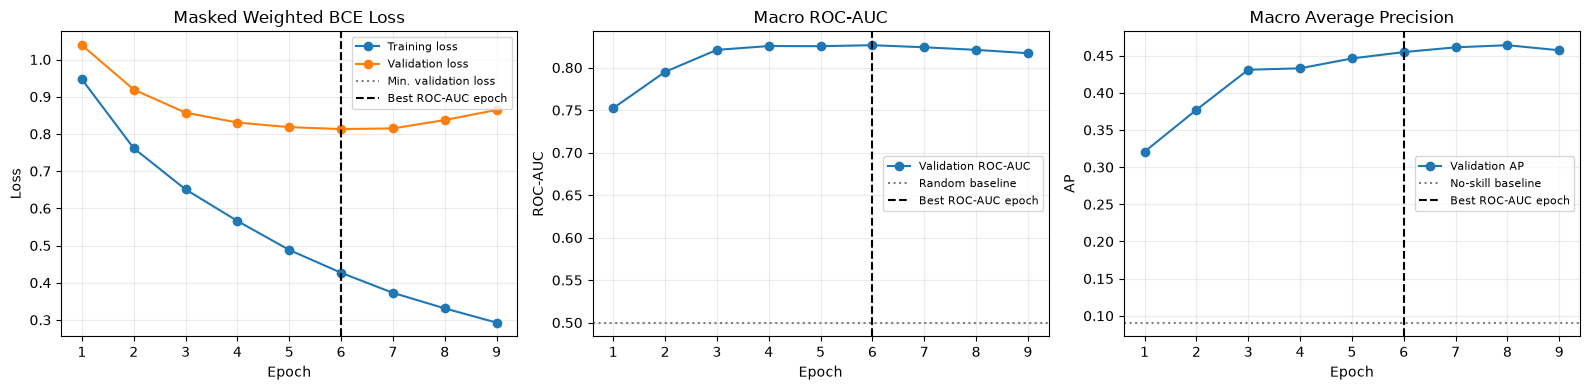

Best ROC-AUC epoch: 6
Minimum validation loss epoch: 6


In [37]:
# Plot learning curves for the smoke test

import matplotlib.pyplot as plt

best_epoch_smoke = best_info_smoke["best_epoch"]

min_loss_epoch_smoke = int(
    history_smoke.loc[
        history_smoke["val_loss"].idxmin(),
        "epoch",
    ]
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4),
)

# Loss curves
axes[0].plot(
    history_smoke["epoch"],
    history_smoke["train_loss"],
    marker="o",
    label="Training loss",
)

axes[0].plot(
    history_smoke["epoch"],
    history_smoke["val_loss"],
    marker="o",
    label="Validation loss",
)

axes[0].axvline(
    min_loss_epoch_smoke,
    color="gray",
    linestyle=":",
    label="Min. validation loss",
)

axes[0].set_title("Masked Weighted BCE Loss")
axes[0].set_ylabel("Loss")

# ROC-AUC curve
axes[1].plot(
    history_smoke["epoch"],
    history_smoke["val_mean_roc_auc"],
    marker="o",
    label="Validation ROC-AUC",
)

axes[1].axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Random baseline",
)

axes[1].set_title("Macro ROC-AUC")
axes[1].set_ylabel("ROC-AUC")

# AP curve
axes[2].plot(
    history_smoke["epoch"],
    history_smoke["val_mean_ap"],
    marker="o",
    label="Validation AP",
)

macro_ap_baseline_smoke = (
    per_task_smoke["positive_ratio"].mean()
)

axes[2].axhline(
    macro_ap_baseline_smoke,
    color="gray",
    linestyle=":",
    label="No-skill baseline",
)

axes[2].set_title("Macro Average Precision")
axes[2].set_ylabel("AP")

# Shared formatting
for ax in axes:
    ax.axvline(
        best_epoch_smoke,
        color="black",
        linestyle="--",
        label="Best ROC-AUC epoch",
    )

    ax.set_xlabel("Epoch")
    ax.set_xticks(history_smoke["epoch"])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Best ROC-AUC epoch:", best_epoch_smoke)
print("Minimum validation loss epoch:", min_loss_epoch_smoke)

# [11] Multi-task CV Experiment Runner

In [38]:
from tox21_dl.experiments import run_multitask_cv

In [39]:
# Run the five-fold CV smoke test

cv_config_check = smoke_config.copy()
cv_config_check["verbose"] = False

cv_result_check = run_multitask_cv(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    fold_df=fold_df,
    config=cv_config_check,
    verbose=True,
)

print("\nCV summary:")
display(
    pd.DataFrame(
        [cv_result_check["summary"]]
    ).round(4)
)

print("\nFold-level results:")
display(
    cv_result_check["fold_df"].round(4)
)

print("\nEndpoint-level CV results:")
display(
    cv_result_check["per_task_cv_df"].round(4)
)

Fold 1/5 (fold_id=0)
  Best epoch=6 | ROC-AUC=0.8264 | AP=0.4548
Fold 2/5 (fold_id=1)
  Best epoch=6 | ROC-AUC=0.7827 | AP=0.3411
Fold 3/5 (fold_id=2)
  Best epoch=3 | ROC-AUC=0.8205 | AP=0.4613
Fold 4/5 (fold_id=3)
  Best epoch=8 | ROC-AUC=0.7373 | AP=0.2569
Fold 5/5 (fold_id=4)
  Best epoch=5 | ROC-AUC=0.7613 | AP=0.3299

CV summary:


,n_folds,n_tasks,cv_macro_roc_auc,cv_macro_ap,fold_macro_roc_auc_std,fold_macro_ap_std,cv_macro_ap_baseline,best_epoch_median,elapsed_seconds
0,5,12,0.7856,0.3688,0.0381,0.0877,0.0734,6.0,26.3487



Fold-level results:


,fold_id,n_train,n_val,best_epoch,best_score,best_val_roc_auc,best_val_ap,best_val_loss,best_n_valid_tasks,selection_metric,seed,epochs_run,stopped_early,elapsed_seconds
0,0,5423,1010,6,0.8264,0.8264,0.4548,0.8130,12,roc_auc,42,9,True,4.3357
1,1,4559,1874,6,0.7827,0.7827,0.3411,0.5177,12,roc_auc,42,9,True,4.1120
2,2,5423,1010,3,0.8205,0.8205,0.4613,0.8478,12,roc_auc,42,6,True,4.3751
3,3,4904,1529,8,0.7373,0.7373,0.2569,0.7234,12,roc_auc,42,10,False,7.3784
4,4,5423,1010,5,0.7613,0.7613,0.3299,0.8959,12,roc_auc,42,8,True,6.1475



Endpoint-level CV results:


,task,n_valid_folds,roc_auc_mean,roc_auc_std,ap_mean,ap_std,positive_ratio_mean
0,SR-HSE,5,0.7107,0.0610,0.1850,0.0590,0.0492
1,NR-AR,5,0.8056,0.0771,0.5684,0.1769,0.0407
2,SR-ARE,5,0.7356,0.0387,0.3578,0.0786,0.1613
3,NR-Aromatase,5,0.7776,0.0408,0.1933,0.0395,0.0488
4,NR-ER-LBD,5,0.8051,0.0649,0.4282,0.2033,0.0457
5,NR-AhR,5,0.8538,0.0271,0.5347,0.0703,0.1190
6,SR-MMP,5,0.8533,0.0154,0.5526,0.0951,0.1574
7,NR-ER,5,0.7059,0.0821,0.3862,0.1482,0.1118
8,NR-PPAR-gamma,5,0.7959,0.0617,0.2264,0.0683,0.0245
9,SR-p53,5,0.7658,0.0241,0.2194,0.0576,0.0557


In [40]:
# Verify five-fold CV results

cv_summary_check = cv_result_check["summary"]
cv_folds_check = cv_result_check["fold_df"]
cv_tasks_check = cv_result_check["per_task_cv_df"]
cv_task_folds_check = cv_result_check["per_task_fold_df"]
cv_history_check = cv_result_check["history_df"]

# Check the number of folds and endpoints
assert len(cv_folds_check) == 5
assert len(cv_tasks_check) == 12
assert len(cv_task_folds_check) == 60

# Check validation sample coverage
assert cv_folds_check["n_val"].sum() == len(train_df)

# Check all endpoint/fold combinations
assert cv_tasks_check["n_valid_folds"].eq(5).all()

assert cv_task_folds_check["status"].eq("ok").all()

assert not cv_task_folds_check.duplicated(
    subset=["fold_id", "task"]
).any()

# Check metric validity
assert np.isfinite(
    cv_task_folds_check[["roc_auc", "ap"]].to_numpy()
).all()

# Verify macro ROC-AUC aggregation
assert np.isclose(
    cv_summary_check["cv_macro_roc_auc"],
    cv_tasks_check["roc_auc_mean"].mean(),
)

assert np.isclose(
    cv_summary_check["cv_macro_roc_auc"],
    cv_folds_check["best_val_roc_auc"].mean(),
)

# Verify macro AP aggregation
assert np.isclose(
    cv_summary_check["cv_macro_ap"],
    cv_tasks_check["ap_mean"].mean(),
)

assert np.isclose(
    cv_summary_check["cv_macro_ap"],
    cv_folds_check["best_val_ap"].mean(),
)

# Verify history coverage
assert len(cv_history_check) == (
    cv_folds_check["epochs_run"].sum()
)

# Compare Fold 0 with the previous smoke test
fold0_check = cv_folds_check.loc[
    cv_folds_check["fold_id"] == 0
].iloc[0]

assert fold0_check["best_epoch"] == (
    best_info_smoke["best_epoch"]
)

assert np.isclose(
    fold0_check["best_val_roc_auc"],
    best_info_smoke["best_val_roc_auc"],
)

assert np.isclose(
    fold0_check["best_val_ap"],
    best_info_smoke["best_val_ap"],
)

print("Number of folds:", len(cv_folds_check))
print("Number of endpoints:", len(cv_tasks_check))
print("Valid fold/endpoint pairs:", len(cv_task_folds_check))

print(
    "Total validation molecules:",
    cv_folds_check["n_val"].sum(),
)

print("Fold 0 reproducibility: True")
print("Macro metric aggregation: True")

print("\nAll multi-task CV checks passed.")

Number of folds: 5
Number of endpoints: 12
Valid fold/endpoint pairs: 60
Total validation molecules: 6433
Fold 0 reproducibility: True
Macro metric aggregation: True

All multi-task CV checks passed.


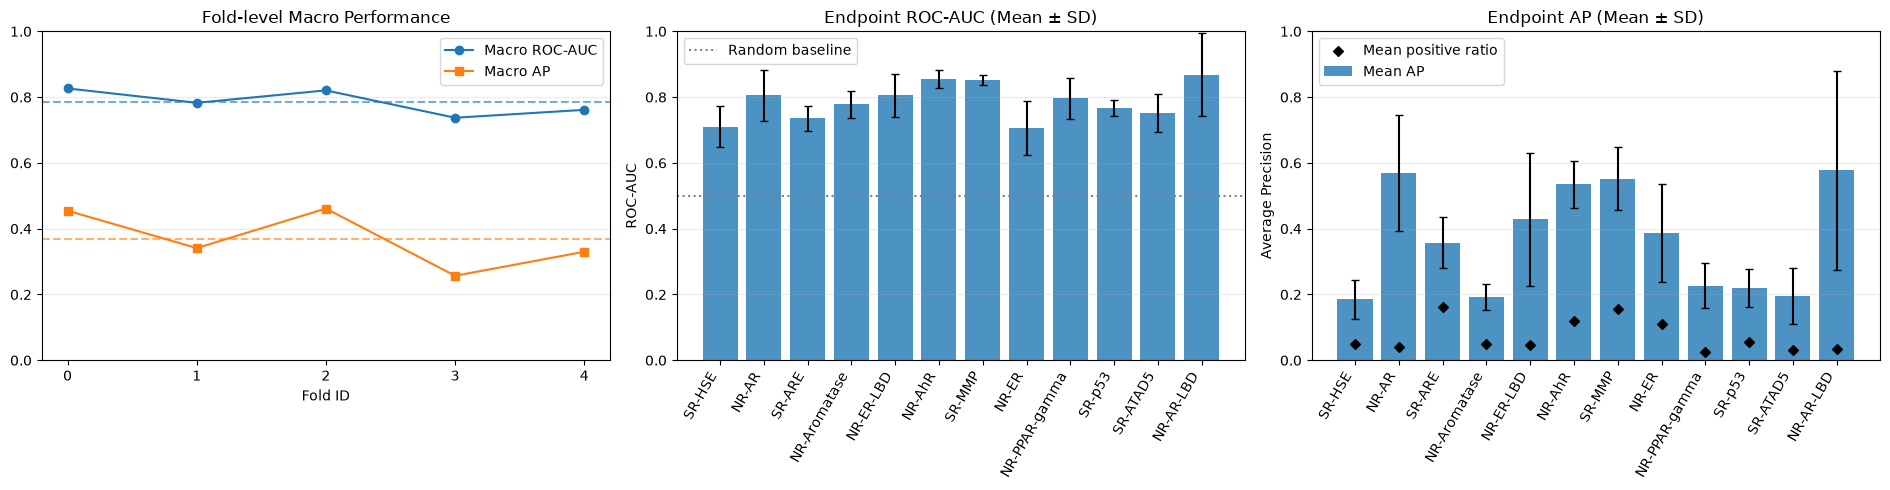

In [41]:
# Visualize five-fold CV performance

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5),
)

# Fold-level macro metrics
fold_x = cv_folds_check["fold_id"]

axes[0].plot(
    fold_x,
    cv_folds_check["best_val_roc_auc"],
    marker="o",
    label="Macro ROC-AUC",
)

axes[0].plot(
    fold_x,
    cv_folds_check["best_val_ap"],
    marker="s",
    label="Macro AP",
)

axes[0].axhline(
    cv_summary_check["cv_macro_roc_auc"],
    color="tab:blue",
    linestyle="--",
    alpha=0.6,
)

axes[0].axhline(
    cv_summary_check["cv_macro_ap"],
    color="tab:orange",
    linestyle="--",
    alpha=0.6,
)

axes[0].set_title("Fold-level Macro Performance")
axes[0].set_xlabel("Fold ID")
axes[0].set_xticks(fold_x)
axes[0].set_ylim(0, 1)
axes[0].legend()

# Endpoint-level ROC-AUC
task_x = np.arange(len(cv_tasks_check))

axes[1].bar(
    task_x,
    cv_tasks_check["roc_auc_mean"],
    yerr=cv_tasks_check["roc_auc_std"],
    capsize=3,
    alpha=0.8,
)

axes[1].axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Random baseline",
)

axes[1].set_title("Endpoint ROC-AUC (Mean ± SD)")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()

# Endpoint-level AP
axes[2].bar(
    task_x,
    cv_tasks_check["ap_mean"],
    yerr=cv_tasks_check["ap_std"],
    capsize=3,
    alpha=0.8,
    label="Mean AP",
)

axes[2].scatter(
    task_x,
    cv_tasks_check["positive_ratio_mean"],
    color="black",
    marker="D",
    s=25,
    label="Mean positive ratio",
    zorder=3,
)

axes[2].set_title("Endpoint AP (Mean ± SD)")
axes[2].set_ylabel("Average Precision")
axes[2].legend()

# Shared formatting
for ax in axes[1:]:
    ax.set_xticks(task_x)
    ax.set_xticklabels(
        cv_tasks_check["task"],
        rotation=60,
        ha="right",
    )
    ax.set_ylim(0, 1)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# [12] Initial Hyperparameter Exploration

## Architecture Comparison

In [42]:
# Define initial architecture configurations

base_config = {
    "dropout": 0.3,
    "batch_size": 128,
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "pos_weight_cap": 10.0,
    "max_epochs": 100,
    "patience": 10,
    "selection_metric": "roc_auc",
    "seed": SEED,
    "device": "cpu",
    "verbose": False,
}

architecture_candidates = {
    "Small": (128,),
    "Medium": (256, 128),
    "Large": (1024, 512),
    "Deep": (512, 256, 128),
}

architecture_configs = {
    name: {
        **base_config,
        "hidden_dims": hidden_dims,
    }
    for name, hidden_dims in architecture_candidates.items()
}

display(
    pd.DataFrame.from_dict(
        architecture_configs,
        orient="index",
    )
)

,dropout,batch_size,lr,weight_decay,pos_weight_cap,max_epochs,patience,selection_metric,seed,device,verbose,hidden_dims
Small,0.3,128,0.0003,0.0001,10.0,100,10,roc_auc,42,cpu,False,"(128,)"
Medium,0.3,128,0.0003,0.0001,10.0,100,10,roc_auc,42,cpu,False,"(256, 128)"
Large,0.3,128,0.0003,0.0001,10.0,100,10,roc_auc,42,cpu,False,"(1024, 512)"
Deep,0.3,128,0.0003,0.0001,10.0,100,10,roc_auc,42,cpu,False,"(512, 256, 128)"


In [43]:
# Run initial architecture experiments

import json
from time import perf_counter

exploration_dir = (
    dl_results_dir / "initial_exploration_v1"
)

exploration_dir.mkdir(
    parents=True,
    exist_ok=True,
)

architecture_results = {}
architecture_summary_rows = []

start_exploration = perf_counter()

for name, config in architecture_configs.items():

    print(f"\n{'=' * 60}")
    print(f"Architecture: {name}")
    print(f"Hidden dimensions: {config['hidden_dims']}")
    print(f"{'=' * 60}")

    result = run_multitask_cv(
        train_df=train_df,
        X_train_all=X_train_all,
        target_cols=target_cols,
        fold_df=fold_df,
        config=config,
        verbose=True,
    )

    architecture_results[name] = result

    # Count trainable parameters
    model_count = Tox21MLP(
        input_dim=X_train_all.shape[1],
        n_tasks=len(target_cols),
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
    )

    n_parameters = sum(
        p.numel()
        for p in model_count.parameters()
        if p.requires_grad
    )

    del model_count

    # Collect architecture-level summary
    architecture_summary_rows.append({
        "architecture": name,
        "hidden_dims": config["hidden_dims"],
        "n_parameters": n_parameters,
        **result["summary"],
    })

    # Save configuration and detailed CV results
    result_dir = exploration_dir / name.lower()

    result_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    with open(
        result_dir / "config.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            result["config"],
            f,
            indent=4,
        )

    for key in [
        "fold_df",
        "per_task_fold_df",
        "per_task_cv_df",
        "history_df",
        "per_task_history_df",
    ]:
        result[key].to_csv(
            result_dir / f"{key}.csv",
            index=False,
        )

    # Update summary after each architecture
    architecture_summary_df = pd.DataFrame(
        architecture_summary_rows
    ).sort_values(
        "cv_macro_roc_auc",
        ascending=False,
    ).reset_index(drop=True)

    architecture_summary_df.to_csv(
        exploration_dir / "architecture_summary.csv",
        index=False,
    )

elapsed_exploration = (
    perf_counter() - start_exploration
)

print(
    f"\nTotal exploration time: "
    f"{elapsed_exploration:.2f} seconds"
)

display(
    architecture_summary_df.round(4)
)


Architecture: Small
Hidden dimensions: (128,)
Fold 1/5 (fold_id=0)
  Best epoch=5 | ROC-AUC=0.8187 | AP=0.4512
Fold 2/5 (fold_id=1)
  Best epoch=6 | ROC-AUC=0.7524 | AP=0.2836
Fold 3/5 (fold_id=2)
  Best epoch=4 | ROC-AUC=0.8070 | AP=0.4629
Fold 4/5 (fold_id=3)
  Best epoch=7 | ROC-AUC=0.7218 | AP=0.2610
Fold 5/5 (fold_id=4)
  Best epoch=4 | ROC-AUC=0.7648 | AP=0.3338

Architecture: Medium
Hidden dimensions: (256, 128)
Fold 1/5 (fold_id=0)
  Best epoch=6 | ROC-AUC=0.8264 | AP=0.4548
Fold 2/5 (fold_id=1)
  Best epoch=6 | ROC-AUC=0.7827 | AP=0.3411
Fold 3/5 (fold_id=2)
  Best epoch=3 | ROC-AUC=0.8205 | AP=0.4613
Fold 4/5 (fold_id=3)
  Best epoch=21 | ROC-AUC=0.7424 | AP=0.2505
Fold 5/5 (fold_id=4)
  Best epoch=5 | ROC-AUC=0.7613 | AP=0.3299

Architecture: Large
Hidden dimensions: (1024, 512)
Fold 1/5 (fold_id=0)
  Best epoch=3 | ROC-AUC=0.8320 | AP=0.4543
Fold 2/5 (fold_id=1)
  Best epoch=3 | ROC-AUC=0.8018 | AP=0.3283
Fold 3/5 (fold_id=2)
  Best epoch=2 | ROC-AUC=0.8386 | AP=0.4927
Fol

,architecture,hidden_dims,n_parameters,n_folds,n_tasks,cv_macro_roc_auc,cv_macro_ap,fold_macro_roc_auc_std,fold_macro_ap_std,cv_macro_ap_baseline,best_epoch_median,elapsed_seconds
0,Large,"(1024, 512)",2643468,5,12,0.8008,0.3781,0.0359,0.0928,0.0734,2.0,88.1020
1,Deep,"(512, 256, 128)",1222284,5,12,0.7993,0.3765,0.0365,0.0893,0.0734,6.0,89.7875
2,Medium,"(256, 128)",562572,5,12,0.7867,0.3675,0.0366,0.0897,0.0734,6.0,64.9753
3,Small,"(128,)",265484,5,12,0.7730,0.3585,0.0399,0.0938,0.0734,5.0,39.3246


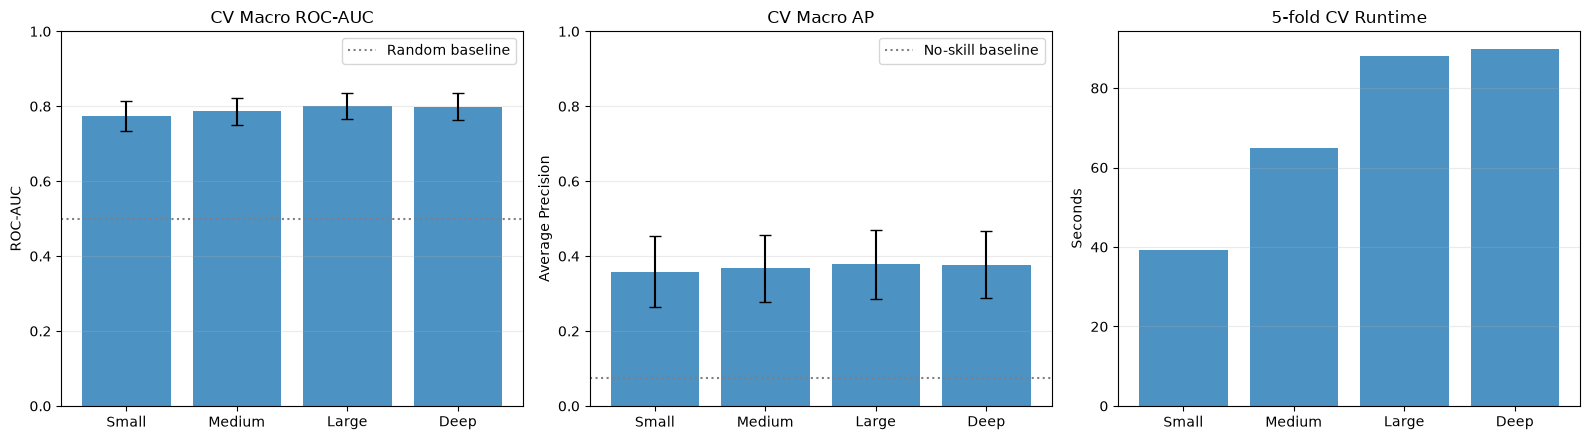

,architecture,hidden_dims,n_parameters,cv_macro_roc_auc,fold_macro_roc_auc_std,cv_macro_ap,fold_macro_ap_std,best_epoch_median,elapsed_seconds
0,Large,"(1024, 512)",2643468,0.8008,0.0359,0.3781,0.0928,2.0,88.1020
1,Deep,"(512, 256, 128)",1222284,0.7993,0.0365,0.3765,0.0893,6.0,89.7875
2,Medium,"(256, 128)",562572,0.7867,0.0366,0.3675,0.0897,6.0,64.9753
3,Small,"(128,)",265484,0.7730,0.0399,0.3585,0.0938,5.0,39.3246


In [44]:
# Compare initial architecture performance

comparison_df = (
    architecture_summary_df
    .set_index("architecture")
    .loc[list(architecture_candidates)]
    .reset_index()
)

x = np.arange(len(comparison_df))

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
)

# Macro ROC-AUC
axes[0].bar(
    x,
    comparison_df["cv_macro_roc_auc"],
    yerr=comparison_df["fold_macro_roc_auc_std"],
    capsize=4,
    alpha=0.8,
)

axes[0].axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Random baseline",
)

axes[0].set_title("CV Macro ROC-AUC")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0, 1)
axes[0].legend()

# Macro AP
axes[1].bar(
    x,
    comparison_df["cv_macro_ap"],
    yerr=comparison_df["fold_macro_ap_std"],
    capsize=4,
    alpha=0.8,
)

axes[1].axhline(
    comparison_df["cv_macro_ap_baseline"].iloc[0],
    color="gray",
    linestyle=":",
    label="No-skill baseline",
)

axes[1].set_title("CV Macro AP")
axes[1].set_ylabel("Average Precision")
axes[1].set_ylim(0, 1)
axes[1].legend()

# Computational cost
axes[2].bar(
    x,
    comparison_df["elapsed_seconds"],
    alpha=0.8,
)

axes[2].set_title("5-fold CV Runtime")
axes[2].set_ylabel("Seconds")

# Shared formatting
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(
        comparison_df["architecture"]
    )
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

display(
    architecture_summary_df[
        [
            "architecture",
            "hidden_dims",
            "n_parameters",
            "cv_macro_roc_auc",
            "fold_macro_roc_auc_std",
            "cv_macro_ap",
            "fold_macro_ap_std",
            "best_epoch_median",
            "elapsed_seconds",
        ]
    ].round(4)
)

## Learning Curve Analysis

In [45]:
# Analyze convergence and early stopping behavior

convergence_rows = []

for name, result in architecture_results.items():

    history = result["history_df"]
    fold_results = result["fold_df"]

    for _, fold_row in fold_results.iterrows():

        fold_id = int(fold_row["fold_id"])

        h = history.loc[
            history["fold_id"] == fold_id
        ].sort_values("epoch")

        best_epoch = int(fold_row["best_epoch"])

        best_row = h.loc[
            h["epoch"] == best_epoch
        ].iloc[0]

        last_row = h.iloc[-1]

        min_loss_epoch = int(
            h.loc[h["val_loss"].idxmin(), "epoch"]
        )

        max_ap_epoch = int(
            h.loc[h["val_mean_ap"].idxmax(), "epoch"]
        )

        convergence_rows.append({
            "architecture": name,
            "fold_id": fold_id,
            "best_epoch": best_epoch,
            "epochs_run": int(fold_row["epochs_run"]),
            "min_loss_epoch": min_loss_epoch,
            "max_ap_epoch": max_ap_epoch,
            "best_roc_auc": best_row["val_mean_roc_auc"],
            "last_roc_auc": last_row["val_mean_roc_auc"],
            "roc_auc_drop": (
                best_row["val_mean_roc_auc"]
                - last_row["val_mean_roc_auc"]
            ),
            "best_train_loss": best_row["train_loss"],
            "best_val_loss": best_row["val_loss"],
            "last_train_loss": last_row["train_loss"],
            "last_val_loss": last_row["val_loss"],
            "stopped_early": fold_row["stopped_early"],
        })

convergence_df = pd.DataFrame(convergence_rows)

display(convergence_df.round(4))

# Summarize convergence by architecture
convergence_summary_df = (
    convergence_df
    .groupby("architecture", sort=False)
    .agg(
        best_epoch_min=("best_epoch", "min"),
        best_epoch_median=("best_epoch", "median"),
        best_epoch_max=("best_epoch", "max"),
        epochs_run_mean=("epochs_run", "mean"),
        roc_auc_drop_mean=("roc_auc_drop", "mean"), # Best epoch 대비 학습 종료 시점의 ROC-AUC 감소량
        n_early_stopped=("stopped_early", "sum"),
    )
    .reset_index()
)

display(convergence_summary_df.round(4))

,architecture,fold_id,best_epoch,epochs_run,min_loss_epoch,max_ap_epoch,best_roc_auc,last_roc_auc,roc_auc_drop,best_train_loss,best_val_loss,last_train_loss,last_val_loss,stopped_early
0,Small,0,5,15,5,7,0.8187,0.7934,0.0253,0.4650,0.8344,0.1651,1.1946,True
1,Small,1,6,16,6,8,0.7524,0.7282,0.0242,0.4549,0.5399,0.1723,0.6694,True
2,Small,2,4,14,5,6,0.8070,0.7719,0.0351,0.5406,0.8217,0.1784,1.1334,True
3,Small,3,7,17,7,7,0.7218,0.7120,0.0098,0.3796,0.7210,0.1475,0.8598,True
4,Small,4,4,14,4,7,0.7648,0.7335,0.0313,0.5368,0.9060,0.1753,1.2696,True
5,Medium,0,6,16,6,8,0.8264,0.8040,0.0224,0.4268,0.8130,0.1606,1.0432,True
6,Medium,1,6,16,6,6,0.7827,0.7579,0.0248,0.4722,0.5177,0.1719,0.6005,True
7,Medium,2,3,13,6,7,0.8205,0.7853,0.0352,0.6525,0.8478,0.1979,0.9469,True
8,Medium,3,21,31,8,16,0.7424,0.7375,0.0048,0.1207,0.8601,0.0782,0.9708,True
9,Medium,4,5,15,5,7,0.7613,0.7373,0.0240,0.4850,0.8959,0.1691,1.1014,True


,architecture,best_epoch_min,best_epoch_median,best_epoch_max,epochs_run_mean,roc_auc_drop_mean,n_early_stopped
0,Small,4,5.0,7,15.2,0.0252,5
1,Medium,3,6.0,21,18.2,0.0223,5
2,Large,2,2.0,3,12.4,0.0285,5
3,Deep,4,6.0,17,17.8,0.0243,5


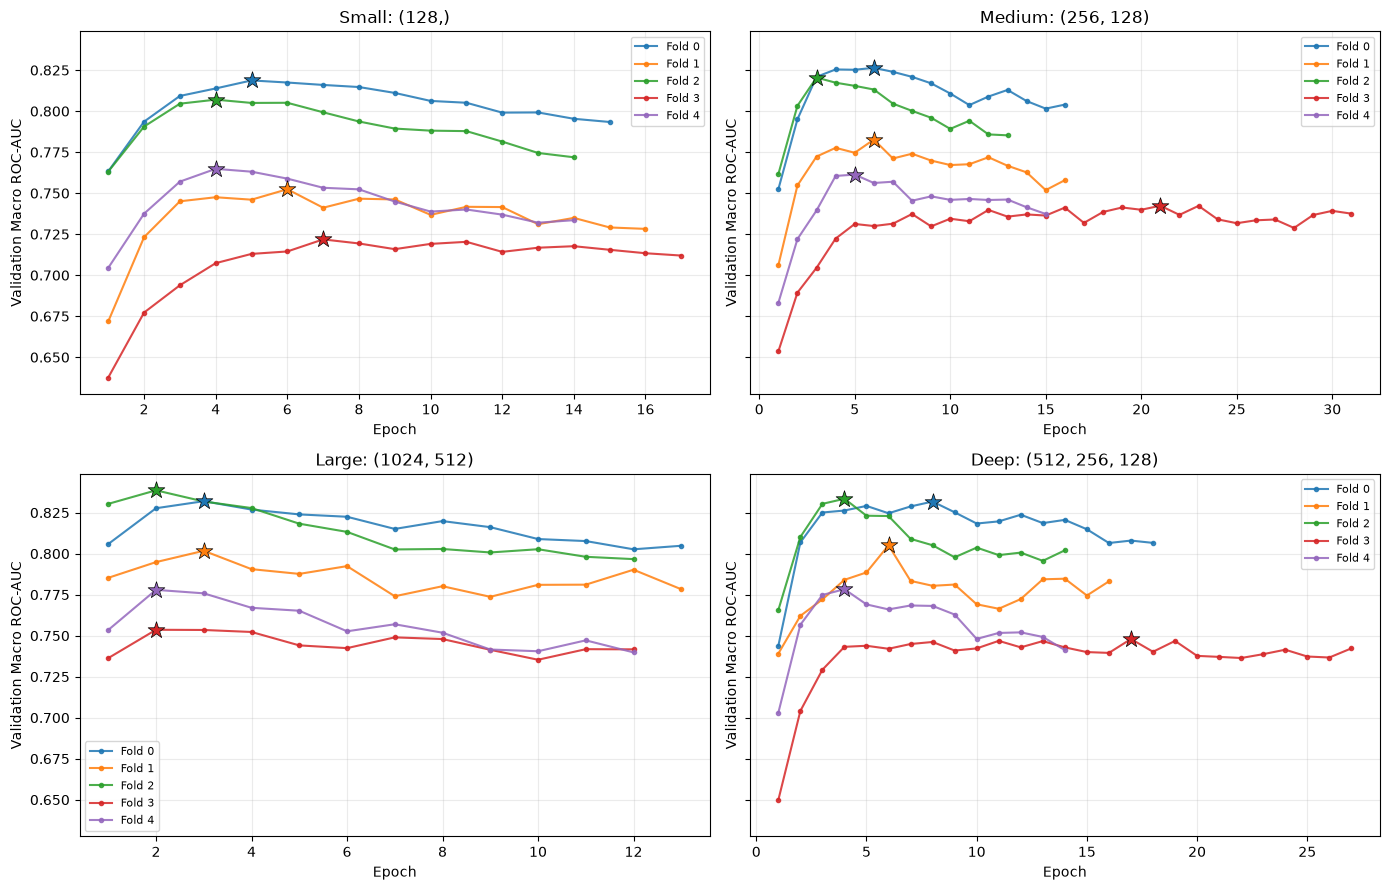

In [46]:
# Compare validation ROC-AUC learning curves

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharey=True,
)

for ax, name in zip(
    axes.flatten(),
    architecture_candidates,
):
    result = architecture_results[name]

    history = result["history_df"]
    fold_results = result["fold_df"]

    for fold_id, h in history.groupby("fold_id"):

        h = h.sort_values("epoch")

        line, = ax.plot(
            h["epoch"],
            h["val_mean_roc_auc"],
            marker="o",
            markersize=3,
            label=f"Fold {fold_id}",
            alpha=0.85,
        )

        best_epoch = int(
            fold_results.loc[
                fold_results["fold_id"] == fold_id,
                "best_epoch",
            ].iloc[0]
        )

        best_auc = h.loc[
            h["epoch"] == best_epoch,
            "val_mean_roc_auc",
        ].iloc[0]

        ax.scatter(
            best_epoch,
            best_auc,
            color=line.get_color(),
            marker="*",
            s=160,
            edgecolor="black",
            linewidth=0.5,
            zorder=5,
        )

    ax.set_title(
        f"{name}: {architecture_candidates[name]}"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation Macro ROC-AUC")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

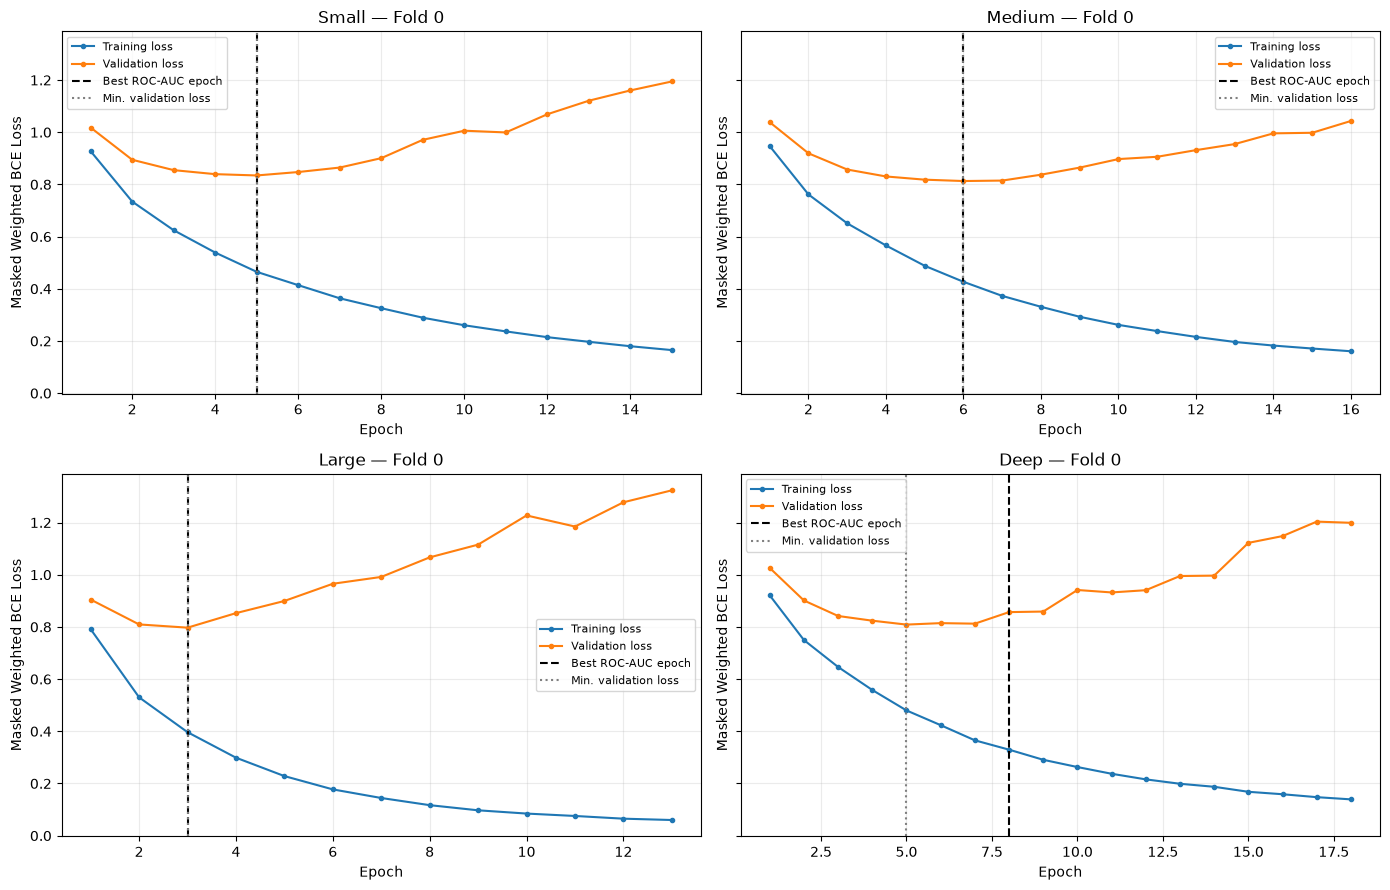

In [47]:
# Compare loss curves using the same validation fold

ANALYSIS_FOLD_ID = 0    # fOLD  0 기준  

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharey=True,
)

for ax, name in zip(
    axes.flatten(),
    architecture_candidates,
):
    result = architecture_results[name]

    h = result["history_df"].loc[
        result["history_df"]["fold_id"]
        == ANALYSIS_FOLD_ID
    ].sort_values("epoch")

    best_epoch = int(
        result["fold_df"].loc[
            result["fold_df"]["fold_id"]
            == ANALYSIS_FOLD_ID,
            "best_epoch",
        ].iloc[0]
    )

    min_loss_epoch = int(
        h.loc[h["val_loss"].idxmin(), "epoch"]
    )

    ax.plot(
        h["epoch"],
        h["train_loss"],
        marker="o",
        markersize=3,
        label="Training loss",
    )

    ax.plot(
        h["epoch"],
        h["val_loss"],
        marker="o",
        markersize=3,
        label="Validation loss",
    )

    ax.axvline(
        best_epoch,
        color="black",
        linestyle="--",
        label="Best ROC-AUC epoch",
    )

    ax.axvline(
        min_loss_epoch,
        color="gray",
        linestyle=":",
        label="Min. validation loss",
    )

    ax.set_title(f"{name} — Fold {ANALYSIS_FOLD_ID}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked Weighted BCE Loss")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [48]:
# 모델 크기가 클수록 무조건 더 오래 학습해야 하는 것이 아니라, 오히려 더 빠르게 학습하고 더 빠르게 overfitting이 발생할 수 있다
# Large 모델은 다른 모델보다 training loss가 훨씬 빠르게 감소하지만, validation loss는 epoch 3 이후 크게 증가
# 다만 Large 모델이 현재 가장 높은 CV 성능을 기록 -> 따라서 모델을 단순히 작게 만드는 것보다는 큰 모델의 학습 능력을 유지하면서 일반화 성능을 개선하는 방향을 탐색



In [49]:
# Save learning curve analysis results

convergence_df.to_csv(
    exploration_dir / "convergence_details.csv",
    index=False,
)

convergence_summary_df.to_csv(
    exploration_dir / "convergence_summary.csv",
    index=False,
)

## Targeted Hyperparameter Exploration

In [50]:
# Define targeted hyperparameter configurations - for Large architecture (learning rate, dropout, weight decay)

large_base_config = architecture_configs["Large"].copy()

targeted_configs = {
    "Lower_LR": {
        **large_base_config,
        "lr": 1e-4,
    },
    "Higher_Dropout": {
        **large_base_config,
        "dropout": 0.5,
    },
    "Higher_WD": {
        **large_base_config,
        "weight_decay": 1e-3,
    },
}

targeted_config_df = pd.DataFrame.from_dict(
    {
        "Large_Baseline": large_base_config,
        **targeted_configs,
    },
    orient="index",
)

display(
    targeted_config_df[
        [
            "hidden_dims",
            "lr",
            "dropout",
            "weight_decay",
            "batch_size",
            "pos_weight_cap",
            "max_epochs",
            "patience",
        ]
    ]
)

,hidden_dims,lr,dropout,weight_decay,batch_size,pos_weight_cap,max_epochs,patience
Large_Baseline,"(1024, 512)",0.0003,0.3,0.0001,128,10.0,100,10
Lower_LR,"(1024, 512)",0.0001,0.3,0.0001,128,10.0,100,10
Higher_Dropout,"(1024, 512)",0.0003,0.5,0.0001,128,10.0,100,10
Higher_WD,"(1024, 512)",0.0003,0.3,0.0010,128,10.0,100,10


In [51]:
# Run targeted hyperparameter experiments

import json
from time import perf_counter

targeted_dir = (
    exploration_dir / "targeted_exploration"
)

targeted_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Reuse the existing Large baseline
targeted_results = {
    "Large_Baseline": architecture_results["Large"]
}

targeted_summary_rows = [{
    "configuration": "Large_Baseline",
    "lr": large_base_config["lr"],
    "dropout": large_base_config["dropout"],
    "weight_decay": large_base_config["weight_decay"],
    **architecture_results["Large"]["summary"],
}]

start_targeted = perf_counter()

for name, config in targeted_configs.items():

    print(f"\n{'=' * 60}")
    print(f"Configuration: {name}")
    print(f"{'=' * 60}")

    result = run_multitask_cv(
        train_df=train_df,
        X_train_all=X_train_all,
        target_cols=target_cols,
        fold_df=fold_df,
        config=config,
        verbose=True,
    )

    targeted_results[name] = result

    targeted_summary_rows.append({
        "configuration": name,
        "lr": config["lr"],
        "dropout": config["dropout"],
        "weight_decay": config["weight_decay"],
        **result["summary"],
    })

    # Save detailed results
    result_dir = targeted_dir / name.lower()

    result_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    with open(
        result_dir / "config.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            result["config"],
            f,
            indent=4,
        )

    for key in [
        "fold_df",
        "per_task_fold_df",
        "per_task_cv_df",
        "history_df",
        "per_task_history_df",
    ]:
        result[key].to_csv(
            result_dir / f"{key}.csv",
            index=False,
        )

    # Update the summary after each configuration
    targeted_summary_df = (
        pd.DataFrame(targeted_summary_rows)
        .sort_values(
            "cv_macro_roc_auc",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    targeted_summary_df.to_csv(
        targeted_dir / "targeted_summary.csv",
        index=False,
    )

elapsed_targeted = perf_counter() - start_targeted

print(
    f"\nTotal targeted exploration time: "
    f"{elapsed_targeted:.2f} seconds"
)

display(targeted_summary_df.round(4))


Configuration: Lower_LR
Fold 1/5 (fold_id=0)
  Best epoch=8 | ROC-AUC=0.8315 | AP=0.4576
Fold 2/5 (fold_id=1)
  Best epoch=6 | ROC-AUC=0.7927 | AP=0.3098
Fold 3/5 (fold_id=2)
  Best epoch=6 | ROC-AUC=0.8401 | AP=0.4983
Fold 4/5 (fold_id=3)
  Best epoch=7 | ROC-AUC=0.7564 | AP=0.2814
Fold 5/5 (fold_id=4)
  Best epoch=6 | ROC-AUC=0.7735 | AP=0.3496

Configuration: Higher_Dropout
Fold 1/5 (fold_id=0)
  Best epoch=6 | ROC-AUC=0.8322 | AP=0.4448
Fold 2/5 (fold_id=1)
  Best epoch=3 | ROC-AUC=0.7995 | AP=0.3128
Fold 3/5 (fold_id=2)
  Best epoch=3 | ROC-AUC=0.8409 | AP=0.4972
Fold 4/5 (fold_id=3)
  Best epoch=4 | ROC-AUC=0.7556 | AP=0.2757
Fold 5/5 (fold_id=4)
  Best epoch=4 | ROC-AUC=0.7772 | AP=0.3516

Configuration: Higher_WD
Fold 1/5 (fold_id=0)
  Best epoch=3 | ROC-AUC=0.8328 | AP=0.4577
Fold 2/5 (fold_id=1)
  Best epoch=3 | ROC-AUC=0.8033 | AP=0.3304
Fold 3/5 (fold_id=2)
  Best epoch=2 | ROC-AUC=0.8410 | AP=0.4950
Fold 4/5 (fold_id=3)
  Best epoch=19 | ROC-AUC=0.7589 | AP=0.2687
Fold 5/

,configuration,lr,dropout,weight_decay,n_folds,n_tasks,cv_macro_roc_auc,cv_macro_ap,fold_macro_roc_auc_std,fold_macro_ap_std,cv_macro_ap_baseline,best_epoch_median,elapsed_seconds
0,Higher_WD,0.0003,0.3,0.0010,5,12,0.8028,0.3830,0.0350,0.0927,0.0734,3.0,123.7488
1,Higher_Dropout,0.0003,0.5,0.0001,5,12,0.8011,0.3764,0.0360,0.0923,0.0734,4.0,118.2829
2,Large_Baseline,0.0003,0.3,0.0001,5,12,0.8008,0.3781,0.0359,0.0928,0.0734,2.0,88.1020
3,Lower_LR,0.0001,0.3,0.0001,5,12,0.7988,0.3793,0.0362,0.0943,0.0734,6.0,129.7519


In [52]:
# Compare each configuration against the Large baseline

baseline_folds = (
    targeted_results["Large_Baseline"]["fold_df"]
    .set_index("fold_id")
)

targeted_comparison_rows = []

for name, result in targeted_results.items():

    current_folds = (
        result["fold_df"]
        .set_index("fold_id")
        .loc[baseline_folds.index]
    )

    auc_delta = (
        current_folds["best_val_roc_auc"]
        - baseline_folds["best_val_roc_auc"]
    )

    ap_delta = (
        current_folds["best_val_ap"]
        - baseline_folds["best_val_ap"]
    )

    targeted_comparison_rows.append({
        "configuration": name,
        "roc_auc_delta": auc_delta.mean(),
        "ap_delta": ap_delta.mean(),
        "n_folds_auc_improved": int(
            (auc_delta > 0).sum()
        ),
        "n_folds_ap_improved": int(
            (ap_delta > 0).sum()
        ),
        "best_epoch_median": (
            current_folds["best_epoch"].median()
        ),
        "epochs_run_mean": (
            current_folds["epochs_run"].mean()
        ),
    })

targeted_comparison_df = pd.DataFrame(
    targeted_comparison_rows
)

display(targeted_comparison_df.round(4))

targeted_comparison_df.to_csv(
    targeted_dir / "baseline_comparison.csv",
    index=False,
)

,configuration,roc_auc_delta,ap_delta,n_folds_auc_improved,n_folds_ap_improved,best_epoch_median,epochs_run_mean
0,Large_Baseline,0.0000,0.0000,0,0,2.0,12.4
1,Lower_LR,-0.0020,0.0012,2,4,6.0,16.6
2,Higher_Dropout,0.0003,-0.0017,3,3,4.0,14.0
3,Higher_WD,0.0020,0.0049,4,5,3.0,16.0


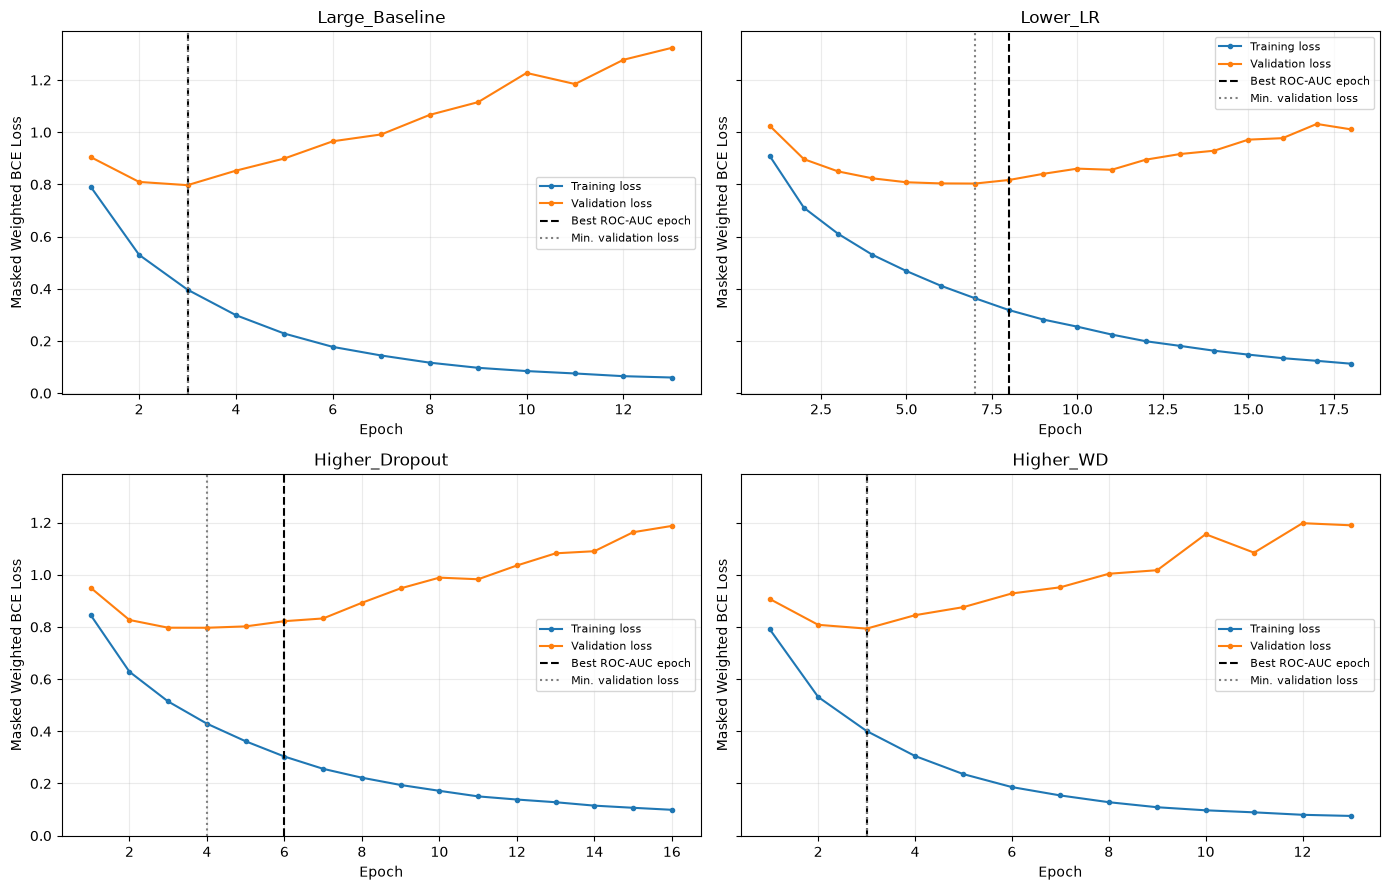

In [53]:
# Compare targeted learning curves on Fold 0

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharey=True,
)

for ax, (name, result) in zip(
    axes.flatten(),
    targeted_results.items(),
):

    history = result["history_df"]

    h = history.loc[
        history["fold_id"] == 0
    ].sort_values("epoch")

    best_epoch = int(
        result["fold_df"].loc[
            result["fold_df"]["fold_id"] == 0,
            "best_epoch",
        ].iloc[0]
    )

    min_loss_epoch = int(
        h.loc[h["val_loss"].idxmin(), "epoch"]
    )

    ax.plot(
        h["epoch"],
        h["train_loss"],
        marker="o",
        markersize=3,
        label="Training loss",
    )

    ax.plot(
        h["epoch"],
        h["val_loss"],
        marker="o",
        markersize=3,
        label="Validation loss",
    )

    ax.axvline(
        best_epoch,
        color="black",
        linestyle="--",
        label="Best ROC-AUC epoch",
    )

    ax.axvline(
        min_loss_epoch,
        color="gray",
        linestyle=":",
        label="Min. validation loss",
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked Weighted BCE Loss")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Optuna Search Space

In [54]:
# Define the Optuna hyperparameter search space

optuna_search_space = {
    "hidden_depth": [1, 2, 3],
    "first_hidden_dim": [128, 256, 512, 1024],
    "dropout": (0.0, 0.6),
    "weight_decay": (1e-7, 1e-2),
    "lr": (3e-5, 1e-3),
    "batch_size": [64, 128, 256],
    "pos_weight_cap": [1.0, 5.0, 10.0, 20.0, None],
}

optuna_fixed_config = {
    "max_epochs": 100,
    "patience": 10,
    "selection_metric": "roc_auc",
    "seed": SEED,
    "device": "cpu",
    "verbose": False,
}

display(
    pd.DataFrame([
        {
            "parameter": name,
            "search_space": str(values),
        }
        for name, values in optuna_search_space.items()
    ])
)

,parameter,search_space
0,hidden_depth,"[1, 2, 3]"
1,first_hidden_dim,"[128, 256, 512, 1024]"
2,dropout,"(0.0, 0.6)"
3,weight_decay,"(1e-07, 0.01)"
4,lr,"(3e-05, 0.001)"
5,batch_size,"[64, 128, 256]"
6,pos_weight_cap,"[1.0, 5.0, 10.0, 20.0, None]"


In [55]:
# Inspect all possible architecture candidates

optuna_architecture_rows = []

for depth in optuna_search_space["hidden_depth"]:

    for width in optuna_search_space["first_hidden_dim"]:

        hidden_dims = tuple(
            max(64, width // (2 ** i))
            for i in range(depth)
        )

        model_check = Tox21MLP(
            input_dim=X_train_all.shape[1],
            n_tasks=len(target_cols),
            hidden_dims=hidden_dims,
            dropout=0.3,
        )

        n_parameters = sum(
            p.numel()
            for p in model_check.parameters()
            if p.requires_grad
        )

        optuna_architecture_rows.append({
            "hidden_depth": depth,
            "first_hidden_dim": width,
            "hidden_dims": hidden_dims,
            "n_parameters": n_parameters,
        })

        del model_check

optuna_architecture_df = pd.DataFrame(
    optuna_architecture_rows
)

assert len(optuna_architecture_df) == 12

assert set(architecture_candidates.values()).issubset(
    set(optuna_architecture_df["hidden_dims"])
)

display(optuna_architecture_df)

print("All search space checks passed.")

,hidden_depth,first_hidden_dim,hidden_dims,n_parameters
0,1,128,"(128,)",265484
1,1,256,"(256,)",530956
2,1,512,"(512,)",1061900
3,1,1024,"(1024,)",2123788
4,2,128,"(128, 64)",273100
5,2,256,"(256, 128)",562572
6,2,512,"(512, 256)",1190668
7,2,1024,"(1024, 512)",2643468
8,3,128,"(128, 64, 64)",277388
9,3,256,"(256, 128, 64)",570188


All search space checks passed.


In [56]:
# Save the planned Optuna search space

search_space_info = {
    "search_space": optuna_search_space,
    "fixed_config": optuna_fixed_config,
    "architecture_rule": {
        "width_reduction_factor": 2,
        "minimum_hidden_dim": 64,
    },
    "sampling": {
        "weight_decay": "log",
        "lr": "log",
        "dropout": "uniform",
    },
}

with open(
    exploration_dir / "optuna_search_space.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        search_space_info,
        f,
        indent=4,
    )

print("Optuna search space saved.")

Optuna search space saved.


# [13] Optuna Hyperparameter Optimization

## Optuna Setup

In [57]:
# Verify Optuna and the training environment

import sys
import optuna
import torch

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Optuna:", optuna.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.12.16 | packaged by conda-forge | (main, Oct 26 2026, 11:29:01) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\junge\miniconda3\envs\tox21_ml\python.exe
Optuna: 5.1.0
PyTorch: 2.15.0+cpu
CUDA available: False


c:\Users\junge\miniconda3\envs\tox21_ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [58]:
# Basic Optuna smoke test

def toy_objective(trial):

    x = trial.suggest_float(
        "x",
        0.0,
        6.0,
    )

    score = 1.0 - (x - 3.0) ** 2

    return score


toy_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED,
    ),
)

toy_study.optimize(
    toy_objective,
    n_trials=20,
)

print("\nBest trial:", toy_study.best_trial.number)
print("Best parameters:", toy_study.best_params)
print("Best objective value:", toy_study.best_value)

display(
    toy_study.trials_dataframe().round(4)
)

assert len(toy_study.trials) == 20

assert all(
    t.state == optuna.trial.TrialState.COMPLETE
    for t in toy_study.trials
)

assert np.isclose(
    toy_study.best_value,
    1.0 - (toy_study.best_params["x"] - 3.0) ** 2,
)

print("All Optuna smoke test checks passed.")

[I 2026-11-27 09:54:33,906] A new study created in memory with name: no-name-4818a3fc-7fd4-4e2e-ad66-edc2f3936946
[I 2026-11-27 09:54:33,911] Trial 0 finished with value: 0.4333534559619786 and parameters: {'x': 2.247240713084175}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:54:33,912] Trial 1 finished with value: -6.313161896092585 and parameters: {'x': 5.704285838459497}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:54:33,916] Trial 2 finished with value: -0.9375628053389706 and parameters: {'x': 4.391963650868431}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:54:33,916] Trial 3 finished with value: 0.6495941258539508 and parameters: {'x': 3.5919509051822196}. Best is trial 3 with value: 0.6495941258539508.
[I 2026-11-27 09:54:33,918] Trial 4 finished with value: -3.259634326030511 and parameters: {'x': 0.9361118426546191}. Best is trial 3 with value: 0.6495941258539508.
[I 2026-11-27 09:54:33,921] Trial 5 finished with val


Best trial: 10
Best parameters: {'x': 2.8517243230709357}
Best objective value: 0.9780143236312278


C:\Users\junge\AppData\Local\Temp\ipykernel_43860\2059313389.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  toy_study.trials_dataframe().round(4)


,number,value,datetime_start,datetime_complete,duration,params_x,system_attrs_tpe:relative_params:0,state
0,0,0.4334,2026-11-27 09:54:33.909465,2026-11-27 09:54:33.911532,0 days 00:00:00.002067,2.2472,NaN,COMPLETE
1,1,-6.3132,2026-11-27 09:54:33.912803,2026-11-27 09:54:33.912803,0 days 00:00:00.000000,5.7043,NaN,COMPLETE
2,2,-0.9376,2026-11-27 09:54:33.912803,2026-11-27 09:54:33.916507,0 days 00:00:00.003704,4.3920,NaN,COMPLETE
3,3,0.6496,2026-11-27 09:54:33.916507,2026-11-27 09:54:33.916507,0 days 00:00:00.000000,3.5920,NaN,COMPLETE
4,4,-3.2596,2026-11-27 09:54:33.918907,2026-11-27 09:54:33.918907,0 days 00:00:00.000000,0.9361,NaN,COMPLETE
5,5,-3.2602,2026-11-27 09:54:33.921512,2026-11-27 09:54:33.921512,0 days 00:00:00.000000,0.9360,NaN,COMPLETE
6,6,-6.0304,2026-11-27 09:54:33.923374,2026-11-27 09:54:33.923374,0 days 00:00:00.000000,0.3485,NaN,COMPLETE
7,7,-3.8271,2026-11-27 09:54:33.925761,2026-11-27 09:54:33.925761,0 days 00:00:00.000000,5.1971,NaN,COMPLETE
8,8,0.6319,2026-11-27 09:54:33.927760,2026-11-27 09:54:33.927760,0 days 00:00:00.000000,3.6067,NaN,COMPLETE
9,9,-0.5586,2026-11-27 09:54:33.930212,2026-11-27 09:54:33.932215,0 days 00:00:00.002003,4.2484,NaN,COMPLETE


All Optuna smoke test checks passed.


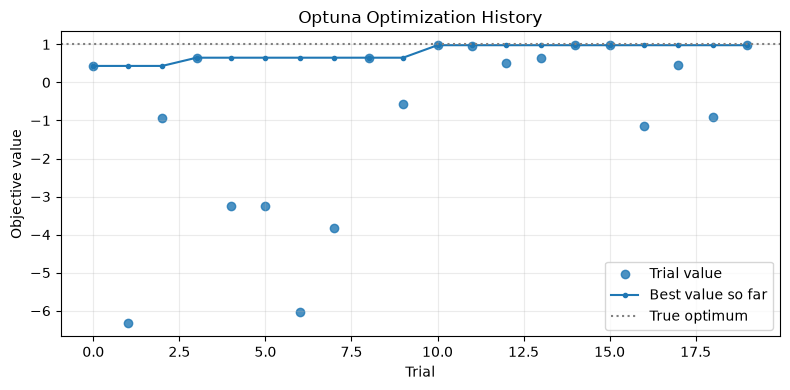

In [59]:
# Visualize the Optuna smoke test

toy_trials_df = toy_study.trials_dataframe()

toy_trials_df["best_so_far"] = (
    toy_trials_df["value"].cummax()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    toy_trials_df["number"],
    toy_trials_df["value"],
    label="Trial value",
    alpha=0.8,
)

ax.plot(
    toy_trials_df["number"],
    toy_trials_df["best_so_far"],
    label="Best value so far",
    marker="o",
    markersize=3,
)

ax.axhline(
    1.0,
    color="gray",
    linestyle=":",
    label="True optimum",
)

ax.set_xlabel("Trial")
ax.set_ylabel("Objective value")
ax.set_title("Optuna Optimization History")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## Tuning Module & Objective Function

In [60]:
from tox21_dl.tuning import (
    suggest_hyperparameters,
    make_objective,
)

In [61]:
# Verify Optuna hyperparameter mapping

manual_best_params = {
    "hidden_depth": 2,
    "first_hidden_dim": 1024,
    "dropout": 0.3,
    "weight_decay": 1e-3,
    "lr": 3e-4,
    "batch_size": 128,
    "pos_weight_cap": 10.0,
}

fixed_trial_check = optuna.trial.FixedTrial(
    manual_best_params
)

config_optuna_check = suggest_hyperparameters(
    trial=fixed_trial_check,
    search_space=optuna_search_space,
    fixed_config=optuna_fixed_config,
)

# Compare with the existing manual configuration
expected_config = targeted_configs["Higher_WD"]

assert config_optuna_check == expected_config

assert config_optuna_check["hidden_dims"] == (
    1024, 512
)

display(
    pd.DataFrame([config_optuna_check])
)

print("Manual configuration reproduced: True")
print("All hyperparameter mapping checks passed.")

,max_epochs,patience,selection_metric,seed,device,verbose,hidden_dims,dropout,weight_decay,lr,batch_size,pos_weight_cap
0,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.3,0.001,0.0003,128,10.0


Manual configuration reproduced: True
All hyperparameter mapping checks passed.


In [62]:
# Run one real objective trial for validation (higher weight decay configuration in Optuna vs. manual best configuration) 

objective_check = make_objective(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    fold_df=fold_df,
    search_space=optuna_search_space,
    fixed_config=optuna_fixed_config,
    verbose=True,
)

# Create a temporary in-memory study
study_check = optuna.create_study(      
    study_name="tox21_objective_smoke_test",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED,
    ),
    pruner=optuna.pruners.NopPruner(),  # pruning을 비활성화 -> 반드시 5개 fold를 전부 실행해야 이전 결과와 비교할 수 있기 때문
)

# Start with the best manual configuration
study_check.enqueue_trial(      # Optuna에게 다음 trial에서 우리가 지정한 configuration을 먼저 실행하도록 요청
    manual_best_params
)

# Run one complete five-fold CV trial
study_check.optimize(
    objective_check,
    n_trials=1, # 1 trial만 실행 (우리가 준 configuration만 그대로 실행)
    n_jobs=1,
)

print("\nBest trial:", study_check.best_trial.number)

print("\nBest parameters:")
print(study_check.best_params)

print("\nBest objective value:")
print(study_check.best_value)

print("\nAdditional trial metrics:")
display(
    pd.DataFrame([
        study_check.best_trial.user_attrs
    ]).T
)

[I 2026-11-27 09:54:34,492] A new study created in memory with name: tox21_objective_smoke_test


Fold 1/5 (fold_id=0)
  Best epoch=3 | ROC-AUC=0.8328 | AP=0.4577
Fold 2/5 (fold_id=1)
  Best epoch=3 | ROC-AUC=0.8033 | AP=0.3304
Fold 3/5 (fold_id=2)
  Best epoch=2 | ROC-AUC=0.8410 | AP=0.4950
Fold 4/5 (fold_id=3)
  Best epoch=19 | ROC-AUC=0.7589 | AP=0.2687
Fold 5/5 (fold_id=4)


[I 2026-11-27 09:56:42,548] Trial 0 finished with value: 0.8027740203565203 and parameters: {'hidden_depth': 2, 'first_hidden_dim': 1024, 'dropout': 0.3, 'weight_decay': 0.001, 'lr': 0.0003, 'batch_size': 128, 'pos_weight_cap': 10.0}. Best is trial 0 with value: 0.8027740203565203.


  Best epoch=3 | ROC-AUC=0.7778 | AP=0.3631

Best trial: 0

Best parameters:
{'hidden_depth': 2, 'first_hidden_dim': 1024, 'dropout': 0.3, 'weight_decay': 0.001, 'lr': 0.0003, 'batch_size': 128, 'pos_weight_cap': 10.0}

Best objective value:
0.8027740203565203

Additional trial metrics:


,0
config,"{'max_epochs': 100, 'patience': 10, 'selection..."
n_completed_folds,5
partial_fold_roc_auc,"[0.832808, 0.803299, 0.841, 0.758941, 0.777823]"
partial_fold_ap,"[0.45768, 0.33038, 0.494991, 0.268657, 0.363107]"
partial_fold_best_epochs,"[3, 3, 2, 19, 3]"
cv_macro_ap,0.382963
fold_macro_roc_auc_std,0.035027
fold_macro_ap_std,0.09268
cv_macro_ap_baseline,0.073397
best_epoch_median,3.0


In [63]:
# Verify the Optuna objective against manual CV - to see if the Optuna objective reproduces the manual results

trial_check = study_check.best_trial

attrs_check = trial_check.user_attrs

manual_reference = targeted_results[
    "Higher_WD"
]["summary"]

# Check trial state
assert len(study_check.trials) == 1

assert (
    trial_check.state
    == optuna.trial.TrialState.COMPLETE
)

# Check sampled parameters
assert trial_check.params == manual_best_params

# Check objective reproducibility
assert np.isclose(
    trial_check.value,
    manual_reference["cv_macro_roc_auc"],
    rtol=0,
    atol=1e-6,
)

# Check AP reproducibility
assert np.isclose(
    attrs_check["cv_macro_ap"],
    manual_reference["cv_macro_ap"],
    rtol=0,
    atol=1e-6,
)

# Check fold and endpoint coverage
assert attrs_check["n_folds"] == 5
assert attrs_check["n_tasks"] == 12

# Check fold-level aggregation
assert np.isclose(
    trial_check.value,
    np.mean(attrs_check["fold_roc_auc"]),
)

assert np.isclose(
    attrs_check["cv_macro_ap"],
    np.mean(attrs_check["fold_ap"]),
)

# Check best epoch information
assert len(attrs_check["fold_best_epochs"]) == 5

assert np.isclose(
    attrs_check["best_epoch_median"],
    np.median(attrs_check["fold_best_epochs"]),
)

# Compare manual and Optuna results
objective_comparison_df = pd.DataFrame([
    {
        "method": "Manual exploration",
        "cv_macro_roc_auc": (
            manual_reference["cv_macro_roc_auc"]
        ),
        "cv_macro_ap": (
            manual_reference["cv_macro_ap"]
        ),
    },
    {
        "method": "Optuna objective",
        "cv_macro_roc_auc": trial_check.value,
        "cv_macro_ap": attrs_check["cv_macro_ap"],
    },
])

display(objective_comparison_df.round(6))

print("Best epochs:", attrs_check["fold_best_epochs"])

print(
    "CV runtime:",
    round(attrs_check["elapsed_seconds"], 2),
    "seconds",
)

print("\nAll Optuna objective checks passed.")

,method,cv_macro_roc_auc,cv_macro_ap
0,Manual exploration,0.802774,0.382963
1,Optuna objective,0.802774,0.382963


Best epochs: [3, 3, 2, 19, 3]
CV runtime: 127.9 seconds

All Optuna objective checks passed.


## SQLite Storage & Resume

In [64]:
# Reload the updated tuning module

from tox21_dl.tuning import (
    suggest_hyperparameters,
    make_objective,
    open_sqlite_study,
    export_study_results,
)

In [65]:
# Verify persistent Optuna storage and resume behavior

from pathlib import Path
from tempfile import mkdtemp

storage_check_dir = Path(
    mkdtemp(prefix="tox21_optuna_check_")
)

db_path_check = storage_check_dir / "study.db"

study_spec_check = {
    "purpose": "storage_smoke_test",
    "search_space": {
        "x": [0.0, 6.0],
    },
}

# Create a new persistent study
storage_study_a = open_sqlite_study(
    db_path=db_path_check,
    study_name="storage_smoke_test",
    study_spec=study_spec_check,
    sampler_seed=SEED,
)

# Run the first three trials
storage_study_a.optimize(
    toy_objective,
    n_trials=3,
    n_jobs=1,
)

assert len(storage_study_a.trials) == 3

saved_trials_check = [
    (t.number, t.value, t.params)
    for t in storage_study_a.trials
]

print("Trials before reload:", len(storage_study_a.trials))

# Remove the original Study reference
del storage_study_a

# Reopen the existing study from SQLite
storage_study_b = open_sqlite_study(
    db_path=db_path_check,
    study_name="storage_smoke_test",
    study_spec=study_spec_check,
    sampler_seed=SEED,
)

reloaded_trials_check = [
    (t.number, t.value, t.params)
    for t in storage_study_b.trials
]

assert saved_trials_check == reloaded_trials_check

print("Saved trials restored: True")

# Run two additional trials
storage_study_b.optimize(
    toy_objective,
    n_trials=2,
    n_jobs=1,
)

assert len(storage_study_b.trials) == 5

assert [
    t.number for t in storage_study_b.trials
] == list(range(5))

print("Trials after resume:", len(storage_study_b.trials))

# Export study results
storage_trials_df = export_study_results(
    storage_study_b,
    storage_check_dir,
)

assert db_path_check.exists()
assert (storage_check_dir / "trials.csv").exists()
assert (storage_check_dir / "best_trial.json").exists()

display(storage_trials_df.round(4))

print("Database path:", db_path_check)
print("All SQLite storage and resume checks passed.")

[I 2026-11-27 09:56:43,975] A new study created in RDB with name: storage_smoke_test
[I 2026-11-27 09:56:44,066] Trial 0 finished with value: 0.4333534559619786 and parameters: {'x': 2.247240713084175}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:56:44,113] Trial 1 finished with value: -6.313161896092585 and parameters: {'x': 5.704285838459497}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:56:44,151] Trial 2 finished with value: -0.9375628053389706 and parameters: {'x': 4.391963650868431}. Best is trial 0 with value: 0.4333534559619786.
[I 2026-11-27 09:56:44,249] Using an existing study with `study_name='storage_smoke_test'` instead of creating a new one.
[I 2026-11-27 09:56:44,338] Trial 3 finished with value: 0.4333534559619786 and parameters: {'x': 2.247240713084175}. Best is trial 0 with value: 0.4333534559619786.


Trials before reload: 3
Saved trials restored: True


[I 2026-11-27 09:56:44,382] Trial 4 finished with value: -6.313161896092585 and parameters: {'x': 5.704285838459497}. Best is trial 0 with value: 0.4333534559619786.


Trials after resume: 5


C:\Users\junge\AppData\Local\Temp\ipykernel_43860\191067425.py:88: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(storage_trials_df.round(4))


,number,value,datetime_start,datetime_complete,duration,params_x,state
0,0,0.4334,2026-11-27 09:56:43.999854,2026-11-27 09:56:44.051070,0 days 00:00:00.051216,2.2472,COMPLETE
1,1,-6.3132,2026-11-27 09:56:44.078214,2026-11-27 09:56:44.106400,0 days 00:00:00.028186,5.7043,COMPLETE
2,2,-0.9376,2026-11-27 09:56:44.122818,2026-11-27 09:56:44.145910,0 days 00:00:00.023092,4.3920,COMPLETE
3,3,0.4334,2026-11-27 09:56:44.289397,2026-11-27 09:56:44.328103,0 days 00:00:00.038706,2.2472,COMPLETE
4,4,-6.3132,2026-11-27 09:56:44.347195,2026-11-27 09:56:44.374229,0 days 00:00:00.027034,5.7043,COMPLETE


Database path: C:\Users\junge\AppData\Local\Temp\tox21_optuna_check_dnaeug9d\study.db
All SQLite storage and resume checks passed.


In [66]:
# Verify protection against incompatible study settings

try:
    open_sqlite_study(
        db_path=db_path_check,
        study_name="storage_smoke_test",
        study_spec={
            "purpose": "storage_smoke_test",
            "search_space": {
                "x": [0.0, 10.0],
            },
        },
        sampler_seed=SEED,
    )

except ValueError as exc:
    print("Expected exception:", exc)

else:
    raise AssertionError(
        "Incompatible study settings were accepted."
    )

assert len(storage_study_b.trials) == 5

print("All study configuration checks passed.")

[I 2026-11-27 09:56:44,542] Using an existing study with `study_name='storage_smoke_test'` instead of creating a new one.


Expected exception: Existing study specification does not match. Use a new study name.
All study configuration checks passed.


## Fold-level Pruning

In [67]:
# Reload updated CV and tuning modules

import importlib

import tox21_dl.experiments as dl_experiments
import tox21_dl.tuning as dl_tuning

importlib.reload(dl_experiments)
importlib.reload(dl_tuning)

from tox21_dl.experiments import run_multitask_cv

from tox21_dl.tuning import (
    suggest_hyperparameters,
    make_objective,
    create_fold_pruner,
    open_sqlite_study,
    export_study_results,
)

In [68]:
# Verify the percentile pruning policy

pruning_policy_study = optuna.create_study(
    direction="maximize",
    pruner=create_fold_pruner(
        enable_pruning=True,
    ),
)

def pruning_policy_objective(trial):

    score = (
        0.8 if trial.number < 10 else 0.6
    )

    trial.report(score, step=3)

    if trial.should_prune():
        raise optuna.TrialPruned()

    return score


pruning_policy_study.optimize(
    pruning_policy_objective,
    n_trials=11,
    n_jobs=1,
)

policy_states = [
    t.state.name
    for t in pruning_policy_study.trials
]

assert policy_states[:10] == ["COMPLETE"] * 10
assert policy_states[10] == "PRUNED"

print("Completed trials:", policy_states.count("COMPLETE"))
print("Pruned trials:", policy_states.count("PRUNED"))

print("All pruning policy checks passed.")

[I 2026-11-27 09:56:44,608] A new study created in memory with name: no-name-5818c1d1-c343-4b6e-852d-67d40668fc7b
[I 2026-11-27 09:56:44,610] Trial 0 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,612] Trial 1 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,613] Trial 2 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,613] Trial 3 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,616] Trial 4 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,617] Trial 5 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,618] Trial 6 finished with value: 0.8 and parameters: {}. Best is trial 0 with value: 0.8.
[I 2026-11-27 09:56:44,618] Trial 7 finished with value: 0.8 and parameters: {}. Best is

Completed trials: 10
Pruned trials: 1
All pruning policy checks passed.


In [69]:
# Verify pruning integration with actual Tox21 CV

pruning_test_params = {
    **manual_best_params,
    "hidden_depth": 1,
    "first_hidden_dim": 128,
}

pruning_test_fixed = {
    **optuna_fixed_config,
    "max_epochs": 1,
}

pruning_objective_check = make_objective(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    fold_df=fold_df,
    search_space=optuna_search_space,
    fixed_config=pruning_test_fixed,
    enable_pruning=True,
    verbose=True,
)

# Trial A: complete all five folds
complete_study_check = optuna.create_study(
    direction="maximize",
    pruner=optuna.pruners.NopPruner(),
)

complete_study_check.enqueue_trial(
    pruning_test_params
)

complete_study_check.optimize(
    pruning_objective_check,
    n_trials=1,
    n_jobs=1,
)

# Trial B: deliberately force pruning
pruned_study_check = optuna.create_study(
    direction="maximize",
    pruner=optuna.pruners.ThresholdPruner(
        lower=1.1,
    ),
)

pruned_study_check.enqueue_trial(
    pruning_test_params
)

pruned_study_check.optimize(
    pruning_objective_check,
    n_trials=1,
    n_jobs=1,
)

complete_trial = complete_study_check.trials[0]
pruned_trial = pruned_study_check.trials[0]

# Check trial states
assert complete_trial.state.name == "COMPLETE"
assert pruned_trial.state.name == "PRUNED"

# Check the number of completed folds
assert complete_trial.user_attrs[
    "n_completed_folds"
] == 5

assert pruned_trial.user_attrs[
    "n_completed_folds"
] == 3

# Check identical intermediate CV scores
assert np.isclose(
    complete_trial.intermediate_values[3],
    pruned_trial.intermediate_values[3],
)

# Check intermediate score aggregation
assert np.isclose(
    pruned_trial.intermediate_values[3],
    np.mean(
        pruned_trial.user_attrs[
            "partial_fold_roc_auc"
        ]
    ),
)

# Check that a pruned trial has no final CV summary
assert "cv_macro_ap" not in pruned_trial.user_attrs

print("\nComplete trial:", complete_trial.state.name)

print(
    "Completed folds:",
    complete_trial.user_attrs["n_completed_folds"],
)

print("\nPruned trial:", pruned_trial.state.name)

print(
    "Completed folds:",
    pruned_trial.user_attrs["n_completed_folds"],
)

print("Intermediate score consistency: True")

print("\nAll actual CV pruning checks passed.")

[I 2026-11-27 09:56:44,652] A new study created in memory with name: no-name-fcca89b9-06cd-4a0a-bcf3-6909fff4a4dd


Fold 1/5 (fold_id=0)
  Best epoch=1 | ROC-AUC=0.7638 | AP=0.3350
Fold 2/5 (fold_id=1)
  Best epoch=1 | ROC-AUC=0.6719 | AP=0.2319
Fold 3/5 (fold_id=2)
  Best epoch=1 | ROC-AUC=0.7636 | AP=0.3347
Fold 4/5 (fold_id=3)
  Best epoch=1 | ROC-AUC=0.6377 | AP=0.1925
Fold 5/5 (fold_id=4)


[I 2026-11-27 09:56:50,188] Trial 0 finished with value: 0.7085059699841705 and parameters: {'hidden_depth': 1, 'first_hidden_dim': 128, 'dropout': 0.3, 'weight_decay': 0.001, 'lr': 0.0003, 'batch_size': 128, 'pos_weight_cap': 10.0}. Best is trial 0 with value: 0.7085059699841705.
[I 2026-11-27 09:56:50,190] A new study created in memory with name: no-name-1a48ec64-89c2-407f-ad50-a6643f1643d3


  Best epoch=1 | ROC-AUC=0.7055 | AP=0.2637
Fold 1/5 (fold_id=0)
  Best epoch=1 | ROC-AUC=0.7638 | AP=0.3350
Fold 2/5 (fold_id=1)
  Best epoch=1 | ROC-AUC=0.6719 | AP=0.2319
Fold 3/5 (fold_id=2)


[I 2026-11-27 09:56:52,305] Trial 0 pruned. Pruned after 3/5 folds: ROC-AUC=0.733087


  Best epoch=1 | ROC-AUC=0.7636 | AP=0.3347

Complete trial: COMPLETE
Completed folds: 5

Pruned trial: PRUNED
Completed folds: 3
Intermediate score consistency: True

All actual CV pruning checks passed.


## Initial Optuna Optimization

In [70]:
# Define the persistent Optuna study

import hashlib
import json
import sys
import sklearn

optuna_dir = dl_results_dir / "optuna_v1"

optuna_dir.mkdir(
    parents=True,
    exist_ok=True,
)

optuna_db_path = optuna_dir / "study.db"

OPTUNA_STUDY_NAME = "tox21_multitask_mlp_v1"
ENABLE_PRUNING = True


# Generate a fingerprint of a DataFrame
def dataframe_digest(df):

    h = hashlib.sha256()

    schema = [
        (str(col), str(dtype))
        for col, dtype in zip(df.columns, df.dtypes)
    ]

    h.update(
        json.dumps(schema).encode("utf-8")
    )

    row_hashes = pd.util.hash_pandas_object(
        df,
        index=True,
    )

    h.update(
        row_hashes.to_numpy(dtype="<u8").tobytes()
    )

    return h.hexdigest()


# Define the experiment specification
optuna_study_spec = {
    "dataset": "Tox21",
    "model": "Multi-task MLP",
    "objective": "cv_macro_roc_auc",
    "n_molecules": len(train_df),
    "n_features": X_train_all.shape[1],
    "n_tasks": len(target_cols),
    "n_splits": N_SPLITS,
    "target_cols": list(target_cols),
    "search_space": optuna_search_space,
    "fixed_config": optuna_fixed_config,

    "data_fingerprints": {
        "development": dataframe_digest(
            train_df[
                ["canonical_smiles", "scaffold"]
                + list(target_cols)
            ]
        ),
        "features": dataframe_digest(X_train_all),
        "cv_folds": dataframe_digest(fold_df),
    },

    "versions": {
        "python": sys.version,
        "torch": str(torch.__version__),
        "optuna": optuna.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    },
}

print("Study name:", OPTUNA_STUDY_NAME)
print("Database path:", optuna_db_path)
print("Pruning enabled:", ENABLE_PRUNING)
print("Study specification prepared.")

Study name: tox21_multitask_mlp_v1
Database path: c:\Users\junge\Github_projects\2026_02_Tox21_ML_DL\results\deep_learning\optuna_v1\study.db
Pruning enabled: True
Study specification prepared.


In [71]:
# Create or resume the persistent Optuna study

tox21_study = open_sqlite_study(
    db_path=optuna_db_path,
    study_name=OPTUNA_STUDY_NAME,
    study_spec=optuna_study_spec,
    sampler_seed=SEED,
    enable_pruning=ENABLE_PRUNING,
)

# Enqueue the best manual configuration only once
if len(tox21_study.trials) == 0:

    tox21_study.enqueue_trial(
        manual_best_params
    )

    print("Manual best configuration enqueued.")

else:
    print("Existing study loaded.")

# Create the actual optimization objective
optuna_objective = make_objective(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    fold_df=fold_df,
    search_space=optuna_search_space,
    fixed_config=optuna_fixed_config,
    enable_pruning=ENABLE_PRUNING,
    trial_results_dir=optuna_dir / "trial_results",
    verbose=True,
)

print("\nStudy name:", tox21_study.study_name)
print("Existing trials:", len(tox21_study.trials))
print("Optuna objective prepared.")

[I 2026-11-27 09:56:52,547] Using an existing study with `study_name='tox21_multitask_mlp_v1'` instead of creating a new one.


Existing study loaded.

Study name: tox21_multitask_mlp_v1
Existing trials: 50
Optuna objective prepared.


In [72]:
# Run the initial Optuna optimization

from time import perf_counter

TARGET_N_TRIALS = 10    # 처음 10개 trial은 random search로 탐색 (이전결과를 활용하지 않음) -> 이후에 Bayesian optimization으로 탐색
                        # pruning도 초기 10개 완료 전까지는 실행되지 않음
# Check existing trial states
completed_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.COMPLETE,),
)

pruned_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.PRUNED,),
)

running_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.RUNNING,),
)

if running_trials:
    raise RuntimeError(
        "Unfinished RUNNING trials detected. "
        "Check the previous optimization session."
    )

n_finished = len(completed_trials) + len(pruned_trials)

n_remaining = max(
    0,
    TARGET_N_TRIALS - n_finished,
)

print("Target trials:", TARGET_N_TRIALS)
print("Finished trials:", n_finished)
print("Remaining trials:", n_remaining)


# Export results after every finished trial
def save_trial_progress(study, trial):

    export_study_results(
        study,
        optuna_dir,
    )

    print(f"\nTrial {trial.number}: {trial.state.name}")

    if trial.state == optuna.trial.TrialState.COMPLETE:

        print(f"Trial ROC-AUC: {trial.value:.6f}")
        print(f"Best ROC-AUC: {study.best_value:.6f}")


# Start or resume optimization
start_optuna = perf_counter()

if n_remaining > 0:

    tox21_study.optimize(
        optuna_objective,
        n_trials=n_remaining,
        n_jobs=1,
        callbacks=[save_trial_progress],
        gc_after_trial=True,
    )

else:
    print("Target number of trials already reached.")

elapsed_optuna = perf_counter() - start_optuna

optuna_trials_df = export_study_results(
    tox21_study,
    optuna_dir,
)

print(
    f"\nOptimization session time: "
    f"{elapsed_optuna:.2f} seconds"
)

print(
    "Best CV Macro ROC-AUC:",
    tox21_study.best_value,
)

Target trials: 10
Finished trials: 50
Remaining trials: 0
Target number of trials already reached.

Optimization session time: 0.00 seconds
Best CV Macro ROC-AUC: 0.8128993578620268


In [73]:
# Inspect the initial Optuna results

trial_state_df = (
    optuna_trials_df["state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="n_trials")
)

display(trial_state_df)

initial_complete_df = (
    optuna_trials_df.loc[
        optuna_trials_df["state"] == "COMPLETE"
    ]
    .copy()
    .sort_values("value", ascending=False)
)

display(
    initial_complete_df[
        [
            "number",
            "value",
            "user_attrs_cv_macro_ap",
            "params_hidden_depth",
            "params_first_hidden_dim",
            "params_dropout",
            "params_weight_decay",
            "params_lr",
            "params_batch_size",
            "params_pos_weight_cap",
            "user_attrs_best_epoch_median",
            "user_attrs_elapsed_seconds",
        ]
    ].round(6)
)

print("\nBest trial:", tox21_study.best_trial.number)

print("\nBest parameters:")
print(
    json.dumps(
        tox21_study.best_params,
        indent=4,
    )
)

print(
    "\nBest ROC-AUC:",
    tox21_study.best_value,
)

print(
    "Best AP:",
    tox21_study.best_trial.user_attrs["cv_macro_ap"],
)

print(
    "Mean CV runtime per completed trial:",
    initial_complete_df[
        "user_attrs_elapsed_seconds"
    ].mean(),
    "seconds",
)

,state,n_trials
0,PRUNED,27
1,COMPLETE,23


,number,value,user_attrs_cv_macro_ap,params_hidden_depth,params_first_hidden_dim,params_dropout,params_weight_decay,params_lr,params_batch_size,params_pos_weight_cap,user_attrs_best_epoch_median,user_attrs_elapsed_seconds
32,32,0.812899,0.392440,2,1024,0.372731,0.008726,0.000392,128,5.0,3.0,91.591980
48,48,0.812880,0.390970,2,1024,0.420480,0.004566,0.000460,128,1.0,3.0,97.903473
36,36,0.811894,0.395432,2,1024,0.374951,0.008020,0.000281,128,1.0,3.0,103.709324
31,31,0.811325,0.393025,2,1024,0.354603,0.007755,0.000364,128,5.0,3.0,90.693549
18,18,0.810926,0.387714,2,1024,0.412938,0.009595,0.000177,128,NaN,7.0,120.528984
19,19,0.809988,0.382454,2,1024,0.515560,0.008581,0.000236,64,NaN,4.0,143.014504
21,21,0.809835,0.390595,2,1024,0.239800,0.009200,0.000414,128,NaN,4.0,107.784219
39,39,0.808799,0.395742,2,1024,0.317085,0.009503,0.000205,128,1.0,6.0,144.530242
20,20,0.808512,0.385517,2,1024,0.306917,0.008749,0.000132,64,NaN,6.0,152.084399
37,37,0.808503,0.385966,2,1024,0.355971,0.002844,0.000706,128,5.0,2.0,101.447399



Best trial: 32

Best parameters:
{
    "hidden_depth": 2,
    "first_hidden_dim": 1024,
    "dropout": 0.3727308583919394,
    "weight_decay": 0.008725853153229582,
    "lr": 0.00039185977355857195,
    "batch_size": 128,
    "pos_weight_cap": 5.0
}

Best ROC-AUC: 0.8128993578620268
Best AP: 0.39243962555506645
Mean CV runtime per completed trial: 131.87791362606274 seconds


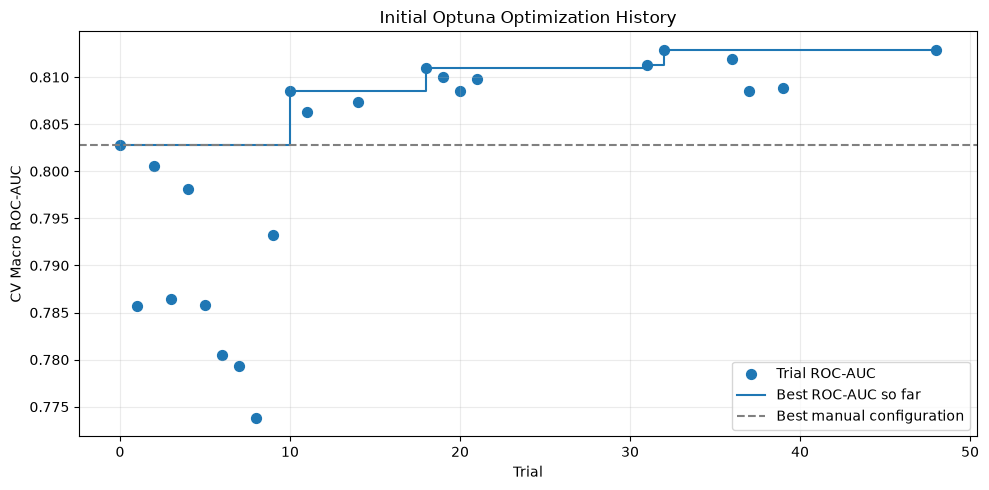

In [74]:
# Plot the initial optimization history

history_optuna_df = (
    initial_complete_df
    .sort_values("number")
    .copy()
)

history_optuna_df["best_so_far"] = (
    history_optuna_df["value"].cummax()
)

manual_best_auc = targeted_results[
    "Higher_WD"
]["summary"]["cv_macro_roc_auc"]

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    history_optuna_df["number"],
    history_optuna_df["value"],
    label="Trial ROC-AUC",
    s=50,
)

ax.step(
    history_optuna_df["number"],
    history_optuna_df["best_so_far"],
    where="post",
    label="Best ROC-AUC so far",
)

ax.axhline(
    manual_best_auc,
    color="gray",
    linestyle="--",
    label="Best manual configuration",
)

ax.set_xlabel("Trial")
ax.set_ylabel("CV Macro ROC-AUC")
ax.set_title("Initial Optuna Optimization History")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## Full Hyperparameter Optimization

In [75]:
# Continue the existing Optuna study

TARGET_N_TRIALS = 50 # Trial 10부터 이어서 실행, 누적 총 50개 목표 (50개를 추가하는게 아님)

completed_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.COMPLETE,),
)

pruned_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.PRUNED,),
)

running_trials = tox21_study.get_trials(
    deepcopy=False,
    states=(optuna.trial.TrialState.RUNNING,),
)

if running_trials:
    raise RuntimeError(
        "Unfinished RUNNING trials detected. "
        "Check the previous optimization session."
    )

n_finished = len(completed_trials) + len(pruned_trials)

n_remaining = max(
    0,
    TARGET_N_TRIALS - n_finished,
)

print("Target trials:", TARGET_N_TRIALS)
print("Completed trials:", len(completed_trials))
print("Pruned trials:", len(pruned_trials))
print("Remaining trials:", n_remaining)

# Resume optimization
start_full_optuna = perf_counter()

if n_remaining > 0:

    tox21_study.optimize(
        optuna_objective,
        n_trials=n_remaining,
        n_jobs=1,
        callbacks=[save_trial_progress],
        gc_after_trial=True,
    )

else:
    print("Target number of trials already reached.")

elapsed_full_optuna = (
    perf_counter() - start_full_optuna
)

optuna_trials_df = export_study_results(
    tox21_study,
    optuna_dir,
)

print(
    f"\nOptimization session time: "
    f"{elapsed_full_optuna:.2f} seconds"
)

print("Best ROC-AUC:", tox21_study.best_value)

Target trials: 50
Completed trials: 23
Pruned trials: 27
Remaining trials: 0
Target number of trials already reached.

Optimization session time: 0.00 seconds
Best ROC-AUC: 0.8128993578620268


In [76]:
# Inspect full Optuna optimization results

trial_state_df = (
    optuna_trials_df["state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="n_trials")
)

print("Trial states:")
display(trial_state_df)

full_complete_df = (
    optuna_trials_df.loc[
        optuna_trials_df["state"] == "COMPLETE" # pruned trial은 제외하고, 완료된 trial만 확인
    ]
    .copy()
    .sort_values("value", ascending=False)
)

print("\nTop 10 completed trials:")

display(
    full_complete_df[
        [
            "number",
            "value",
            "user_attrs_cv_macro_ap",
            "params_hidden_depth",
            "params_first_hidden_dim",
            "params_dropout",
            "params_weight_decay",
            "params_lr",
            "params_batch_size",
            "params_pos_weight_cap",
            "user_attrs_best_epoch_median",
            "user_attrs_elapsed_seconds",
        ]
    ].head(10).style.format({
        "value": "{:.6f}",
        "user_attrs_cv_macro_ap": "{:.6f}",
        "params_dropout": "{:.4f}",
        "params_weight_decay": "{:.3e}",
        "params_lr": "{:.3e}",
        "user_attrs_elapsed_seconds": "{:.2f}",
    }, na_rep="None")
)

print("\nBest trial:", tox21_study.best_trial.number)

print("\nBest parameters:")
print(
    json.dumps(
        tox21_study.best_params,
        indent=4,
    )
)

print(
    "\nBest ROC-AUC:",
    tox21_study.best_value,
)

print(
    "Best AP:",
    tox21_study.best_trial.user_attrs["cv_macro_ap"],
)

print(
    "Mean CV runtime per completed trial:",
    full_complete_df[
        "user_attrs_elapsed_seconds"
    ].mean(),
    "seconds",
)

Trial states:


,state,n_trials
0,PRUNED,27
1,COMPLETE,23



Top 10 completed trials:


,number,value,user_attrs_cv_macro_ap,params_hidden_depth,params_first_hidden_dim,params_dropout,params_weight_decay,params_lr,params_batch_size,params_pos_weight_cap,user_attrs_best_epoch_median,user_attrs_elapsed_seconds
32,32,0.812899,0.392440,2,1024,0.3727,8.726e-03,3.919e-04,128,5.000000,3.000000,91.59
48,48,0.812880,0.390970,2,1024,0.4205,4.566e-03,4.596e-04,128,1.000000,3.000000,97.90
36,36,0.811894,0.395432,2,1024,0.3750,8.020e-03,2.810e-04,128,1.000000,3.000000,103.71
31,31,0.811325,0.393025,2,1024,0.3546,7.755e-03,3.642e-04,128,5.000000,3.000000,90.69
18,18,0.810926,0.387714,2,1024,0.4129,9.595e-03,1.768e-04,128,None,7.000000,120.53
19,19,0.809988,0.382454,2,1024,0.5156,8.581e-03,2.359e-04,64,None,4.000000,143.01
21,21,0.809835,0.390595,2,1024,0.2398,9.200e-03,4.135e-04,128,None,4.000000,107.78
39,39,0.808799,0.395742,2,1024,0.3171,9.503e-03,2.049e-04,128,1.000000,6.000000,144.53
20,20,0.808512,0.385517,2,1024,0.3069,8.749e-03,1.316e-04,64,None,6.000000,152.08
37,37,0.808503,0.385966,2,1024,0.3560,2.844e-03,7.063e-04,128,5.000000,2.000000,101.45



Best trial: 32

Best parameters:
{
    "hidden_depth": 2,
    "first_hidden_dim": 1024,
    "dropout": 0.3727308583919394,
    "weight_decay": 0.008725853153229582,
    "lr": 0.00039185977355857195,
    "batch_size": 128,
    "pos_weight_cap": 5.0
}

Best ROC-AUC: 0.8128993578620268
Best AP: 0.39243962555506645
Mean CV runtime per completed trial: 131.87791362606274 seconds


In [77]:
# Weight decay가 상당히 증가 (앞서 Large 모델에서 overfitting이 빠르게 발생했고, manual exploration에서도 weight decay를 높였을 때 성능이 개선됐었음) -> Optuna에서도 weight decay가 높게 선택됨
# 상위 10개 조건 및 결과 비교:
# 현재 탐색 범위에서는 넓은 2-layer MLP가 유망
# Weight decay의 최적값이 우리가 설정한 search space의 상한보다 더 높을 가능성 있음

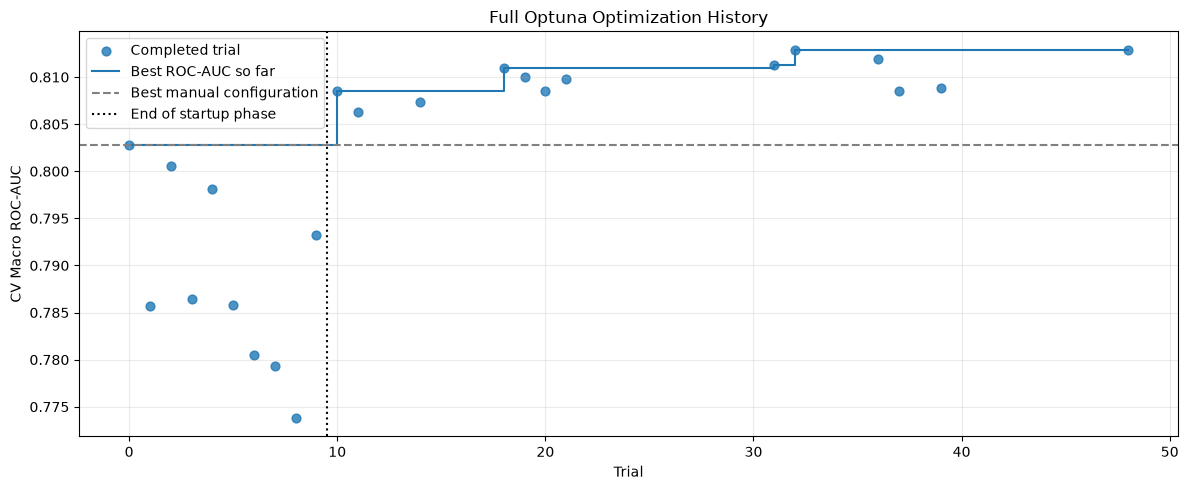

In [78]:
# Plot full Optuna optimization history

full_history_df = (
    full_complete_df
    .sort_values("number")
    .copy()
)

full_history_df["best_so_far"] = (
    full_history_df["value"].cummax()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    full_history_df["number"],
    full_history_df["value"],
    label="Completed trial",
    s=40,
    alpha=0.8,
)

ax.step(
    full_history_df["number"],
    full_history_df["best_so_far"],
    where="post",
    label="Best ROC-AUC so far",
)

ax.axhline(
    manual_best_auc,
    color="gray",
    linestyle="--",
    label="Best manual configuration",
)

ax.axvline(
    9.5,
    color="black",
    linestyle=":",
    label="End of startup phase",
)

ax.set_xlabel("Trial")
ax.set_ylabel("CV Macro ROC-AUC")
ax.set_title("Full Optuna Optimization History")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## Optimization Results Analysis

In [79]:
# Load detailed results of the best completed trial

best_trial = tox21_study.best_trial

best_trial_dir = (
    optuna_dir
    / "trial_results"
    / f"trial_{best_trial.number:05d}"
)

best_fold_df = pd.read_csv(
    best_trial_dir / "fold_df.csv"
)

best_history_df = pd.read_csv(
    best_trial_dir / "history_df.csv"
)

best_per_task_cv_df = pd.read_csv(
    best_trial_dir / "per_task_cv_df.csv"
)

display(
    best_fold_df[
        [
            "fold_id",
            "best_epoch",
            "epochs_run",
            "best_val_roc_auc",
            "best_val_ap",
            "stopped_early",
        ]
    ].round(4)
)

assert len(best_history_df) == (
    best_fold_df["epochs_run"].sum()
)

print("Best trial:", best_trial.number)

print(
    "Best epochs:",
    best_fold_df["best_epoch"].tolist(),
)

print(
    "Total training epochs across five folds:",
    best_fold_df["epochs_run"].sum(),
)

print(
    "Median best epoch:",
    best_fold_df["best_epoch"].median(),
)

,fold_id,best_epoch,epochs_run,best_val_roc_auc,best_val_ap,stopped_early
0,0,3,13,0.8404,0.4707,True
1,1,3,13,0.8159,0.3330,True
2,2,2,12,0.8521,0.5088,True
3,3,3,13,0.7706,0.2871,True
4,4,2,12,0.7854,0.3626,True


Best trial: 32
Best epochs: [3, 3, 2, 3, 2]
Total training epochs across five folds: 63
Median best epoch: 3.0


,parameter,importance
0,first_hidden_dim,0.8086
1,weight_decay,0.1281
2,batch_size,0.0176
3,hidden_depth,0.0170
4,lr,0.0137
5,dropout,0.0109
6,pos_weight_cap,0.0041


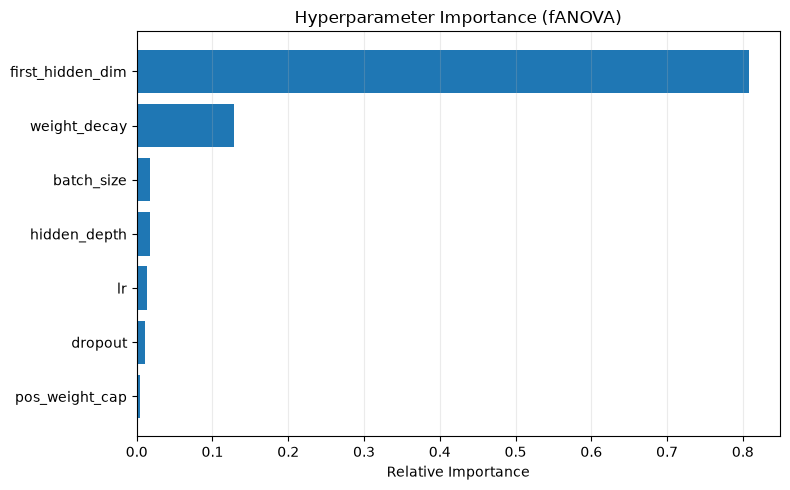

In [80]:
# Calculate hyperparameter importance using fANOVA: hyperparameter에 따른 모델 성능의 변동을 분석 (무엇을 조절하는게 중요한지 알려줌)
## Importance가 높으면 해당 hyperparameter가 모델 성능에 미치는 영향이 크다 -> 맞음
## 해당 hyperparameter를 우선적으로 최적화할 가치가 있다 -> 맞음
##해당 hyperparameter를 변경하면 반드시 성능이 좋아진다 -> 보장할 수 없음
## Importance만으로 값이 높아야 하는지 낮아야 하는지는 알 수 없다 -> 맞음
from optuna.importance import (
    get_param_importances,
    FanovaImportanceEvaluator,
)

importance_scores = get_param_importances(
    tox21_study,
    evaluator=FanovaImportanceEvaluator(
        seed=SEED,
    ),
)

importance_df = (
    pd.Series(
        importance_scores,
        name="importance",
    )
    .rename_axis("parameter")
    .reset_index()
)

display(importance_df.round(4))

plot_df = importance_df.sort_values(
    "importance",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    plot_df["parameter"],
    plot_df["importance"],
)

ax.set_xlabel("Relative Importance")
ax.set_title("Hyperparameter Importance (fANOVA)")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

importance_df.to_csv(
    optuna_dir / "parameter_importance.csv",
    index=False,
)

In [81]:
# limitation: used only completed trials, pruned trials are ignored -> selection bias may occur, so only for exploratory analysis

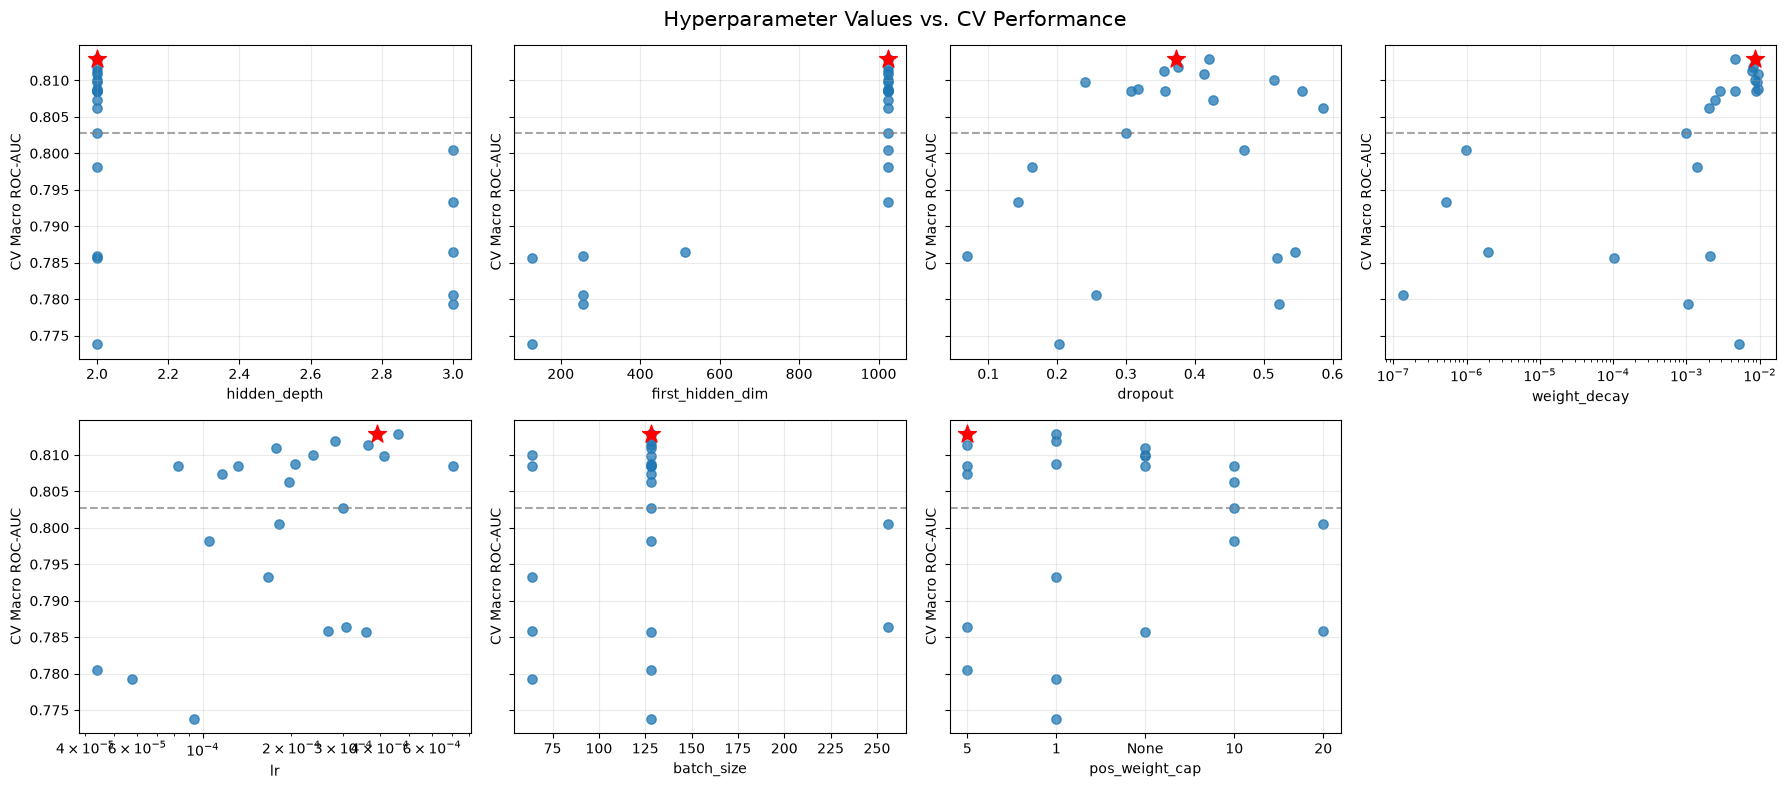

In [82]:
# Analyze hyperparameter values and CV performance

parameter_names = [
    "hidden_depth",
    "first_hidden_dim",
    "dropout",
    "weight_decay",
    "lr",
    "batch_size",
    "pos_weight_cap",
]

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 8),
    sharey=True,
)

for ax, name in zip(
    axes.flatten(),
    parameter_names,
):

    col = f"params_{name}"

    x = full_complete_df[col]

    # Preserve uncapped class weighting as a category
    if name == "pos_weight_cap":
        x = x.map(
            lambda v: "None"
            if pd.isna(v)
            else str(int(v))
        )

    ax.scatter(
        x,
        full_complete_df["value"],
        alpha=0.75,
        s=45,
    )

    best_x = best_trial.params[name]

    if name == "pos_weight_cap":
        best_x = (
            "None"
            if best_x is None
            else str(int(best_x))
        )

    ax.scatter(
        best_x,
        best_trial.value,
        marker="*",
        color="red",
        s=180,
        label="Best trial",
        zorder=5,
    )

    if name in ["weight_decay", "lr"]:
        ax.set_xscale("log")

    ax.axhline(
        manual_best_auc,
        color="gray",
        linestyle="--",
        alpha=0.7,
    )

    ax.set_xlabel(name)
    ax.set_ylabel("CV Macro ROC-AUC")
    ax.grid(alpha=0.25)

axes.flatten()[-1].set_visible(False)

plt.suptitle(
    "Hyperparameter Values vs. CV Performance",
    fontsize=15,
)

plt.tight_layout()
plt.show()

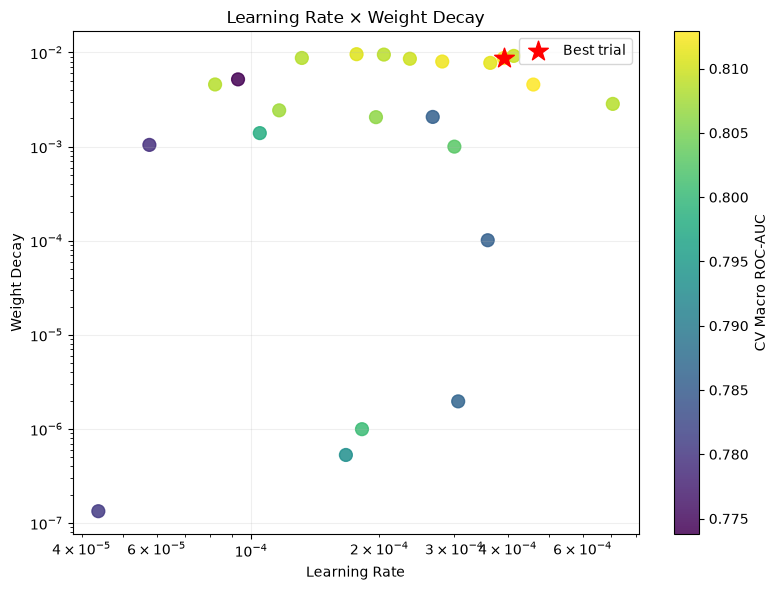

In [83]:
# Analyze learning rate and weight decay interactions
# 현재 Adam에서는 learning rate와 weight decay가 함께 실제 parameter 업데이트에 영향을 주기 때문에 두 값의 조합을 확인하는 것이 유용

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    full_complete_df["params_lr"],
    full_complete_df["params_weight_decay"],
    c=full_complete_df["value"],
    cmap="viridis",
    s=85,
    alpha=0.85,
)

ax.scatter(
    best_trial.params["lr"],
    best_trial.params["weight_decay"],
    marker="*",
    color="red",
    s=220,
    label="Best trial",
    zorder=5,
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Learning Rate")
ax.set_ylabel("Weight Decay")

ax.set_title(
    "Learning Rate × Weight Decay"
)

fig.colorbar(
    scatter,
    ax=ax,
    label="CV Macro ROC-AUC",
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

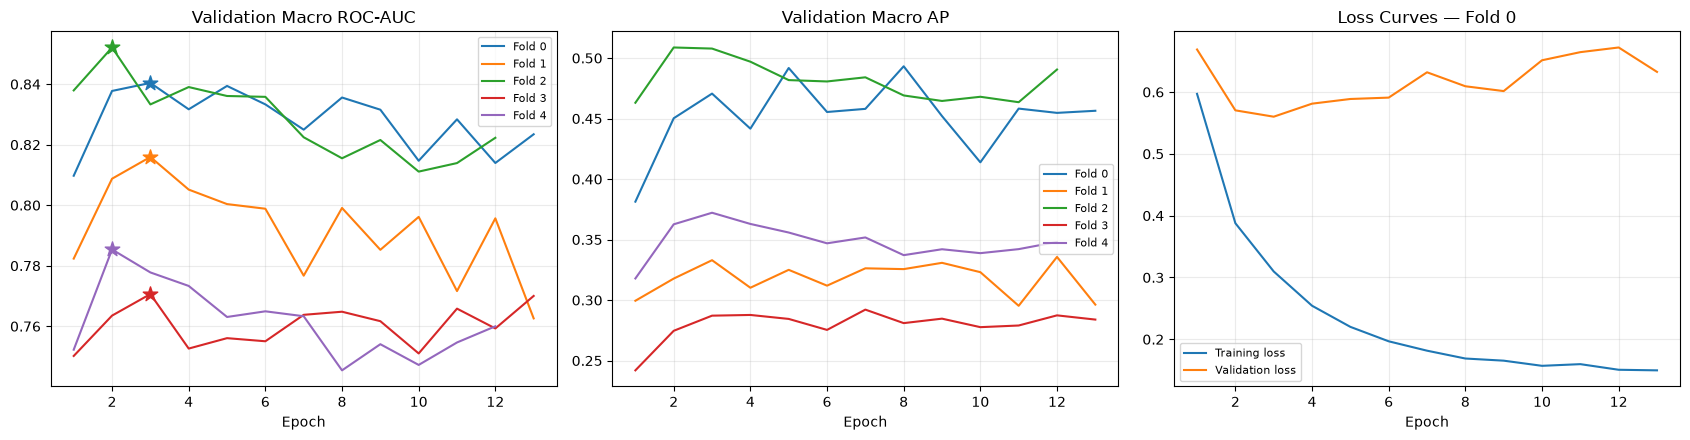

In [84]:
# Compare learning curves of the best Optuna trial
# 이전에 빠르게 증가한 validation loss가 완화되었는지 확인
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5),
)

for fold_id, h in best_history_df.groupby("fold_id"):

    h = h.sort_values("epoch")

    best_epoch = int(
        best_fold_df.loc[
            best_fold_df["fold_id"] == fold_id,
            "best_epoch",
        ].iloc[0]
    )

    # Validation ROC-AUC
    line, = axes[0].plot(
        h["epoch"],
        h["val_mean_roc_auc"],
        label=f"Fold {fold_id}",
    )

    best_auc = h.loc[
        h["epoch"] == best_epoch,
        "val_mean_roc_auc",
    ].iloc[0]

    axes[0].scatter(
        best_epoch,
        best_auc,
        marker="*",
        color=line.get_color(),
        s=120,
        zorder=5,
    )

    # Validation AP
    axes[1].plot(
        h["epoch"],
        h["val_mean_ap"],
        label=f"Fold {fold_id}",
    )

# Loss curves on Fold 0
h0 = best_history_df.loc[
    best_history_df["fold_id"] == 0
].sort_values("epoch")

axes[2].plot(
    h0["epoch"],
    h0["train_loss"],
    label="Training loss",
)

axes[2].plot(
    h0["epoch"],
    h0["val_loss"],
    label="Validation loss",
)

axes[0].set_title("Validation Macro ROC-AUC")
axes[1].set_title("Validation Macro AP")
axes[2].set_title("Loss Curves — Fold 0")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [85]:
# Weight decay가 0.01 상한 부근에 집중 -> 상한을 확대하는 제한적인 추가 실험?
# First hidden dimension 1024가 우세 -> 2048 규모의 모델도 탐색할 가치가 있는지
# 상위 trial들의 성능이 거의 동일 -> Multi-seed robustness
# 추가 40개 중 27개가 PRUNED -> Pruning에 의해 좋은 후보가 제외됐을 가능성?

## Search Space Boundary Exploration

In [86]:
# Define configurations beyond the original search boundaries
# For first_hidden_dim & weight_decay (1. high hyperparameter importance / 2. best trial is at the boundary of the search space)
from time import perf_counter

boundary_dir = (
    dl_results_dir / "boundary_exploration_v1"
)

boundary_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Retrieve the exact best configuration
boundary_reference_trial = tox21_study.best_trial

assert boundary_reference_trial.number == 32

boundary_base_config = dict(
    boundary_reference_trial.user_attrs["config"]
)

boundary_base_config["hidden_dims"] = tuple(
    boundary_base_config["hidden_dims"]
)

# Define additional configurations
boundary_configs = {
    "A_Higher_WD": {
        **boundary_base_config,
        "weight_decay": 0.02,
    },
    "B_Highest_WD": {
        **boundary_base_config,
        "weight_decay": 0.05,
    },
    "C_Wider": {
        **boundary_base_config,
        "hidden_dims": (2048, 1024),
    },
    "D_Wider_Higher_WD": {
        **boundary_base_config,
        "hidden_dims": (2048, 1024),
        "weight_decay": 0.02,
    },
    "E_Wider_Highest_WD": {
        **boundary_base_config,
        "hidden_dims": (2048, 1024),
        "weight_decay": 0.05,
    },
}

boundary_config_df = pd.DataFrame.from_dict(
    {
        "Trial_32": boundary_base_config,
        **boundary_configs,
    },
    orient="index",
)

display(boundary_config_df)

,max_epochs,patience,selection_metric,seed,device,verbose,hidden_dims,dropout,weight_decay,lr,batch_size,pos_weight_cap
Trial_32,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.008726,0.000392,128,5.0
A_Higher_WD,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.020000,0.000392,128,5.0
B_Highest_WD,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.050000,0.000392,128,5.0
C_Wider,100,10,roc_auc,42,cpu,False,"(2048, 1024)",0.372731,0.008726,0.000392,128,5.0
D_Wider_Higher_WD,100,10,roc_auc,42,cpu,False,"(2048, 1024)",0.372731,0.020000,0.000392,128,5.0
E_Wider_Highest_WD,100,10,roc_auc,42,cpu,False,"(2048, 1024)",0.372731,0.050000,0.000392,128,5.0


In [87]:
# Run boundary exploration without pruning

# Load the existing reference results
with (best_trial_dir / "summary.json").open(
    "r", encoding="utf-8"
) as f:
    boundary_reference_summary = json.load(f)

boundary_reference_folds = pd.read_csv(
    best_trial_dir / "fold_df.csv"
)

assert np.isclose(
    boundary_reference_summary["cv_macro_roc_auc"],
    boundary_reference_trial.value,
)

# Reuse Trial 32 without retraining
boundary_results = {
    "Trial_32": {
        "config": boundary_base_config,
        "summary": boundary_reference_summary,
        "fold_df": boundary_reference_folds,
    }
}

boundary_summary_rows = [{
    "configuration": "Trial_32",
    "hidden_dims": boundary_base_config["hidden_dims"],
    "weight_decay": boundary_base_config["weight_decay"],
    **boundary_reference_summary,
}]

start_boundary = perf_counter()

for name, config in boundary_configs.items():

    print(f"\n{'=' * 60}")
    print(f"Configuration: {name}")
    print(f"Hidden dimensions: {config['hidden_dims']}")
    print(f"Weight decay: {config['weight_decay']}")
    print(f"{'=' * 60}")

    result = run_multitask_cv(
        train_df=train_df,
        X_train_all=X_train_all,
        target_cols=target_cols,
        fold_df=fold_df,
        config=config,
        verbose=True,
    )

    boundary_results[name] = result

    boundary_summary_rows.append({
        "configuration": name,
        "hidden_dims": config["hidden_dims"],
        "weight_decay": config["weight_decay"],
        **result["summary"],
    })

    # Save detailed results
    result_dir = boundary_dir / name.lower()

    result_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    with (result_dir / "config.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(result["config"], f, indent=4)

    with (result_dir / "summary.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(result["summary"], f, indent=4)

    for key in [
        "fold_df",
        "per_task_fold_df",
        "per_task_cv_df",
        "history_df",
        "per_task_history_df",
    ]:
        result[key].to_csv(
            result_dir / f"{key}.csv",
            index=False,
        )

    # Update the summary after each configuration
    boundary_summary_df = (
        pd.DataFrame(boundary_summary_rows)
        .sort_values(
            "cv_macro_roc_auc",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    boundary_summary_df.to_csv(
        boundary_dir / "boundary_summary.csv",
        index=False,
    )

elapsed_boundary = perf_counter() - start_boundary

print(
    f"\nTotal boundary exploration time: "
    f"{elapsed_boundary:.2f} seconds"
)

display(boundary_summary_df.round(6))


Configuration: A_Higher_WD
Hidden dimensions: (1024, 512)
Weight decay: 0.02
Fold 1/5 (fold_id=0)
  Best epoch=8 | ROC-AUC=0.8474 | AP=0.5029
Fold 2/5 (fold_id=1)
  Best epoch=2 | ROC-AUC=0.8217 | AP=0.3308
Fold 3/5 (fold_id=2)
  Best epoch=2 | ROC-AUC=0.8506 | AP=0.5030
Fold 4/5 (fold_id=3)
  Best epoch=3 | ROC-AUC=0.7754 | AP=0.2842
Fold 5/5 (fold_id=4)
  Best epoch=3 | ROC-AUC=0.7820 | AP=0.3651

Configuration: B_Highest_WD
Hidden dimensions: (1024, 512)
Weight decay: 0.05
Fold 1/5 (fold_id=0)
  Best epoch=8 | ROC-AUC=0.8538 | AP=0.4928
Fold 2/5 (fold_id=1)
  Best epoch=2 | ROC-AUC=0.8269 | AP=0.3441
Fold 3/5 (fold_id=2)
  Best epoch=6 | ROC-AUC=0.8481 | AP=0.4865
Fold 4/5 (fold_id=3)
  Best epoch=17 | ROC-AUC=0.7787 | AP=0.3113
Fold 5/5 (fold_id=4)
  Best epoch=3 | ROC-AUC=0.7833 | AP=0.3610

Configuration: C_Wider
Hidden dimensions: (2048, 1024)
Weight decay: 0.008725853153229582
Fold 1/5 (fold_id=0)
  Best epoch=2 | ROC-AUC=0.8399 | AP=0.4614
Fold 2/5 (fold_id=1)
  Best epoch=3 

,configuration,hidden_dims,weight_decay,n_folds,n_tasks,cv_macro_roc_auc,cv_macro_ap,fold_macro_roc_auc_std,fold_macro_ap_std,cv_macro_ap_baseline,best_epoch_median,elapsed_seconds
0,E_Wider_Highest_WD,"(2048, 1024)",0.050000,5,12,0.819014,0.398143,0.030567,0.077159,0.073397,9.0,274.423781
1,B_Highest_WD,"(1024, 512)",0.050000,5,12,0.818166,0.399127,0.035397,0.084569,0.073397,6.0,129.075958
2,A_Higher_WD,"(1024, 512)",0.020000,5,12,0.815419,0.397205,0.035429,0.100716,0.073397,3.0,98.960781
3,D_Wider_Higher_WD,"(2048, 1024)",0.020000,5,12,0.814967,0.397775,0.029887,0.078834,0.073397,6.0,258.113132
4,Trial_32,"(1024, 512)",0.008726,5,12,0.812899,0.392440,0.034817,0.093759,0.073397,3.0,91.591980
5,C_Wider,"(2048, 1024)",0.008726,5,12,0.811473,0.383091,0.031204,0.083347,0.073397,3.0,174.027229


In [88]:
# Compare boundary configurations against Trial 32

reference_folds = (
    boundary_results["Trial_32"]["fold_df"]
    .set_index("fold_id")
)

boundary_comparison_rows = []

for name, result in boundary_results.items():

    current_folds = (
        result["fold_df"]
        .set_index("fold_id")
        .loc[reference_folds.index]
    )

    auc_delta = (
        current_folds["best_val_roc_auc"]
        - reference_folds["best_val_roc_auc"]
    )

    ap_delta = (
        current_folds["best_val_ap"]
        - reference_folds["best_val_ap"]
    )

    boundary_comparison_rows.append({
        "configuration": name,
        "roc_auc_delta": auc_delta.mean(),
        "ap_delta": ap_delta.mean(),
        "n_folds_auc_improved": int(
            (auc_delta > 0).sum()
        ),
        "n_folds_ap_improved": int(
            (ap_delta > 0).sum()
        ),
        "best_epoch_median": (
            current_folds["best_epoch"].median()
        ),
        "epochs_run_mean": (
            current_folds["epochs_run"].mean()
        ),
    })

boundary_comparison_df = (
    pd.DataFrame(boundary_comparison_rows)
    .sort_values(
        "roc_auc_delta",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(boundary_comparison_df.round(6))

boundary_comparison_df.to_csv(
    boundary_dir / "boundary_comparison.csv",
    index=False,
)

,configuration,roc_auc_delta,ap_delta,n_folds_auc_improved,n_folds_ap_improved,best_epoch_median,epochs_run_mean
0,E_Wider_Highest_WD,0.006115,0.005704,4,3,9.0,17.8
1,B_Highest_WD,0.005267,0.006687,3,3,6.0,17.2
2,A_Higher_WD,0.002520,0.004765,3,2,3.0,13.6
3,D_Wider_Higher_WD,0.002068,0.005336,3,3,6.0,18.8
4,Trial_32,0.000000,0.000000,0,0,3.0,12.6
5,C_Wider,-0.001426,-0.009349,2,1,3.0,13.0


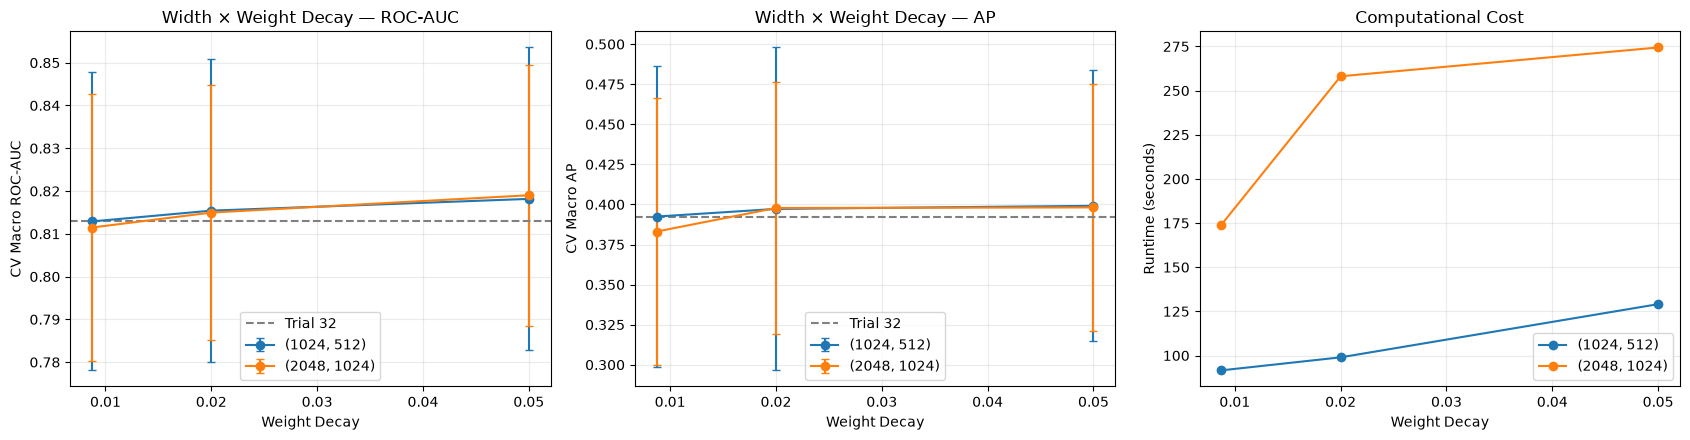

In [89]:
# Visualize width and weight decay interactions

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5),
)

for hidden_dims in [
    (1024, 512),
    (2048, 1024),
]:

    subset = boundary_summary_df.loc[
        boundary_summary_df["hidden_dims"].map(
            lambda dims: tuple(dims) == hidden_dims
        )
    ].sort_values("weight_decay")

    label = str(hidden_dims)

    axes[0].errorbar(
        subset["weight_decay"],
        subset["cv_macro_roc_auc"],
        yerr=subset["fold_macro_roc_auc_std"],
        marker="o",
        capsize=3,
        label=label,
    )

    axes[1].errorbar(
        subset["weight_decay"],
        subset["cv_macro_ap"],
        yerr=subset["fold_macro_ap_std"],
        marker="o",
        capsize=3,
        label=label,
    )

    axes[2].plot(
        subset["weight_decay"],
        subset["elapsed_seconds"],
        marker="o",
        label=label,
    )

axes[0].axhline(
    boundary_reference_summary["cv_macro_roc_auc"],
    color="gray",
    linestyle="--",
    label="Trial 32",
)

axes[1].axhline(
    boundary_reference_summary["cv_macro_ap"],
    color="gray",
    linestyle="--",
    label="Trial 32",
)

axes[0].set_title("Width × Weight Decay — ROC-AUC")
axes[0].set_ylabel("CV Macro ROC-AUC")

axes[1].set_title("Width × Weight Decay — AP")
axes[1].set_ylabel("CV Macro AP")

axes[2].set_title("Computational Cost")
axes[2].set_ylabel("Runtime (seconds)")

for ax in axes:
    ax.set_xlabel("Weight Decay")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

In [90]:
# 두 architecture 모두 weight decay가 증가하면서 ROC-AUC가 개선 / 반면 동일한 weight decay에서 모델 크기를 증가시켰을 때는 성능이 반드시 좋아지지는 않음
# Configuration B가 꽤 매력적인 후보: E보다 ROC-AUC는 0.000848 낮지만, AP는 오히려 높고 parameter 수는 약 58% 적으며 학습 시간도 약 43% 짧기 때문
# 다만 E의 fold 간 성능 변동성은 B보다 작았고 아직 seed를 하나만 사용했으므로 최종 선택은 보류

# Weight decay를 0.1까지 더 높여볼까? No -> 아직 0.05에서도 성능이 증가하고 있으므로 더 높은 값이 유리할 가능성은 있지만, 
# 동일한 CV 데이터에 대해서 반복적으로 최적화할수록 model selection bias가 커질수 있음 (overfitting to the CV folds)

# [14] Robustness & Final Model Selection

## Multi-seed Robustness Evaluation

In [91]:
# Define candidates for multi-seed robustness evaluation (compare 5 different configurations with 3 different random seeds)

import json
from time import perf_counter

ROBUSTNESS_SEEDS = [42, 123, 2026]

robustness_dir = (
    dl_results_dir / "robustness_v1"
)

robustness_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Locate the existing seed-42 results
robustness_source_dirs = {
    "E_Wider_Highest_WD": (
        boundary_dir / "e_wider_highest_wd"
    ),
    "B_Highest_WD": (
        boundary_dir / "b_highest_wd"
    ),
    "A_Higher_WD": (
        boundary_dir / "a_higher_wd"
    ),
    "Trial_32": (
        optuna_dir / "trial_results" / "trial_00032"
    ),
    "Trial_48": (   # class weighting을 적용하지 않았는데도 Trial 32와 거의 동일한 성능을 기록
        optuna_dir / "trial_results" / "trial_00048"
    ),
}

robustness_configs = {}

for name, source_dir in robustness_source_dirs.items():

    with (source_dir / "config.json").open(
        "r", encoding="utf-8"
    ) as f:
        config = json.load(f)

    config["hidden_dims"] = tuple(
        config["hidden_dims"]
    )

    assert config["seed"] == 42
    assert config["device"] == "cpu"
    assert config["selection_metric"] == "roc_auc"

    robustness_configs[name] = config

robustness_config_df = pd.DataFrame.from_dict(
    robustness_configs,
    orient="index",
)

display(robustness_config_df)

print("Number of candidates:", len(robustness_configs))
print("Robustness seeds:", ROBUSTNESS_SEEDS)

,max_epochs,patience,selection_metric,seed,device,verbose,hidden_dims,dropout,weight_decay,lr,batch_size,pos_weight_cap
E_Wider_Highest_WD,100,10,roc_auc,42,cpu,False,"(2048, 1024)",0.372731,0.050000,0.000392,128,5.0
B_Highest_WD,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.050000,0.000392,128,5.0
A_Higher_WD,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.020000,0.000392,128,5.0
Trial_32,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.372731,0.008726,0.000392,128,5.0
Trial_48,100,10,roc_auc,42,cpu,False,"(1024, 512)",0.420480,0.004566,0.000460,128,1.0


Number of candidates: 5
Robustness seeds: [42, 123, 2026]


In [92]:
# Run multi-seed robustness experiments
# load the existing seed-42 results and reuse them, then train the other seeds from scratch
robustness_summary_rows = []
robustness_fold_rows = []

start_robustness = perf_counter()

for name, base_config in robustness_configs.items():

    for seed in ROBUSTNESS_SEEDS:

        config = {
            **base_config,
            "seed": seed,
        }

        print(f"\n{'=' * 60}")
        print(f"Configuration: {name}")
        print(f"Training seed: {seed}")
        print(f"{'=' * 60}")

        if seed == 42:

            # Reuse the existing seed-42 results
            source_dir = robustness_source_dirs[name]

            with (source_dir / "summary.json").open(
                "r", encoding="utf-8"
            ) as f:
                summary = json.load(f)

            folds = pd.read_csv(
                source_dir / "fold_df.csv"
            )

            reused = True

            print("Reusing existing seed-42 results.")

        else:

            # Train all five folds with a new seed
            result = run_multitask_cv(
                train_df=train_df,
                X_train_all=X_train_all,
                target_cols=target_cols,
                fold_df=fold_df,
                config=config,
                verbose=True,
            )

            summary = result["summary"]
            folds = result["fold_df"]

            reused = False

            # Save detailed CV results
            result_dir = (
                robustness_dir
                / name.lower()
                / f"seed_{seed}"
            )

            result_dir.mkdir(
                parents=True,
                exist_ok=True,
            )

            with (result_dir / "config.json").open(
                "w", encoding="utf-8"
            ) as f:
                json.dump(
                    result["config"],
                    f,
                    indent=4,
                )

            with (result_dir / "summary.json").open(
                "w", encoding="utf-8"
            ) as f:
                json.dump(
                    summary,
                    f,
                    indent=4,
                )

            for key in [
                "fold_df",
                "per_task_fold_df",
                "per_task_cv_df",
                "history_df",
                "per_task_history_df",
            ]:
                result[key].to_csv(
                    result_dir / f"{key}.csv",
                    index=False,
                )

        # Validate fold coverage and metric aggregation
        assert len(folds) == 5
        assert set(folds["fold_id"]) == set(range(5))
        assert folds["seed"].eq(seed).all()

        assert np.isclose(
            summary["cv_macro_roc_auc"],
            folds["best_val_roc_auc"].mean(),
        )

        assert np.isclose(
            summary["cv_macro_ap"],
            folds["best_val_ap"].mean(),
        )

        # Collect seed-level results
        robustness_summary_rows.append({
            "configuration": name,
            "seed": seed,
            "reused": reused,
            **summary,
        })

        # Collect fold-level results
        robustness_fold_rows.append(
            folds.assign(configuration=name)
        )

        robustness_seed_df = pd.DataFrame(
            robustness_summary_rows
        )

        robustness_fold_df = pd.concat(
            robustness_fold_rows,
            ignore_index=True,
        )

        # Update saved results after every experiment
        robustness_seed_df.to_csv(
            robustness_dir / "seed_results.csv",
            index=False,
        )

        robustness_fold_df.to_csv(
            robustness_dir / "fold_results.csv",
            index=False,
        )

        print(
            f"Macro ROC-AUC: "
            f"{summary['cv_macro_roc_auc']:.6f}"
        )

        print(
            f"Macro AP: "
            f"{summary['cv_macro_ap']:.6f}"
        )

elapsed_robustness = (
    perf_counter() - start_robustness
)

print(
    f"\nTotal robustness evaluation time: "
    f"{elapsed_robustness:.2f} seconds"
)

display(robustness_seed_df.round(6))


Configuration: E_Wider_Highest_WD
Training seed: 42
Reusing existing seed-42 results.
Macro ROC-AUC: 0.819014
Macro AP: 0.398143

Configuration: E_Wider_Highest_WD
Training seed: 123
Fold 1/5 (fold_id=0)
  Best epoch=2 | ROC-AUC=0.8495 | AP=0.4778
Fold 2/5 (fold_id=1)
  Best epoch=5 | ROC-AUC=0.8232 | AP=0.3325
Fold 3/5 (fold_id=2)
  Best epoch=11 | ROC-AUC=0.8551 | AP=0.4987
Fold 4/5 (fold_id=3)
  Best epoch=20 | ROC-AUC=0.8000 | AP=0.3044
Fold 5/5 (fold_id=4)
  Best epoch=3 | ROC-AUC=0.7950 | AP=0.3564
Macro ROC-AUC: 0.824570
Macro AP: 0.393953

Configuration: E_Wider_Highest_WD
Training seed: 2026
Fold 1/5 (fold_id=0)
  Best epoch=7 | ROC-AUC=0.8440 | AP=0.4787
Fold 2/5 (fold_id=1)
  Best epoch=6 | ROC-AUC=0.8233 | AP=0.3092
Fold 3/5 (fold_id=2)
  Best epoch=5 | ROC-AUC=0.8463 | AP=0.4969
Fold 4/5 (fold_id=3)
  Best epoch=2 | ROC-AUC=0.7912 | AP=0.3086
Fold 5/5 (fold_id=4)
  Best epoch=2 | ROC-AUC=0.7914 | AP=0.3554
Macro ROC-AUC: 0.819228
Macro AP: 0.389751

Configuration: B_Highe

,configuration,seed,reused,n_folds,n_tasks,cv_macro_roc_auc,cv_macro_ap,fold_macro_roc_auc_std,fold_macro_ap_std,cv_macro_ap_baseline,best_epoch_median,elapsed_seconds
0,E_Wider_Highest_WD,42,True,5,12,0.819014,0.398143,0.030567,0.077159,0.073397,9.0,274.423781
1,E_Wider_Highest_WD,123,False,5,12,0.824570,0.393953,0.027540,0.088337,0.073397,5.0,234.575797
2,E_Wider_Highest_WD,2026,False,5,12,0.819228,0.389751,0.027029,0.091722,0.073397,5.0,191.172636
3,B_Highest_WD,42,True,5,12,0.818166,0.399127,0.035397,0.084569,0.073397,6.0,129.075958
4,B_Highest_WD,123,False,5,12,0.818279,0.387604,0.029913,0.090285,0.073397,5.0,114.538192
5,B_Highest_WD,2026,False,5,12,0.820798,0.401561,0.026394,0.079173,0.073397,7.0,127.879615
6,A_Higher_WD,42,True,5,12,0.815419,0.397205,0.035429,0.100716,0.073397,3.0,98.960781
7,A_Higher_WD,123,False,5,12,0.816721,0.393832,0.033348,0.092511,0.073397,3.0,102.854080
8,A_Higher_WD,2026,False,5,12,0.816523,0.400925,0.031064,0.074698,0.073397,2.0,103.101806
9,Trial_32,42,True,5,12,0.812899,0.392440,0.034817,0.093759,0.073397,3.0,91.591980


In [93]:
# Aggregate performance across training seeds

# Verify experimental coverage
assert len(robustness_seed_df) == 15
assert len(robustness_fold_df) == 75

assert not robustness_seed_df.duplicated(
    ["configuration", "seed"]
).any()

assert not robustness_fold_df.duplicated(
    ["configuration", "seed", "fold_id"]
).any()

assert (
    robustness_seed_df
    .groupby("configuration")["seed"]
    .nunique()
    .eq(3)
    .all()
)

# Aggregate seed-level performance
robustness_summary_df = (
    robustness_seed_df
    .groupby("configuration", sort=False)
    .agg(
        n_seeds=("seed", "nunique"),

        roc_auc_mean=("cv_macro_roc_auc", "mean"),
        roc_auc_seed_std=("cv_macro_roc_auc", "std"),
        roc_auc_min=("cv_macro_roc_auc", "min"),
        roc_auc_max=("cv_macro_roc_auc", "max"),

        ap_mean=("cv_macro_ap", "mean"),
        ap_seed_std=("cv_macro_ap", "std"),

        mean_fold_auc_std=(
            "fold_macro_roc_auc_std", "mean"
        ),

        mean_runtime_seconds=(
            "elapsed_seconds", "mean"
        ),
    )
    .reset_index()
)

# Separately evaluate the two previously unseen seeds
new_seed_summary = (
    robustness_seed_df.loc[
        robustness_seed_df["seed"] != 42
    ]
    .groupby("configuration")
    .agg(
        new_seed_auc_mean=("cv_macro_roc_auc", "mean"),
        new_seed_ap_mean=("cv_macro_ap", "mean"),
    )
    .reset_index()
)

robustness_summary_df = (
    robustness_summary_df
    .merge(
        new_seed_summary,
        on="configuration",
        validate="one_to_one",
    )
    .sort_values(
        "roc_auc_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(robustness_summary_df.round(6))

robustness_summary_df.to_csv(
    robustness_dir / "robustness_summary.csv",
    index=False,
)

print("All multi-seed robustness checks passed.")

,configuration,n_seeds,roc_auc_mean,roc_auc_seed_std,roc_auc_min,roc_auc_max,ap_mean,ap_seed_std,mean_fold_auc_std,mean_runtime_seconds,new_seed_auc_mean,new_seed_ap_mean
0,E_Wider_Highest_WD,3,0.820937,0.003148,0.819014,0.824570,0.393949,0.004196,0.028379,233.390738,0.821899,0.391852
1,B_Highest_WD,3,0.819081,0.001488,0.818166,0.820798,0.396098,0.007455,0.030568,123.831255,0.819539,0.394583
2,A_Higher_WD,3,0.816221,0.000702,0.815419,0.816721,0.397321,0.003548,0.033280,101.638889,0.816622,0.397379
3,Trial_48,3,0.815144,0.003672,0.812880,0.819380,0.400720,0.008676,0.031958,112.169031,0.816275,0.405595
4,Trial_32,3,0.813673,0.000680,0.812899,0.814175,0.394136,0.002728,0.032897,100.033566,0.814060,0.394984


All multi-seed robustness checks passed.


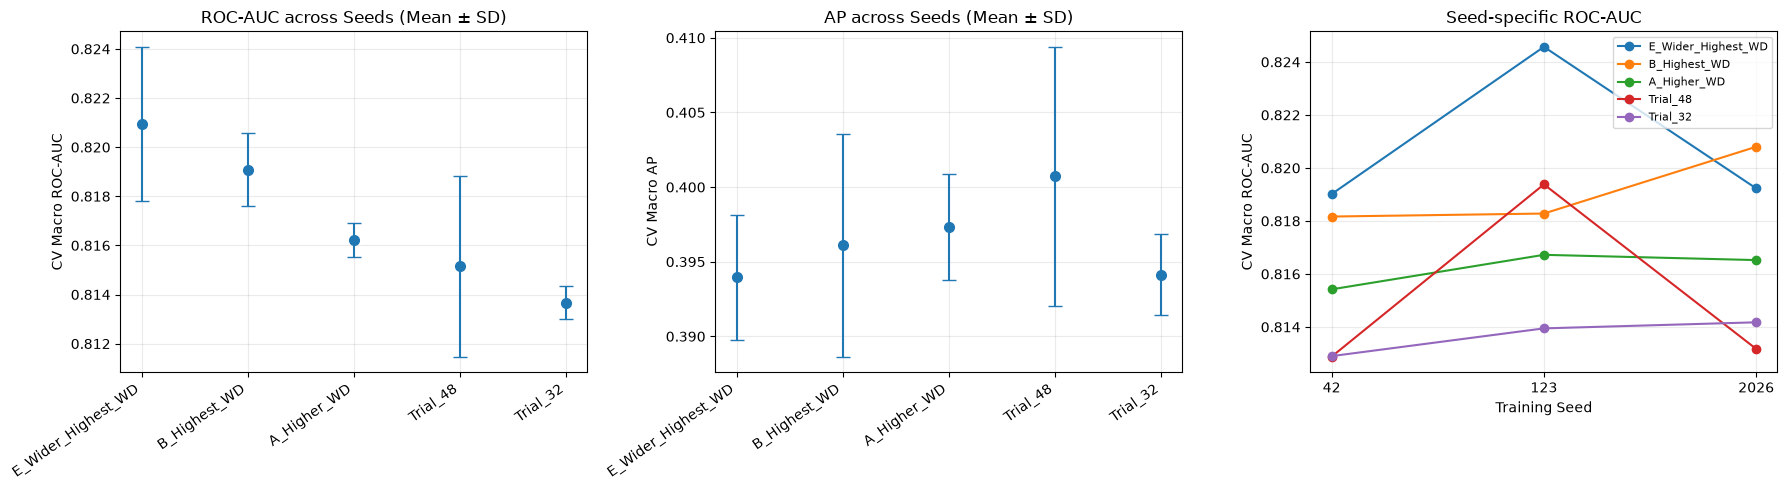

In [94]:
# Visualize robustness across training seeds

plot_df = robustness_summary_df.copy()

names = plot_df["configuration"].tolist()
x = np.arange(len(names))

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
)

# Mean ROC-AUC across seeds
axes[0].errorbar(
    x,
    plot_df["roc_auc_mean"],
    yerr=plot_df["roc_auc_seed_std"],
    fmt="o",
    capsize=5,
    markersize=7,
)

axes[0].set_title("ROC-AUC across Seeds (Mean ± SD)")
axes[0].set_ylabel("CV Macro ROC-AUC")

# Mean AP across seeds
axes[1].errorbar(
    x,
    plot_df["ap_mean"],
    yerr=plot_df["ap_seed_std"],
    fmt="o",
    capsize=5,
    markersize=7,
)

axes[1].set_title("AP across Seeds (Mean ± SD)")
axes[1].set_ylabel("CV Macro AP")

# Seed-specific performance
for name in names:

    subset = robustness_seed_df.loc[
        robustness_seed_df["configuration"] == name
    ].sort_values("seed")

    axes[2].plot(
        subset["seed"].astype(str),
        subset["cv_macro_roc_auc"],
        marker="o",
        label=name,
    )

axes[2].set_title("Seed-specific ROC-AUC")
axes[2].set_xlabel("Training Seed")
axes[2].set_ylabel("CV Macro ROC-AUC")
axes[2].legend(fontsize=8)

for ax in axes[:2]:

    ax.set_xticks(x)

    ax.set_xticklabels(
        names,
        rotation=35,
        ha="right",
    )

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [95]:
# 주로 사용되는 평가 기준: 1. Multi-seed Mean Macro ROC-AUC / 2. 새로운 두 seed에서의 성능 / 3. Mean Macro AP / **4. Seed 및 fold 간 성능 안정성 / **5. 모델 복잡도 및 계산 비용
# E를 최종 모델로 선택 - 1 & 2에서 가장 우수한 성능을 기록했고, 4에서도 fold 간 성능 변동성이 가장 낮았음 / B는 3, 5에서 E보다 우수, 4에서도 seed간 안정성이 높았음
# primary metric으로 기준을 삼아 E를 최종 모델로 선택, secondary metric으로 B를 고려할 수 있음

## Final Model Selection

In [96]:
# Select the final model configuration

FINAL_CANDIDATE = "E_Wider_Highest_WD"
FINAL_SEED = 42

final_config = robustness_configs[
    FINAL_CANDIDATE
].copy()

final_config["seed"] = FINAL_SEED

selected_robustness = (
    robustness_summary_df.loc[
        robustness_summary_df["configuration"]
        == FINAL_CANDIDATE
    ].iloc[0]
)

model_check_final = Tox21MLP(
    input_dim=X_train_all.shape[1],
    n_tasks=len(target_cols),
    hidden_dims=final_config["hidden_dims"],
    dropout=final_config["dropout"],
)

final_n_parameters = sum(
    p.numel()
    for p in model_check_final.parameters()
    if p.requires_grad
)

del model_check_final

print("Final candidate:", FINAL_CANDIDATE)
print("Trainable parameters:", final_n_parameters)

display(pd.DataFrame([final_config]))
display(selected_robustness.to_frame().T)

Final candidate: E_Wider_Highest_WD
Trainable parameters: 6335500


,max_epochs,patience,selection_metric,seed,device,verbose,hidden_dims,dropout,weight_decay,lr,batch_size,pos_weight_cap
0,100,10,roc_auc,42,cpu,False,"(2048, 1024)",0.372731,0.05,0.000392,128,5.0


,configuration,n_seeds,roc_auc_mean,roc_auc_seed_std,roc_auc_min,roc_auc_max,ap_mean,ap_seed_std,mean_fold_auc_std,mean_runtime_seconds,new_seed_auc_mean,new_seed_ap_mean
0,E_Wider_Highest_WD,3,0.820937,0.003148,0.819014,0.82457,0.393949,0.004196,0.028379,233.390738,0.821899,0.391852


In [97]:
# Determine the final training duration
# 최종 학습에서는 Early Stopping을 어떻게 적용할까? 
# 지금까지는 5-fold CV에서 training partition과 validation partition이 존재했기 때문에 early stopping을 적용할 수 있었음
# 하지만 최종학습에서는 Development 전체로 고정된 epoch만큼 학습. Holdout은 최종 평가에만 사용 (Holdout test에서 매 epoch 성능을 확인하면서 early stopping을 적용하면 data leakage가 발생 -> CV에서 얻은 best epoch 정보를 이용하여 최종 학습 횟수를 미리 결정해야)
# -> Use Median best epoch from previous experiments: 각 seed에서의 세 중앙값을 다시 평균 내는 것이 아니라 3 seeds × 5 folds = 15개의 실제 best epoch를 모두 모아서 중앙값을 계산 (그러나 dev dataset은 각 fold의 training partition보다 크므로 같은 epoch에서도 optimizer step 수가 많아지므로 최적 epoch를 보장하진 않음)
# 왜 epoch수를 정하는가? -> 최종 학습에서 무조건 100 epoch까지 학습하면, 일반화 성능이 가장 좋았던 시점을 지나 상당히 overfitting된 모델을 사용할 가능성이 있으므로 (Training loss가 계속 감소하더라도 다른 data에 대해서는 성능이 낮아지는 현상발생할수있음) -> Overfitting을 제한하면서 holdout 데이터가 모델 선택 과정에 개입하지 않도록 하기 위한 방법

final_epoch_df = (
    robustness_fold_df.loc[
        robustness_fold_df["configuration"]
        == FINAL_CANDIDATE
    ]
    .copy()
    .sort_values(["seed", "fold_id"])
)

assert len(final_epoch_df) == 15

assert not final_epoch_df.duplicated(
    ["seed", "fold_id"]
).any()

assert (
    final_epoch_df.groupby("seed")["fold_id"]
    .nunique()
    .eq(5)
    .all()
)

display(
    final_epoch_df.pivot(
        index="seed",
        columns="fold_id",
        values="best_epoch",
    )
)

display(
    final_epoch_df.groupby("seed")[
        "best_epoch"
    ].agg(["min", "median", "max", "mean"])
)

FINAL_EPOCHS = int(
    final_epoch_df["best_epoch"].median()
)

assert FINAL_EPOCHS >= 1

print(
    "All best epochs:",
    final_epoch_df["best_epoch"].tolist(),
)

print(
    "Mean best epoch:",
    final_epoch_df["best_epoch"].mean(),
)

print("Final training epochs:", FINAL_EPOCHS)

fold_id,0,1,2,3,4
seed,,,,,
42,9,9,6,3,12
123,2,5,11,20,3
2026,7,6,5,2,2


,min,median,max,mean
seed,,,,
42,3,9.0,12,7.8
123,2,5.0,20,8.2
2026,2,5.0,7,4.4


All best epochs: [9, 9, 6, 3, 12, 2, 5, 11, 20, 3, 7, 6, 5, 2, 2]
Mean best epoch: 6.8
Final training epochs: 6


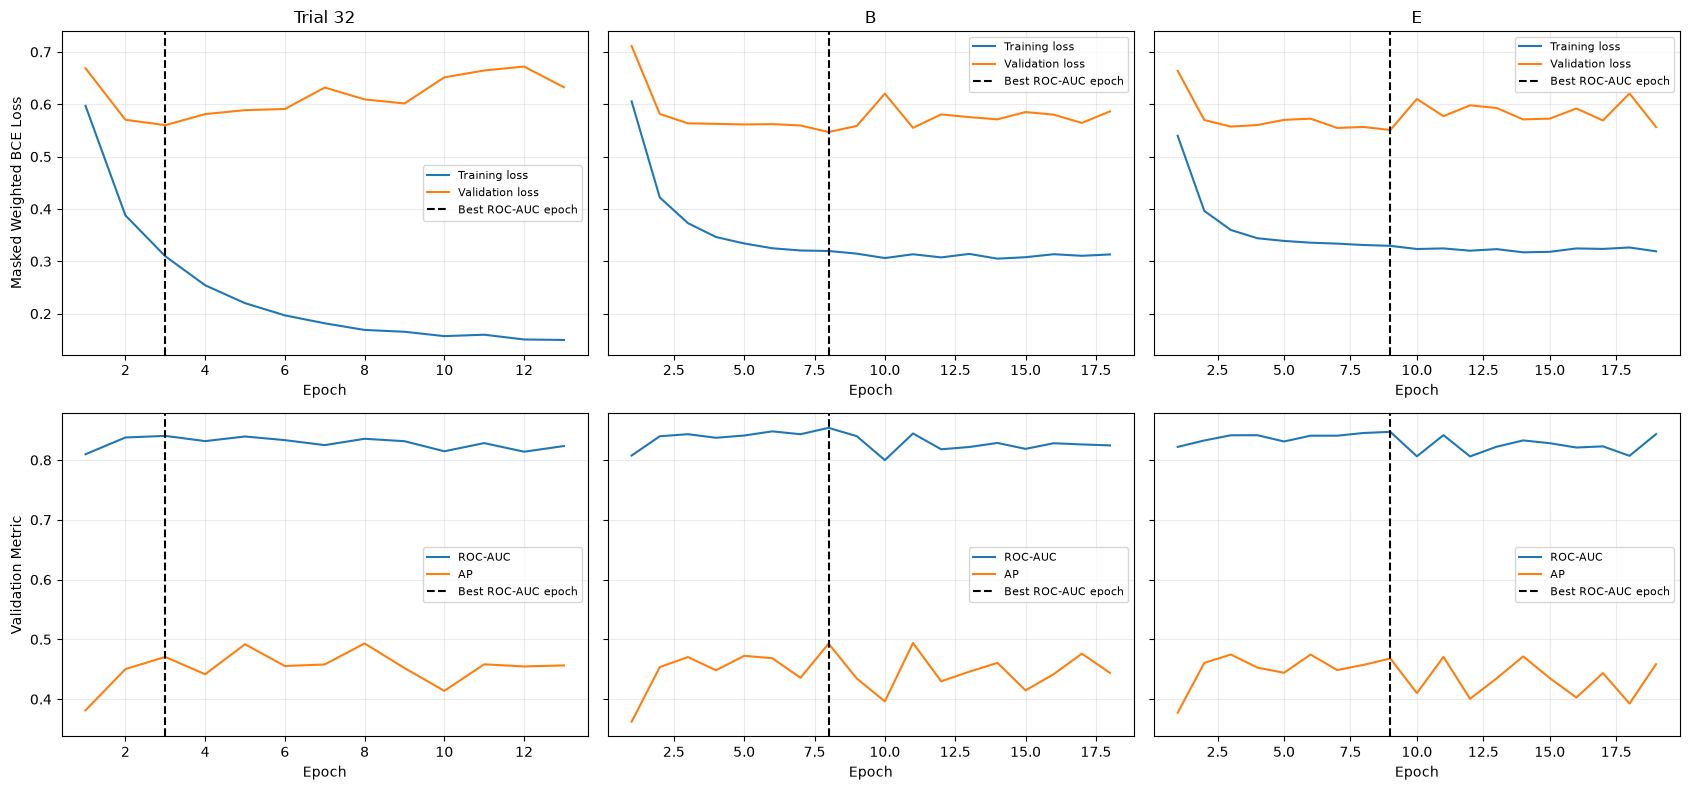

In [98]:
# Compare learning curves under stronger regularization
# validation loss의 급격한 증가 현상이 더 강한 weight decay를 적용한 B와 E에서 얼마나 완화됐는지 (Validation loss가 증가하기 시작하는 시점이 늦어졌는가? / Training loss와 validation loss의 차이가 줄어들었는가? / ROC-AUC와 AP가 더 오랫동안 개선되는가?)

curve_source_dirs = {
    "Trial 32": robustness_source_dirs["Trial_32"],
    "B": robustness_source_dirs["B_Highest_WD"],
    "E": robustness_source_dirs["E_Wider_Highest_WD"],
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 8),
    sharey="row",
)

for i, (name, source_dir) in enumerate(
    curve_source_dirs.items()
):

    history = pd.read_csv(
        source_dir / "history_df.csv"
    )

    folds = pd.read_csv(
        source_dir / "fold_df.csv"
    )

    h = history.loc[
        history["fold_id"] == 0
    ].sort_values("epoch")

    best_epoch = int(
        folds.loc[
            folds["fold_id"] == 0,
            "best_epoch",
        ].iloc[0]
    )

    # Training and validation loss
    axes[0, i].plot(
        h["epoch"],
        h["train_loss"],
        label="Training loss",
    )

    axes[0, i].plot(
        h["epoch"],
        h["val_loss"],
        label="Validation loss",
    )

    # Validation performance
    axes[1, i].plot(
        h["epoch"],
        h["val_mean_roc_auc"],
        label="ROC-AUC",
    )

    axes[1, i].plot(
        h["epoch"],
        h["val_mean_ap"],
        label="AP",
    )

    axes[0, i].set_title(name)

    for ax in axes[:, i]:

        ax.axvline(
            best_epoch,
            color="black",
            linestyle="--",
            label="Best ROC-AUC epoch",
        )

        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

axes[0, 0].set_ylabel("Masked Weighted BCE Loss")
axes[1, 0].set_ylabel("Validation Metric")

plt.tight_layout()
plt.show()

In [ ]:
# Trial 32, B, E 모두 동일한 seed, Fold 0, pos_weight_cap=5를 사용
# B와 E에서는 training loss가 약 0.3 부근에서 안정되고, validation loss도 초기 감소 이후 크게 증가하지 않음 vs. Trial 32에서는 validation loss가 점진적으로 증가
# 앞서 발견했던 빠른 overfitting 현상이 강한 regularization을 적용하면서 완화됐다는 근거 (weight decay = 0.05 for B, E vs. 0.0087 for Trial 32) -> 이전보다 과도한 학습이 억제되고 CV 성능도 개선

In [99]:
# Save the final model selection before holdout evaluation

final_results_dir = (
    dl_results_dir / "final_model_v1"
)

final_results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

final_model_spec = {
    "selected_candidate": FINAL_CANDIDATE,
    "selection_metric": "multi_seed_mean_roc_auc",
    "cv_config": final_config,
    "final_training_epochs": FINAL_EPOCHS,
    "final_training_seed": FINAL_SEED,
    "n_parameters": final_n_parameters,
    "robustness_seeds": ROBUSTNESS_SEEDS,
    "epoch_selection_rule": "median_of_all_seed_fold_best_epochs",
    "cv_macro_roc_auc_mean": float(
        selected_robustness["roc_auc_mean"]
    ),
    "cv_macro_roc_auc_seed_std": float(
        selected_robustness["roc_auc_seed_std"]
    ),
    "cv_macro_ap_mean": float(
        selected_robustness["ap_mean"]
    ),
    "cv_macro_ap_seed_std": float(
        selected_robustness["ap_seed_std"]
    ),
}

with (final_results_dir / "final_model_spec.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        final_model_spec,
        f,
        indent=4,
        allow_nan=False,
    )

final_epoch_df.to_csv(
    final_results_dir / "cv_epoch_selection.csv",
    index=False,
)

print("Final model specification saved.")

Final model specification saved.


# [15] Final Model Training & Holdout Evaluation

## Final Data Preprocessing

In [ ]:
# Import final training utilities

from tox21_dl.training import fit_final_tox21_mlp

from tox21_dl.preprocessing import (
    fit_descriptor_scaler,
    transform_features,
)

In [101]:
# Prepare the full development dataset

assert train_df.index.equals(X_train_all.index)
assert train_df.index.is_unique

assert len(train_df) == 6433
assert X_train_all.shape == (6433, 2059)

# Fit the final descriptor scaler.
scaler_final = fit_descriptor_scaler(
    X_train_all
)

# Transform development features.
X_train_final = transform_features(
    X_train_all,
    scaler_final,
)

# Preserve missing endpoint labels.
y_train_final = train_df[
    target_cols
].to_numpy(
    dtype=np.float32,
    na_value=np.nan,
)

# Verify shapes and data types.
assert X_train_final.shape == (6433, 2059)
assert y_train_final.shape == (6433, 12)

assert X_train_final.dtype == np.float32
assert y_train_final.dtype == np.float32

assert np.isfinite(X_train_final).all()

assert np.all(
    np.isnan(y_train_final)
    | (y_train_final == 0)
    | (y_train_final == 1)
)

# Confirm that Morgan fingerprint bits remain unchanged.
assert np.array_equal(
    X_train_final[:, :2048],
    X_train_all.iloc[:, :2048].to_numpy(),
)

print("Final training features:", X_train_final.shape)
print("Final training labels:", y_train_final.shape)
print("Missing labels:", np.isnan(y_train_final).sum())
print("Valid labels:", np.isfinite(y_train_final).sum())

print("\nAll final preprocessing checks passed.")

Final training features: (6433, 2059)
Final training labels: (6433, 12)
Missing labels: 12575
Valid labels: 64621

All final preprocessing checks passed.


## Final Model Training

In [102]:
# Load the previously selected final model specification

with (final_results_dir / "final_model_spec.json").open(
    "r", encoding="utf-8"
) as f:
    final_spec_loaded = json.load(f)

final_training_config = dict(
    final_spec_loaded["cv_config"]
)

final_training_config["hidden_dims"] = tuple(
    final_training_config["hidden_dims"]
)

# Remove settings specific to CV and early stopping.
final_training_config.pop("max_epochs")
final_training_config.pop("patience")
final_training_config.pop("selection_metric")

# Use the predetermined training duration.
final_training_config["epochs"] = int(
    final_spec_loaded["final_training_epochs"]
)

final_training_config["seed"] = int(
    final_spec_loaded["final_training_seed"]
)

final_training_config["verbose"] = True

assert final_training_config["epochs"] == 6
assert final_training_config["seed"] == 42

display(
    pd.DataFrame([final_training_config]).T
)

,0
seed,42
device,cpu
verbose,True
hidden_dims,"(2048, 1024)"
dropout,0.372731
weight_decay,0.05
lr,0.000392
batch_size,128
pos_weight_cap,5.0
epochs,6


In [103]:
# Train the final model on all development molecules

start_final_training = perf_counter()

(
    model_final,
    history_final,
    pos_weight_final,
) = fit_final_tox21_mlp(
    X_train=X_train_final,
    y_train=y_train_final,
    task_names=target_cols,
    **final_training_config,
)

elapsed_final_training = (
    perf_counter() - start_final_training
)

print(
    f"\nFinal training time: "
    f"{elapsed_final_training:.2f} seconds"
)

display(history_final.round(6))

Epoch 001/006 | train_loss=0.5401
Epoch 002/006 | train_loss=0.4164
Epoch 003/006 | train_loss=0.3826
Epoch 004/006 | train_loss=0.3763
Epoch 005/006 | train_loss=0.3705
Epoch 006/006 | train_loss=0.3668

Final training time: 11.92 seconds


,epoch,train_loss
0,1,0.540068
1,2,0.416395
2,3,0.382591
3,4,0.376340
4,5,0.370470
5,6,0.366837


In [104]:
# Verify final training results

assert len(history_final) == FINAL_EPOCHS

assert history_final["epoch"].tolist() == list(
    range(1, FINAL_EPOCHS + 1)
)

assert np.isfinite(
    history_final["train_loss"]
).all()

assert not model_final.training

assert all(
    torch.isfinite(p).all().item()
    for p in model_final.parameters()
)

# Verify output shape using development features only.
with torch.no_grad():

    sample_x = torch.as_tensor(
        X_train_final[:8],
        dtype=torch.float32,
        device=next(model_final.parameters()).device,
    )

    sample_logits = model_final(sample_x)

assert sample_logits.shape == (8, 12)
assert torch.isfinite(sample_logits).all()

# Verify the final number of trainable parameters.
n_parameters_final = sum(
    p.numel()
    for p in model_final.parameters()
    if p.requires_grad
)

assert n_parameters_final == final_spec_loaded[
    "n_parameters"
]

# Inspect development-derived class weights.
final_class_weights_df = pd.DataFrame({
    "task": target_cols,
    "n_positive": (y_train_final == 1).sum(axis=0),
    "n_negative": (y_train_final == 0).sum(axis=0),
    "n_missing": np.isnan(y_train_final).sum(axis=0),
    "pos_weight": pos_weight_final.numpy(),
})

display(final_class_weights_df.round(4))

print("Trainable parameters:", n_parameters_final)
print("Output shape:", sample_logits.shape)

print("\nAll final model training checks passed.")

,task,n_positive,n_negative,n_missing,pos_weight
0,SR-HSE,252,5143,1038,5.0
1,NR-AR,214,5757,462,5.0
2,SR-ARE,702,4164,1567,5.0
3,NR-Aromatase,206,4672,1555,5.0
4,NR-ER-LBD,236,5502,695,5.0
5,NR-AhR,560,4840,1033,5.0
6,SR-MMP,675,4168,1590,5.0
7,NR-ER,511,4551,1371,5.0
8,NR-PPAR-gamma,125,5271,1037,5.0
9,SR-p53,281,5332,820,5.0


Trainable parameters: 6335500
Output shape: torch.Size([8, 12])

All final model training checks passed.


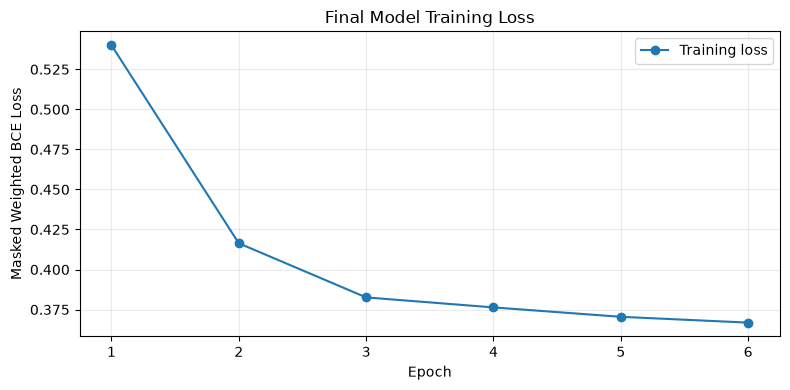

In [105]:
# Visualize the final training loss

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    history_final["epoch"],
    history_final["train_loss"],
    marker="o",
    label="Training loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Masked Weighted BCE Loss")
ax.set_title("Final Model Training Loss")

ax.set_xticks(history_final["epoch"])
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [106]:
# Save the trained model before holdout evaluation

import joblib

torch.save(
    model_final.state_dict(),
    final_results_dir / "model_state.pt",
)

joblib.dump(
    scaler_final,
    final_results_dir / "descriptor_scaler.joblib",
)

history_final.to_csv(
    final_results_dir / "training_history.csv",
    index=False,
)

final_class_weights_df.to_csv(
    final_results_dir / "class_weights.csv",
    index=False,
)

training_metadata = {
    "config": final_training_config,
    "feature_cols": X_train_all.columns.tolist(),
    "target_cols": list(target_cols),
    "n_train": len(X_train_final),
    "n_parameters": n_parameters_final,
    "elapsed_seconds": elapsed_final_training,
}

with (final_results_dir / "training_metadata.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        training_metadata,
        f,
        indent=4,
        allow_nan=False,
    )

print("Final trained model and scaler saved.")

Final trained model and scaler saved.


## Final Holdout Evaluation

In [107]:
# Restore the saved final model and descriptor scaler

import json
import joblib
import torch

from tox21_dl.models import Tox21MLP
from tox21_dl.preprocessing import transform_features
from tox21_dl.training import create_dataloader

from tox21_dl.evaluation import (
    predict,
    compute_multitask_metrics,
)

with (final_results_dir / "training_metadata.json").open(
    "r", encoding="utf-8"
) as f:
    saved_training_metadata = json.load(f)

saved_config = saved_training_metadata["config"]

evaluation_device = torch.device("cpu")

model_holdout = Tox21MLP(
    input_dim=len(saved_training_metadata["feature_cols"]),
    n_tasks=len(saved_training_metadata["target_cols"]),
    hidden_dims=tuple(saved_config["hidden_dims"]),
    dropout=saved_config["dropout"],
).to(evaluation_device)

# Restore weights and BatchNorm buffers.
model_holdout.load_state_dict(
    torch.load(
        final_results_dir / "model_state.pt",
        map_location=evaluation_device,
        weights_only=True,
    ),
    strict=True,
)

model_holdout.eval()

# Restore the development-fitted scaler.
scaler_holdout = joblib.load(
    final_results_dir / "descriptor_scaler.joblib"
)

assert not model_holdout.training

# Verify the restored model using development features.
with torch.no_grad():

    restored_logits = model_holdout(sample_x)

torch.testing.assert_close(
    restored_logits,
    sample_logits,
    rtol=1e-6,
    atol=1e-6,
)

print("Saved model restored successfully.")
print("Saved descriptor scaler restored successfully.")
print("Model restoration check passed.")

Saved model restored successfully.
Saved descriptor scaler restored successfully.
Model restoration check passed.


In [108]:
# Prepare the fixed outer holdout dataset

assert len(test_df) == 1608

assert test_df.index.equals(X_test_all.index)
assert test_df.index.is_unique

assert set(train_df["canonical_smiles"]).isdisjoint(
    test_df["canonical_smiles"]
)

assert set(train_df["scaffold"]).isdisjoint(
    test_df["scaffold"]
)

# Verify the original feature and endpoint order.
assert X_test_all.columns.tolist() == (
    saved_training_metadata["feature_cols"]
)

assert list(target_cols) == (
    saved_training_metadata["target_cols"]
)

# Transform features without fitting a new scaler.
X_test_final = transform_features(
    X_test_all,
    scaler_holdout,
)

# Preserve missing endpoint labels.
y_test_final = test_df[
    target_cols
].to_numpy(
    dtype=np.float32,
    na_value=np.nan,
)

assert X_test_final.shape == (1608, 2059)
assert y_test_final.shape == (1608, 12)

assert np.isfinite(X_test_final).all()

assert np.all(
    np.isnan(y_test_final)
    | (y_test_final == 0)
    | (y_test_final == 1)
)

assert np.array_equal(
    X_test_final[:, :2048],
    X_test_all.iloc[:, :2048].to_numpy(),
)

print("Holdout features:", X_test_final.shape)
print("Holdout labels:", y_test_final.shape)
print("Missing labels:", np.isnan(y_test_final).sum())
print("Valid labels:", np.isfinite(y_test_final).sum())

print("\nAll holdout preprocessing checks passed.")

Holdout features: (1608, 2059)
Holdout labels: (1608, 12)
Missing labels: 4592
Valid labels: 14704

All holdout preprocessing checks passed.


In [ ]:
# 최종 Holdout 데이터 특성:
# Development - Missing label ratio 16.29% (64,621 valid / 77,196 total)
# Holdout - Missing label ratio 23.80% (14,704 valid / 19,296 total)

In [ ]:
# Generate predictions on the outer holdout dataset
# scaler는 이미 development dataset에서 fit된 상태이므로 holdout dataset에서는 transform만 수행
holdout_loader = create_dataloader(
    X_test_final,
    y_test_final,
    batch_size=saved_config["batch_size"],
    training=False,
    seed=saved_config["seed"],
)

start_holdout = perf_counter()

(
    holdout_probs,
    holdout_y_true,
    holdout_mask,
) = predict(
    model_holdout,
    holdout_loader,
    evaluation_device,
)

holdout_probs = np.asarray(holdout_probs)
holdout_y_true = np.asarray(holdout_y_true)
holdout_mask = np.asarray(holdout_mask, dtype=bool)

# Verify prediction shape and label alignment.
assert holdout_probs.shape == (1608, 12)
assert holdout_y_true.shape == (1608, 12)
assert holdout_mask.shape == (1608, 12)

assert np.isfinite(holdout_probs).all()

assert np.all(
    (holdout_probs >= 0)
    & (holdout_probs <= 1)
)

assert np.array_equal(
    holdout_mask,
    ~np.isnan(y_test_final),
)

assert np.array_equal(
    holdout_y_true[holdout_mask],
    y_test_final[holdout_mask],
)

# Calculate endpoint-level and macro metrics.
holdout_metrics = compute_multitask_metrics(
    holdout_probs,
    holdout_y_true,
    holdout_mask,
    target_cols,
)

elapsed_holdout = perf_counter() - start_holdout

holdout_per_task_df = (
    holdout_metrics["per_task_df"].copy()
)

display(holdout_per_task_df.round(6))

print(
    "\nHoldout Macro ROC-AUC:",
    holdout_metrics["mean_roc_auc"],
)

print(
    "Holdout Macro AP:",
    holdout_metrics["mean_ap"],
)

print(
    "Valid endpoints:",
    holdout_metrics["n_valid_tasks"],
    "/",
    len(target_cols),
)

print(
    "Evaluation time:",
    round(elapsed_holdout, 2),
    "seconds",
)

,task,roc_auc,ap,n_valid,n_positive,n_negative,n_missing,positive_ratio,status
0,SR-HSE,0.745267,0.197196,1178,85,1093,430,0.072156,ok
1,NR-AR,0.816389,0.421050,1446,47,1399,162,0.032503,ok
2,SR-ARE,0.770629,0.441364,1042,216,826,566,0.207294,ok
3,NR-Aromatase,0.811959,0.390079,1060,79,981,548,0.074528,ok
4,NR-ER-LBD,0.848917,0.415781,1344,67,1277,264,0.049851,ok
5,NR-AhR,0.822105,0.515572,1270,182,1088,338,0.143307,ok
6,SR-MMP,0.853600,0.593151,1062,231,831,546,0.217514,ok
7,NR-ER,0.753625,0.441025,1133,151,982,475,0.133274,ok
8,NR-PPAR-gamma,0.768541,0.250299,1195,50,1145,413,0.041841,ok
9,SR-p53,0.770118,0.300391,1296,130,1166,312,0.100309,ok



Holdout Macro ROC-AUC: 0.7977387791568953
Holdout Macro AP: 0.38025181111950124
Valid endpoints: 12 / 12
Evaluation time: 0.14 seconds


In [110]:
# Verify holdout metric aggregation

assert len(holdout_per_task_df) == len(target_cols)

assert holdout_per_task_df["task"].tolist() == list(
    target_cols
)

assert holdout_per_task_df["status"].eq("ok").all()

assert holdout_metrics["n_valid_tasks"] == 12

assert np.isclose(
    holdout_metrics["mean_roc_auc"],
    holdout_per_task_df["roc_auc"].mean(),
)

assert np.isclose(
    holdout_metrics["mean_ap"],
    holdout_per_task_df["ap"].mean(),
)

# Compare development CV and holdout performance.
holdout_macro_auc = float(
    holdout_metrics["mean_roc_auc"]
)

holdout_macro_ap = float(
    holdout_metrics["mean_ap"]
)

holdout_macro_ap_baseline = float(
    holdout_per_task_df["positive_ratio"].mean()
)

cv_holdout_comparison_df = pd.DataFrame([
    {
        "dataset": "Development CV (3 seeds)",
        "macro_roc_auc": final_spec_loaded[
            "cv_macro_roc_auc_mean"
        ],
        "macro_ap": final_spec_loaded[
            "cv_macro_ap_mean"
        ],
        "macro_ap_baseline": float(
            robustness_seed_df[
                "cv_macro_ap_baseline"
            ].mean()
        ),
    },
    {
        "dataset": "Outer holdout",
        "macro_roc_auc": holdout_macro_auc,
        "macro_ap": holdout_macro_ap,
        "macro_ap_baseline": holdout_macro_ap_baseline,
    },
])

display(cv_holdout_comparison_df.round(6))

print("\nAll final holdout evaluation checks passed.")

,dataset,macro_roc_auc,macro_ap,macro_ap_baseline
0,Development CV (3 seeds),0.820937,0.393949,0.073397
1,Outer holdout,0.797739,0.380252,0.096449



All final holdout evaluation checks passed.


In [ ]:
# Holdout evaluation summary
# Holdout에서 E_Wider_Highest_WD 모델은 CV에서의 평균 성능보다 낮은 Macro ROC-AUC와 Macro AP를 기록했음
# possible reasons: 
# 1.CV에서는 동일한 validation folds를 반복적으로 이용하여 hyperparameter와 best epoch를 선택
# 2.holdout에는 development dataset에서 학습하지 않은 scaffold가 존재
# 3.CV 성능은 3개 seed의 평균이지만, holdout 성능은 seed 42의 단일 최종 모델 결과
# 4.Endpoint별 class distribution과 화학적 구조 분포가 다름

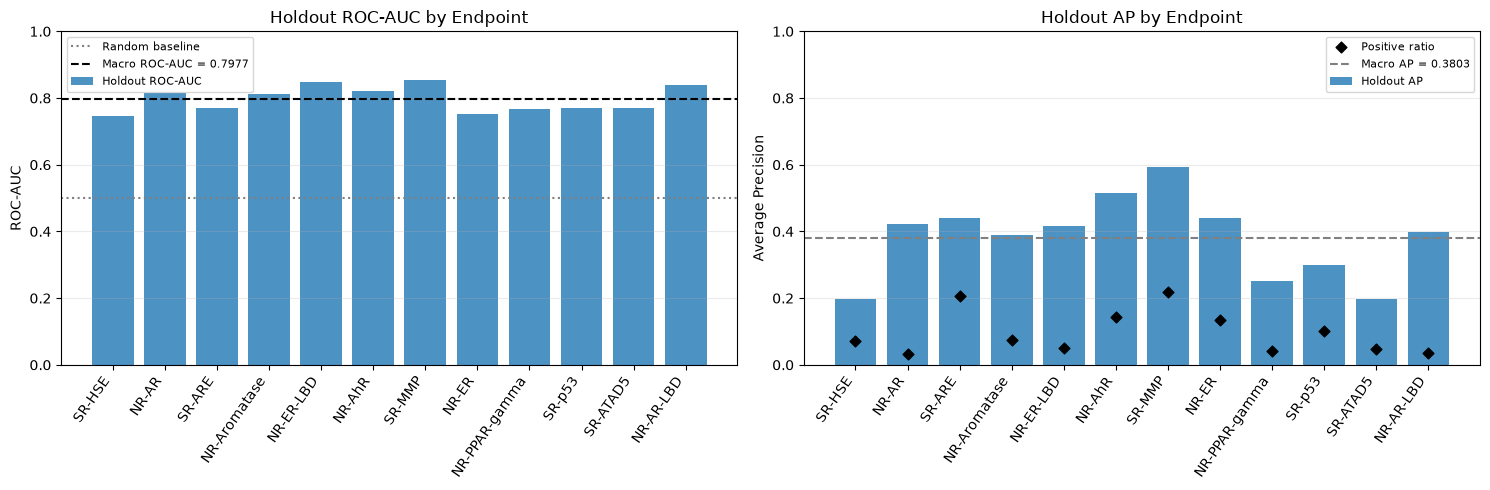

In [111]:
# Visualize endpoint-level holdout performance

plot_df = holdout_per_task_df.copy()

x = np.arange(len(plot_df))

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
)

# ROC-AUC
axes[0].bar(
    x,
    plot_df["roc_auc"],
    alpha=0.8,
    label="Holdout ROC-AUC",
)

axes[0].axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Random baseline",
)

axes[0].axhline(
    holdout_macro_auc,
    color="black",
    linestyle="--",
    label=f"Macro ROC-AUC = {holdout_macro_auc:.4f}",
)

axes[0].set_title("Holdout ROC-AUC by Endpoint")
axes[0].set_ylabel("ROC-AUC")

# Average Precision
axes[1].bar(
    x,
    plot_df["ap"],
    alpha=0.8,
    label="Holdout AP",
)

axes[1].scatter(
    x,
    plot_df["positive_ratio"],
    marker="D",
    color="black",
    s=30,
    label="Positive ratio",
    zorder=5,
)

axes[1].axhline(
    holdout_macro_ap,
    color="gray",
    linestyle="--",
    label=f"Macro AP = {holdout_macro_ap:.4f}",
)

axes[1].set_title("Holdout AP by Endpoint")
axes[1].set_ylabel("Average Precision")

for ax in axes:

    ax.set_xticks(x)

    ax.set_xticklabels(
        plot_df["task"],
        rotation=55,
        ha="right",
    )

    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# 12개 endpoint 중 6개가 ROC-AUC 0.8 이상
# 가장 낮은 SR-HSE도 ROC-AUC 0.7453을 기록
# 모든 endpoint에서 AP가 각각의 positive ratio baseline보다 높음
# SR-MMP가 ROC-AUC와 AP 모두 가장 높음

In [112]:
# Export final holdout evaluation results

holdout_per_task_df.to_csv(
    final_results_dir / "holdout_per_task_metrics.csv",
    index=False,
)

cv_holdout_comparison_df.to_csv(
    final_results_dir / "cv_holdout_comparison.csv",
    index=False,
)

holdout_summary = {
    "selected_candidate": final_spec_loaded[
        "selected_candidate"
    ],
    "n_test": len(test_df),
    "n_tasks": len(target_cols),
    "n_valid_tasks": int(
        holdout_metrics["n_valid_tasks"]
    ),
    "holdout_macro_roc_auc": holdout_macro_auc,
    "holdout_macro_ap": holdout_macro_ap,
    "holdout_macro_ap_baseline": holdout_macro_ap_baseline,
    "elapsed_seconds": elapsed_holdout,
}

with (final_results_dir / "holdout_summary.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        holdout_summary,
        f,
        indent=4,
        allow_nan=False,
    )

# Save molecule-level predictions in long format.
holdout_predictions_df = pd.DataFrame({
    "canonical_smiles": np.repeat(
        test_df["canonical_smiles"].to_numpy(),
        len(target_cols),
    ),
    "scaffold": np.repeat(
        test_df["scaffold"].to_numpy(),
        len(target_cols),
    ),
    "task": np.tile(
        target_cols,
        len(test_df),
    ),
    "y_true": y_test_final.ravel(),
    "y_score": holdout_probs.ravel(),
    "label_available": holdout_mask.ravel(),
})

assert len(holdout_predictions_df) == 1608 * 12

holdout_predictions_df.to_csv(
    final_results_dir / "holdout_predictions.csv",
    index=False,
)

print("Saved predictions:", len(holdout_predictions_df))
print("All final holdout results saved.")

Saved predictions: 19296
All final holdout results saved.


## Final Result & Artifact Verification

In [113]:
# Verify all final model and evaluation artifacts

required_artifacts = [
    "final_model_spec.json",
    "cv_epoch_selection.csv",
    "model_state.pt",
    "descriptor_scaler.joblib",
    "training_history.csv",
    "class_weights.csv",
    "training_metadata.json",
    "holdout_per_task_metrics.csv",
    "cv_holdout_comparison.csv",
    "holdout_summary.json",
    "holdout_predictions.csv",
]

artifact_rows = []

for filename in required_artifacts:

    path = final_results_dir / filename

    assert path.is_file(), f"Missing artifact: {filename}"
    assert path.stat().st_size > 0

    artifact_rows.append({
        "filename": filename,
        "size_kb": path.stat().st_size / 1024,
        "status": "ok",
    })

final_artifact_df = pd.DataFrame(artifact_rows)

display(final_artifact_df.round(2))

print("All final artifacts verified.")

,filename,size_kb,status
0,final_model_spec.json,0.96,ok
1,cv_epoch_selection.csv,2.41,ok
2,model_state.pt,24777.76,ok
3,descriptor_scaler.joblib,1.20,ok
4,training_history.csv,0.15,ok
5,class_weights.csv,0.37,ok
6,training_metadata.json,39.92,ok
7,holdout_per_task_metrics.csv,1.11,ok
8,cv_holdout_comparison.csv,0.20,ok
9,holdout_summary.json,0.31,ok


All final artifacts verified.


In [114]:
# Reproduce holdout metrics from saved predictions

saved_predictions = pd.read_csv(
    final_results_dir / "holdout_predictions.csv",
    keep_default_na=False,
)

assert len(saved_predictions) == 1608 * 12

# Verify molecule and endpoint order.
assert np.array_equal(
    saved_predictions["canonical_smiles"].to_numpy(),
    np.repeat(
        test_df["canonical_smiles"].to_numpy(),
        len(target_cols),
    ),
)

assert np.array_equal(
    saved_predictions["task"].to_numpy(),
    np.tile(target_cols, len(test_df)),
)

# Restore prediction and label matrices.
saved_scores = (
    saved_predictions["y_score"]
    .to_numpy(dtype=float)
    .reshape(len(test_df), len(target_cols))
)

saved_labels = (
    pd.to_numeric(
        saved_predictions["y_true"].replace("", np.nan)
    )
    .to_numpy(dtype=float)
    .reshape(len(test_df), len(target_cols))
)

saved_mask = ~np.isnan(saved_labels)

assert np.array_equal(saved_mask, holdout_mask)

np.testing.assert_allclose(
    saved_labels,
    y_test_final,
    equal_nan=True,
)

np.testing.assert_allclose(
    saved_scores,
    holdout_probs,
    rtol=1e-6,
    atol=1e-8,
)

# Recalculate metrics using saved predictions only.
saved_metrics = compute_multitask_metrics(
    saved_scores,
    np.where(saved_mask, saved_labels, 0.0),
    saved_mask,
    target_cols,
)

assert np.isclose(
    saved_metrics["mean_roc_auc"],
    holdout_macro_auc,
)

assert np.isclose(
    saved_metrics["mean_ap"],
    holdout_macro_ap,
)

pd.testing.assert_frame_equal(
    saved_metrics["per_task_df"],
    holdout_per_task_df,
    check_dtype=False,
    rtol=1e-6,
    atol=1e-8,
)

print("Reproduced ROC-AUC:", saved_metrics["mean_roc_auc"])
print("Reproduced AP:", saved_metrics["mean_ap"])

print("\nAll saved prediction checks passed.")

Reproduced ROC-AUC: 0.7977387791568953
Reproduced AP: 0.38025181111950124

All saved prediction checks passed.


# version 5 - weight decay (1e-5 -> 1e-4)
모델의 weight(가중치)가 너무 커지지 않게 억제하는 규제(regularization)

`Loss = BCE loss + λ * ||w||²`

모델이 train 데이터에 과하게 맞춤 (overfitting) → weight 값이 점점 커짐

예: w = [0.1, 0.2, 0.3] → [2.5, -3.1, 4.8] → 더 커짐

이런 모델은: train 성능 ↑ / val/test 성능 ↓
-> weight decay: "weight를 너무 크게 만들지 마라"